# Physics-Guided, Uncertainty-Calibrated and Explainable Deep Learning for Factor-of-Safety Prediction of Mine Dump Slopes

**Model:** Physics-Guided, Uncertainty-Calibrated Multilayer Perceptron (PGUC-MLP)  
**Predictors:** $c$, $\phi$, $\gamma$, $H$, $\beta$, $w$  
**Target:** Factor of Safety (FOS)

Run the notebook sequentially. The calibration and test subsets are not used during model development.

## 1. Environment and Project Configuration

### 1.1 Install required packages

In [1]:
%pip install -q openpyxl optuna "shap>=0.47" shapiq joblib seaborn statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.1/55.1 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 28.0 MB/s eta 0:00:00


### 1.2 Mount Google Drive and import libraries

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import gc
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import random
import shutil
import warnings
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import shapiq
import torch
import torch.nn as nn

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, FancyArrowPatch
from scipy import stats
from scipy.stats import norm, pearsonr
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

Mounted at /content/drive


### 1.3 Define paths, reproducibility settings and figure style

In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/Reuben_MDSSA")
DATA_PATH = PROJECT_DIR / "Master_datasheet.xlsx"
LOCAL_RUNTIME = Path("/content/PGUC_MLP_runtime")

DIRS = {
    "processed": PROJECT_DIR / "data" / "processed",
    "splits": PROJECT_DIR / "data" / "split_assignments",
    "models": PROJECT_DIR / "models",
    "tables": PROJECT_DIR / "tables",
    "eda": PROJECT_DIR / "figures" / "01_EDA",
    "performance": PROJECT_DIR / "figures" / "02_Performance",
    "uncertainty": PROJECT_DIR / "figures" / "03_Uncertainty",
    "sensitivity": PROJECT_DIR / "figures" / "04_Sensitivity",
    "xai": PROJECT_DIR / "figures" / "05_XAI",
    "shapiq": PROJECT_DIR / "figures" / "06_SHAP_IQ",
    "inflow": PROJECT_DIR / "figures" / "07_InFlow",
}

for folder in [PROJECT_DIR, LOCAL_RUNTIME, *DIRS.values()]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

SEED = 42
ENSEMBLE_SEEDS = [42, 52, 62, 72, 82]
N_SPLITS = 5
N_TRIALS = 40
MAX_EPOCHS_TUNE = 300
MAX_EPOCHS_CV = 400
PATIENCE = 35
SHAP_BACKGROUND_SIZE = 100
SHAPIQ_MAX_ORDER = 3
SHAPIQ_BUDGET = 2 ** 6
SHAPIQ_CHECKPOINT_EVERY = 10
FORCE_RETUNE = False
FORCE_RETRAIN = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

FONT_TITLE = 18
FONT_LABEL = 15
FONT_TICK = 13

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT_TICK,
    "axes.titlesize": FONT_TITLE,
    "axes.titleweight": "bold",
    "axes.labelsize": FONT_LABEL,
    "axes.labelweight": "bold",
    "xtick.labelsize": FONT_TICK,
    "ytick.labelsize": FONT_TICK,
    "legend.fontsize": FONT_TICK,
    "axes.linewidth": 1.4,
    "figure.dpi": 120,
    "savefig.dpi": 600,
})

FEATURES = ["c", "phi", "gamma", "H", "beta", "w"]
SYMBOLS = ["c", "φ", "γ", "H", "β", "w"]
TARGET = "FOS"
SYMBOL_MAP = dict(zip(FEATURES, SYMBOLS))
UNITS = {
    "c": "kPa", "phi": "°", "gamma": "kN/m³",
    "H": "m", "beta": "°", "w": "%", "FOS": "",
}
DISPLAY_LABELS = {
    key: f"{SYMBOL_MAP[key]} ({UNITS[key]})" for key in FEATURES
}
DISPLAY_LABELS[TARGET] = "FOS"

def save_figure(fig, folder, stem):
    paths = []
    for extension in ("png", "pdf", "svg"):
        path = Path(folder) / f"{stem}.{extension}"
        fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=600)
        paths.append(path)
    return paths

def show_table(frame, precision=4, caption=None):
    styler = frame.style.format(precision=precision, na_rep="—")
    styler = styler.set_table_styles([
        {"selector": "caption", "props": [("font-size", "15px"), ("font-weight", "bold")]},
        {"selector": "th", "props": [("font-size", "13px"), ("font-weight", "bold"), ("text-align", "center")]},
        {"selector": "td", "props": [("font-size", "13px"), ("text-align", "center")]},
    ])
    if caption:
        styler = styler.set_caption(caption)
    display(styler)

print(f"Device: {DEVICE}")
print(f"Project directory: {PROJECT_DIR}")

Device: cuda
Project directory: /content/drive/MyDrive/Reuben_MDSSA


## 2. Data Import and Scientific Audit

### 2.1 Inspect the Excel workbook

In [4]:
workbook = pd.ExcelFile(DATA_PATH, engine="openpyxl")
print("Available sheets:", workbook.sheet_names)

SHEET_NAME = workbook.sheet_names[0]
raw_df = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME, engine="openpyxl")

print(f"Selected sheet: {SHEET_NAME}")
print(f"Raw dimensions: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())
display(pd.DataFrame({"Column": raw_df.columns.astype(str)}))

Available sheets: ['Sheet1']
Selected sheet: Sheet1
Raw dimensions: 2,250 rows × 7 columns


,Cohesion (kN/m2),Phi (deg),Unit Weight (kN/m3),Overall Bench Height,Overall Slope angle,Natural Moisture content,FOS
0,13.1284,25.6178,17.4128,60,25,7,1.248020
1,34.9534,19.3220,17.3337,60,25,10,1.200020
2,13.5978,33.8177,19.0378,60,25,10,1.677000
3,9.0552,20.1532,16.8173,60,25,10,0.947957
4,18.0202,35.9906,18.2459,60,25,6,1.860190


,Column
0,Cohesion (kN/m2)
1,Phi (deg)
2,Unit Weight (kN/m3)
3,Overall Bench Height
4,Overall Slope angle
5,Natural Moisture content
6,FOS


### 2.2 Resolve columns and validate engineering ranges

If automatic matching fails, enter the exact Excel header beside the relevant key in `MANUAL_COLUMN_MAP` and rerun this cell.

In [5]:
MANUAL_COLUMN_MAP = {
    "c": None,
    "phi": None,
    "gamma": None,
    "H": None,
    "beta": None,
    "w": None,
    "FOS": None,
}

ALIASES = {
    "c": ["c", "ckpa", "cohesion", "cohesionkpa"],
    "phi": ["phi", "frictionangle", "internalfrictionangle", "angleofinternalfriction"],
    "gamma": ["gamma", "unitweight", "bulkunitweight", "unitweightknm3"],
    "H": ["h", "hm", "height", "heightm", "dumpheight", "minedumpheight"],
    "beta": ["beta", "slopeangle", "overallslopeangle", "dumpangle"],
    "w": ["w", "moisture", "moisturecontent", "naturalmoisturecontent"],
    "FOS": ["fos", "factorofsafety", "safetyfactor"],
}

def normalise_header(value):
    text = str(value).strip().lower()
    replacements = {"φ": "phi", "ϕ": "phi", "γ": "gamma", "β": "beta"}
    for old, new in replacements.items():
        text = text.replace(old, new)
    return "".join(char for char in text if char.isalnum())

def resolve_column(key):
    if MANUAL_COLUMN_MAP[key] is not None:
        if MANUAL_COLUMN_MAP[key] not in raw_df.columns:
            raise KeyError(f"Manual column not found for {key}: {MANUAL_COLUMN_MAP[key]}")
        return MANUAL_COLUMN_MAP[key]

    normalised = {column: normalise_header(column) for column in raw_df.columns}
    exact = [column for column, name in normalised.items() if name in ALIASES[key]]
    if len(exact) == 1:
        return exact[0]

    aliases = [alias for alias in ALIASES[key] if len(alias) > 1]
    partial = [
        column for column, name in normalised.items()
        if any(alias in name for alias in aliases)
    ]
    if len(partial) == 1:
        return partial[0]
    raise KeyError(f"Could not uniquely resolve {key}. Candidates: {partial}")

resolved_columns = {key: resolve_column(key) for key in [*FEATURES, TARGET]}
mapping_table = pd.DataFrame({
    "Internal name": resolved_columns.keys(),
    "Excel column": resolved_columns.values(),
    "Display symbol": [*SYMBOLS, "FOS"],
})
show_table(mapping_table, caption="Resolved dataset columns")

df = raw_df[[resolved_columns[key] for key in [*FEATURES, TARGET]]].copy()
df.columns = [*FEATURES, TARGET]
df.insert(0, "row_id", np.arange(1, len(df) + 1))

for column in [*FEATURES, TARGET]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

missing_counts = df[[*FEATURES, TARGET]].isna().sum()
if missing_counts.sum() > 0:
    raise ValueError(f"Missing or non-numeric values detected:\n{missing_counts[missing_counts > 0]}")

range_checks = {
    "c": df["c"] >= 0,
    "phi": df["phi"].between(0, 90, inclusive="neither"),
    "gamma": df["gamma"] > 0,
    "H": df["H"] > 0,
    "beta": df["beta"].between(0, 90, inclusive="neither"),
    "w": df["w"] >= 0,
    "FOS": df["FOS"] > 0,
}

invalid = {key: int((~valid).sum()) for key, valid in range_checks.items() if (~valid).any()}
if invalid:
    raise ValueError(f"Physically invalid observations detected: {invalid}")

duplicate_mask = df.duplicated(subset=[*FEATURES, TARGET], keep="first")
exact_duplicates_removed = int(duplicate_mask.sum())
df = df.loc[~duplicate_mask].reset_index(drop=True)

profile_text = (
    df[["c", "phi", "gamma", "w"]]
    .round(8)
    .astype(str)
    .agg("|".join, axis=1)
)
df["profile_group"] = pd.factorize(profile_text, sort=True)[0] + 1
df["stability_class"] = np.where(df[TARGET] >= 1.0, "FOS ≥ 1.0", "FOS < 1.0")
DATA_FINGERPRINT = hashlib.sha256(
    pd.util.hash_pandas_object(df[[*FEATURES, TARGET]], index=False).to_numpy().tobytes()
).hexdigest()

print(f"Analysis rows: {len(df):,}")
print(f"Exact duplicate rows removed: {exact_duplicates_removed}")
print(f"Unique material profiles: {df['profile_group'].nunique():,}")

,Internal name,Excel column,Display symbol
0,c,Cohesion (kN/m2),c
1,phi,Phi (deg),φ
2,gamma,Unit Weight (kN/m3),γ
3,H,Overall Bench Height,H
4,beta,Overall Slope angle,β
5,w,Natural Moisture content,w
6,FOS,FOS,FOS


Analysis rows: 2,250
Exact duplicate rows removed: 0
Unique material profiles: 1,079


### 2.3 Display and export audit tables

In [6]:
audit_table = pd.DataFrame({
    "Audit item": [
        "Raw observations", "Analysis observations", "Exact duplicates removed",
        "Missing values", "Unique material profiles", "Unstable cases (FOS < 1.0)",
        "Stable cases (FOS ≥ 1.0)",
    ],
    "Value": [
        len(raw_df), len(df), exact_duplicates_removed,
        int(df[[*FEATURES, TARGET]].isna().sum().sum()),
        df["profile_group"].nunique(), int((df[TARGET] < 1.0).sum()),
        int((df[TARGET] >= 1.0).sum()),
    ],
})

descriptive_table = (
    df[[*FEATURES, TARGET]]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .T
    .rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
    [["count", "mean", "std", "min", "Q1", "Median", "Q3", "max"]]
)
descriptive_table.index = [*SYMBOLS, "FOS"]
descriptive_table.index.name = "Variable"

show_table(audit_table, precision=0, caption="Dataset audit")
show_table(descriptive_table.reset_index(), caption="Descriptive statistics")

audit_table.to_csv(DIRS["tables"] / "Table_Data_Audit.csv", index=False)
descriptive_table.to_csv(DIRS["tables"] / "Table_Descriptive_Statistics.csv")

with pd.ExcelWriter(DIRS["tables"] / "Data_Audit_and_Descriptive_Statistics.xlsx") as writer:
    audit_table.to_excel(writer, sheet_name="Audit", index=False)
    descriptive_table.to_excel(writer, sheet_name="Descriptive statistics")

,Audit item,Value
0,Raw observations,2250
1,Analysis observations,2250
2,Exact duplicates removed,0
3,Missing values,0
4,Unique material profiles,1079
5,Unstable cases (FOS < 1.0),981
6,Stable cases (FOS ≥ 1.0),1269


,Variable,count,mean,std,min,Q1,Median,Q3,max
0,c,2250.0000,20.8807,9.0851,6.4902,13.5335,19.6936,27.5999,45.6743
1,φ,2250.0000,26.8277,6.0351,13.0856,21.8779,27.0912,31.7897,36.9861
2,γ,2250.0000,17.6828,1.3152,15.2403,16.7952,17.5371,18.3451,22.6325
3,H,2250.0000,88.0000,21.6689,60.0000,60.0000,80.0000,100.0000,120.0000
4,β,2250.0000,32.0000,5.4172,25.0000,25.0000,30.0000,35.0000,40.0000
5,w,2250.0000,7.5009,1.7139,5.0000,6.0000,7.0000,9.0000,10.0000
6,FOS,2250.0000,1.0830,0.3128,0.4190,0.8541,1.0491,1.2840,2.1210


## 3. Exploratory Data Analysis

### 3.1 Predictor and FOS distributions

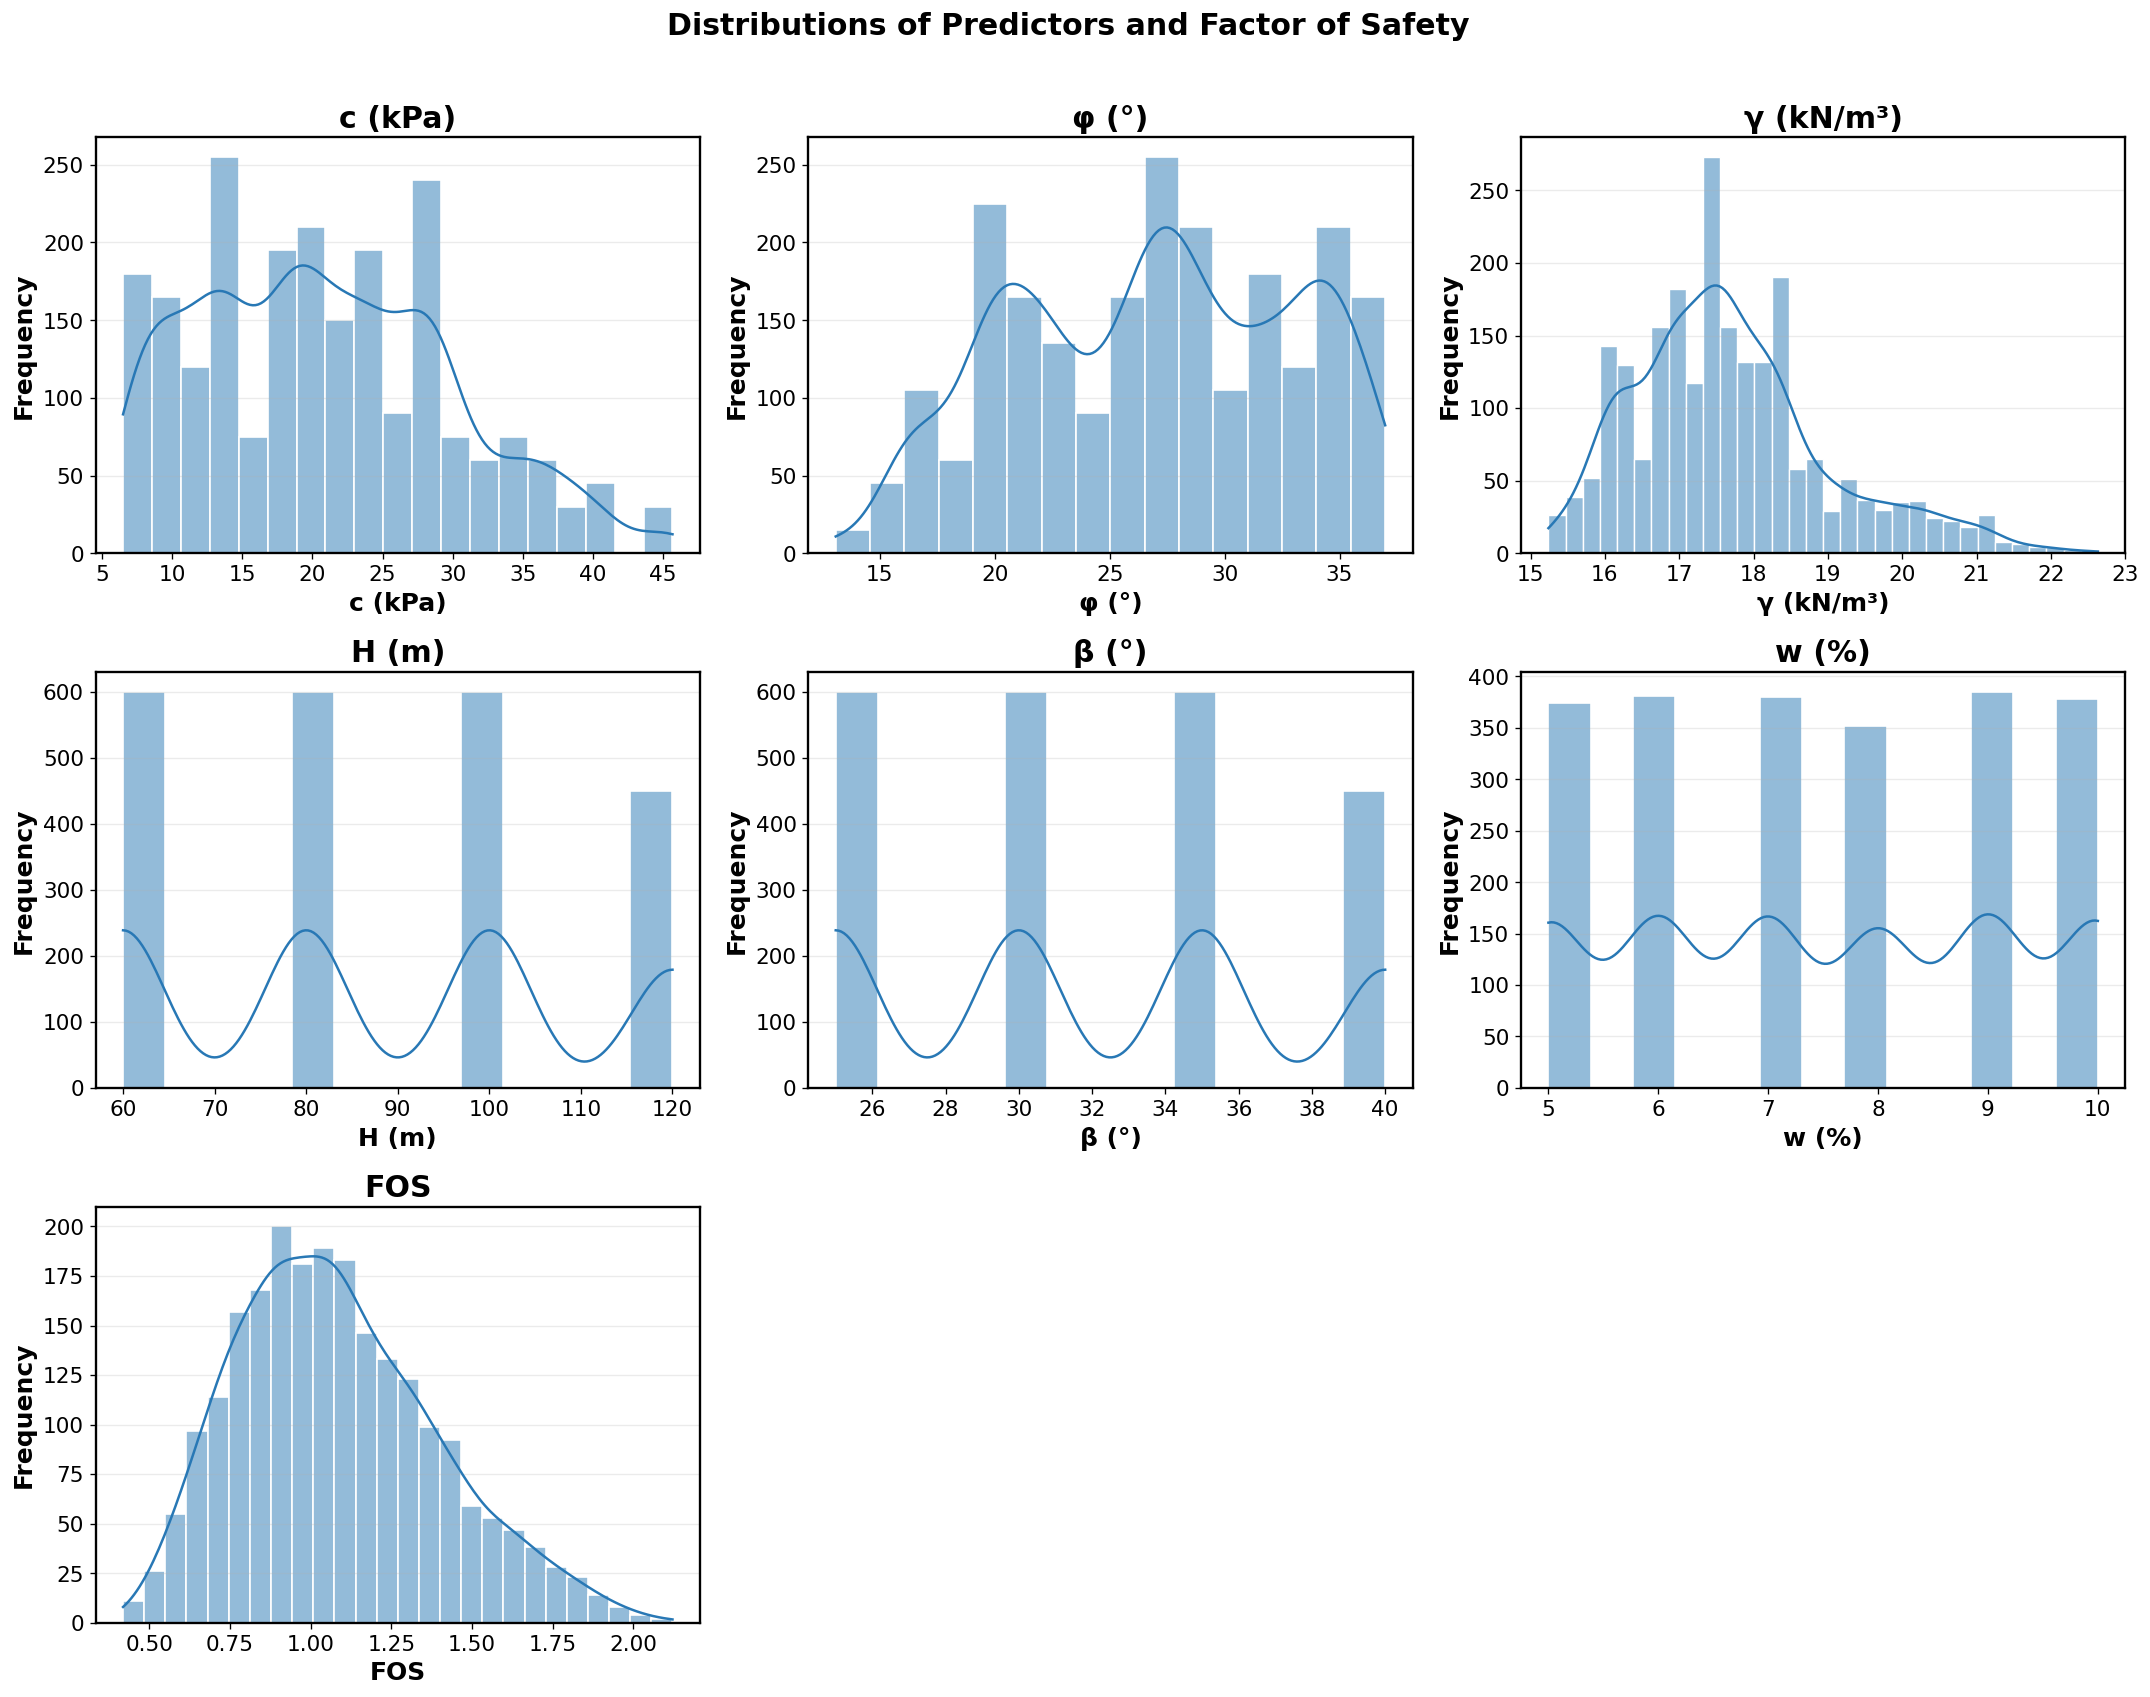

In [7]:
plot_columns = [*FEATURES, TARGET]
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()

for index, column in enumerate(plot_columns):
    sns.histplot(df[column], kde=True, color="#2878B5", edgecolor="white", ax=axes[index])
    axes[index].set_title(DISPLAY_LABELS[column])
    axes[index].set_xlabel(DISPLAY_LABELS[column])
    axes[index].set_ylabel("Frequency")
    axes[index].grid(axis="y", alpha=0.25)

for axis in axes[len(plot_columns):]:
    axis.axis("off")

fig.suptitle("Distributions of Predictors and Factor of Safety", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["eda"], "Figure_01_Distributions")
plt.show()
plt.close(fig)

### 3.2 Pearson correlation matrix

The lower triangle retains signed Pearson coefficients and uses shades of blue.

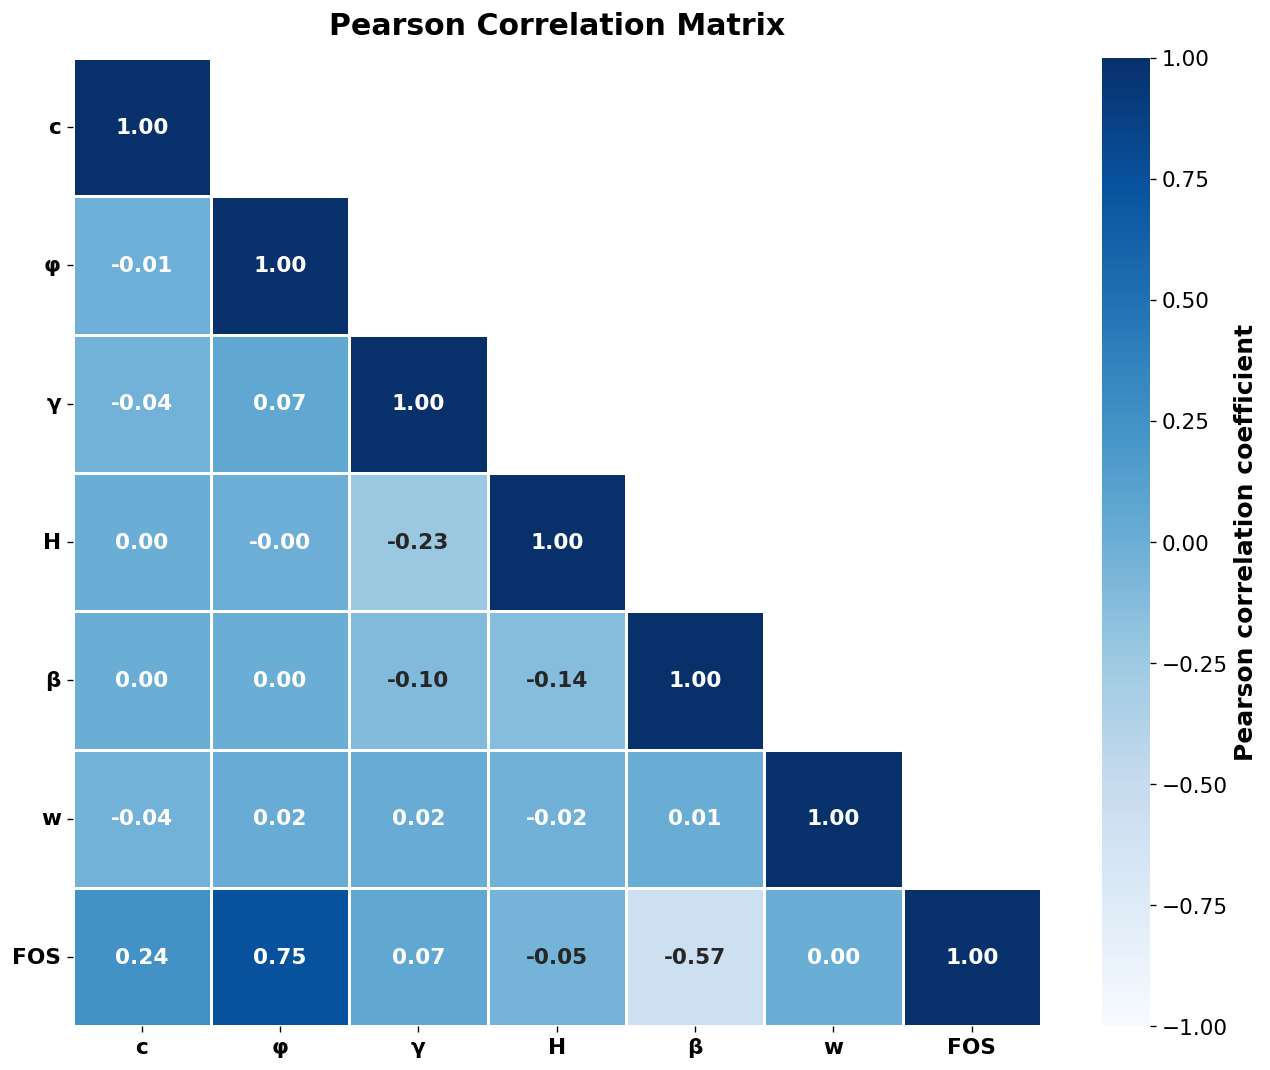

,Variable,c,φ,γ,H,β,w,FOS
0,c,1.0000,-0.0094,-0.0370,0.0000,0.0000,-0.0385,0.2429
1,φ,-0.0094,1.0000,0.0662,-0.0000,0.0000,0.0226,0.7468
2,γ,-0.0370,0.0662,1.0000,-0.2317,-0.1030,0.0194,0.0684
3,H,0.0000,-0.0000,-0.2317,1.0000,-0.1364,-0.0244,-0.0519
4,β,0.0000,0.0000,-0.1030,-0.1364,1.0000,0.0135,-0.5722
5,w,-0.0385,0.0226,0.0194,-0.0244,0.0135,1.0000,0.0039
6,FOS,0.2429,0.7468,0.0684,-0.0519,-0.5722,0.0039,1.0000


In [8]:
corr_data = df[[*FEATURES, TARGET]].rename(columns={**SYMBOL_MAP, TARGET: "FOS"})
corr_matrix = corr_data.corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="Blues",
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": FONT_TICK, "fontweight": "bold"},
    linewidths=0.8,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)
ax.set_title("Pearson Correlation Matrix", pad=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontweight="bold")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontweight="bold")
ax.collections[0].colorbar.ax.tick_params(labelsize=FONT_TICK)
ax.collections[0].colorbar.set_label("Pearson correlation coefficient", fontsize=FONT_LABEL, fontweight="bold")
fig.tight_layout()
save_figure(fig, DIRS["eda"], "Figure_02_Pearson_Correlation")
plt.show()
plt.close(fig)

show_table(corr_matrix.reset_index().rename(columns={"index": "Variable"}), caption="Signed Pearson correlation coefficients")
corr_matrix.to_csv(DIRS["tables"] / "Table_Pearson_Correlation.csv")

### 3.3 FOS response across dump height and slope angle

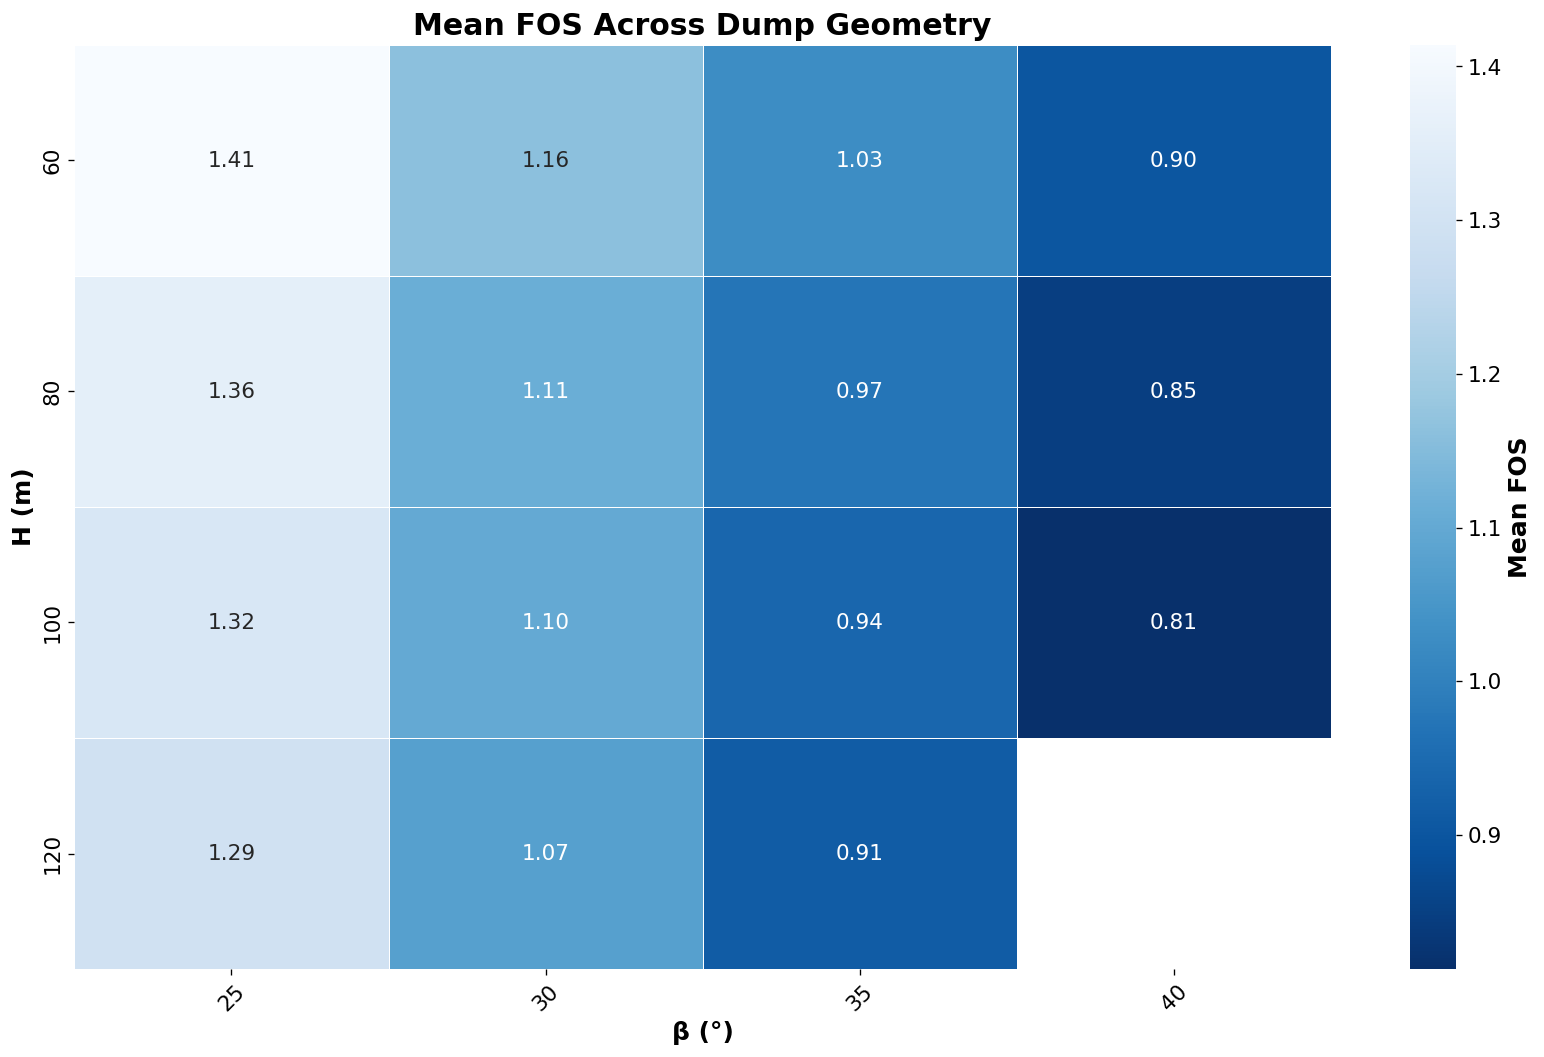

In [9]:
height_values = df["H"].nunique()
angle_values = df["beta"].nunique()

if height_values <= 25 and angle_values <= 25:
    response_table = df.pivot_table(index="H", columns="beta", values=TARGET, aggfunc="mean")
    y_label, x_label = "H (m)", "β (°)"
else:
    temp = df.copy()
    temp["H_bin"] = pd.qcut(temp["H"], q=min(10, height_values), duplicates="drop")
    temp["beta_bin"] = pd.qcut(temp["beta"], q=min(10, angle_values), duplicates="drop")
    response_table = temp.pivot_table(index="H_bin", columns="beta_bin", values=TARGET, aggfunc="mean", observed=False)
    y_label, x_label = "H quantile interval", "β quantile interval"

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(
    response_table,
    cmap="Blues_r",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": FONT_TICK},
    linewidths=0.5,
    cbar_kws={"label": "Mean FOS"},
    ax=ax,
)
ax.set_title("Mean FOS Across Dump Geometry")
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
ax.tick_params(axis="x", rotation=45)
ax.collections[0].colorbar.ax.tick_params(labelsize=FONT_TICK)
ax.collections[0].colorbar.set_label("Mean FOS", fontsize=FONT_LABEL, fontweight="bold")
fig.tight_layout()
save_figure(fig, DIRS["eda"], "Figure_03_FOS_Height_Slope_Angle")
plt.show()
plt.close(fig)

response_table.to_csv(DIRS["tables"] / "Table_FOS_Height_Slope_Angle.csv")

## 4. Group-Aware Data Partitioning

### 4.1 Create the 70:15:15 development–calibration–test split

Material profiles defined by $(c,\phi,\gamma,w)$ remain intact. Candidate group splits are scored for size, FOS mean and stability-class balance.

In [10]:
def split_score(data, development_idx, calibration_idx, test_idx):
    indices = [development_idx, calibration_idx, test_idx]
    desired = np.array([0.70, 0.15, 0.15])
    proportions = np.array([len(idx) / len(data) for idx in indices])
    global_mean = data[TARGET].mean()
    global_std = max(data[TARGET].std(), 1e-12)
    global_unstable = (data[TARGET] < 1.0).mean()
    mean_error = np.mean([abs(data.iloc[idx][TARGET].mean() - global_mean) / global_std for idx in indices])
    class_error = np.mean([abs((data.iloc[idx][TARGET] < 1.0).mean() - global_unstable) for idx in indices])
    return np.abs(proportions - desired).sum() + 0.25 * mean_error + 0.25 * class_error

def create_group_split(data, attempts=500, seed=SEED):
    groups = data["profile_group"].to_numpy()
    if np.unique(groups).size < 10:
        raise ValueError("At least 10 material-profile groups are required for a reliable grouped split.")

    best = None
    for offset in range(attempts):
        first = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed + offset)
        development_idx, remainder_idx = next(first.split(data, groups=groups))
        remainder_groups = groups[remainder_idx]
        second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed + 1000 + offset)
        calibration_rel, test_rel = next(second.split(remainder_idx, groups=remainder_groups))
        calibration_idx = remainder_idx[calibration_rel]
        test_idx = remainder_idx[test_rel]
        score = split_score(data, development_idx, calibration_idx, test_idx)
        if best is None or score < best[0]:
            best = (score, development_idx, calibration_idx, test_idx)
    return best

split_path = DIRS["splits"] / "PGUC_MLP_Group_Aware_Split_Assignments.csv"
split_metadata_path = DIRS["splits"] / "PGUC_MLP_Group_Aware_Split_Metadata.json"

if split_path.exists() and not FORCE_RETRAIN:
    if not split_metadata_path.exists():
        raise RuntimeError("Split metadata is missing. Set FORCE_RETRAIN=True to recreate the split safely.")
    saved_split_metadata = json.loads(split_metadata_path.read_text(encoding="utf-8"))
    if saved_split_metadata.get("data_fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError("The dataset has changed since the split was created. Set FORCE_RETRAIN=True.")
    saved_split = pd.read_csv(split_path)
    if set(saved_split["row_id"]) != set(df["row_id"]):
        raise RuntimeError("Saved split assignments do not match the current cleaned dataset.")
    df = df.drop(columns=["subset"], errors="ignore").merge(saved_split[["row_id", "subset"]], on="row_id", how="left")
else:
    score, development_idx, calibration_idx, test_idx = create_group_split(df)
    df["subset"] = ""
    df.loc[development_idx, "subset"] = "Development"
    df.loc[calibration_idx, "subset"] = "Calibration"
    df.loc[test_idx, "subset"] = "Test"
    df[["row_id", "profile_group", "subset"]].to_csv(split_path, index=False)
    split_metadata_path.write_text(
        json.dumps({"data_fingerprint": DATA_FINGERPRINT, "seed": SEED}, indent=2),
        encoding="utf-8",
    )
    print(f"Selected split score: {score:.5f}")

development_df = df[df["subset"] == "Development"].copy().reset_index(drop=True)
calibration_df = df[df["subset"] == "Calibration"].copy().reset_index(drop=True)
test_df = df[df["subset"] == "Test"].copy().reset_index(drop=True)

df.to_csv(DIRS["processed"] / "PGUC_MLP_Cleaned_Dataset_with_Splits.csv", index=False)
df.to_excel(DIRS["processed"] / "PGUC_MLP_Cleaned_Dataset_with_Splits.xlsx", index=False)

Selected split score: 0.00772


### 4.2 Verify split integrity and display the split table

In [11]:
subset_frames = {
    "Development": development_df,
    "Calibration": calibration_df,
    "Test": test_df,
}

group_sets = {name: set(frame["profile_group"]) for name, frame in subset_frames.items()}
assert group_sets["Development"].isdisjoint(group_sets["Calibration"])
assert group_sets["Development"].isdisjoint(group_sets["Test"])
assert group_sets["Calibration"].isdisjoint(group_sets["Test"])

split_summary = pd.DataFrame([
    {
        "Subset": name,
        "Observations": len(frame),
        "Proportion (%)": 100 * len(frame) / len(df),
        "Material profiles": frame["profile_group"].nunique(),
        "Mean FOS": frame[TARGET].mean(),
        "SD FOS": frame[TARGET].std(),
        "Minimum FOS": frame[TARGET].min(),
        "Maximum FOS": frame[TARGET].max(),
        "FOS < 1.0 (%)": 100 * (frame[TARGET] < 1.0).mean(),
    }
    for name, frame in subset_frames.items()
])

show_table(split_summary, caption="Group-aware dataset partition")
split_summary.to_csv(DIRS["tables"] / "Table_Group_Aware_Data_Partition.csv", index=False)
split_summary.to_excel(DIRS["tables"] / "Table_Group_Aware_Data_Partition.xlsx", index=False)

,Subset,Observations,Proportion (%),Material profiles,Mean FOS,SD FOS,Minimum FOS,Maximum FOS,FOS < 1.0 (%)
0,Development,1572,69.8667,755,1.0805,0.3099,0.4323,2.1210,43.3206
1,Calibration,339,15.0667,162,1.0840,0.3173,0.4190,1.9632,43.6578
2,Test,339,15.0667,162,1.0936,0.3223,0.4886,2.0216,44.8378


## 5. PGUC-MLP Architecture

### 5.1 Mechanics-informed preprocessing and network definition

The network receives the six raw predictors and internally augments them with $c/(\gamma H)$, $	an\phi$ and $	aneta$. Explanations remain in the original six-predictor space.

In [12]:
class MechanicsProcessor:
    def fit(self, x):
        x = np.asarray(x, dtype=np.float64)
        self.raw_scaler = StandardScaler().fit(x)
        self.derived_scaler = StandardScaler().fit(self._derived_numpy(x))
        self.bounds = np.column_stack([x.min(axis=0), x.max(axis=0)])
        return self

    @staticmethod
    def _derived_numpy(x):
        c, phi, gamma, height, beta, moisture = x.T
        pi_c = c / np.maximum(gamma * height, 1e-12)
        return np.column_stack([pi_c, np.tan(np.deg2rad(phi)), np.tan(np.deg2rad(beta))])

    def transform(self, x):
        x = np.asarray(x, dtype=np.float64)
        raw = self.raw_scaler.transform(x)
        derived = self.derived_scaler.transform(self._derived_numpy(x))
        return np.column_stack([raw, derived]).astype(np.float32)

    def transform_torch(self, x):
        mean = torch.as_tensor(self.raw_scaler.mean_, dtype=x.dtype, device=x.device)
        scale = torch.as_tensor(self.raw_scaler.scale_, dtype=x.dtype, device=x.device)
        raw = (x - mean) / scale
        pi_c = x[:, 0] / torch.clamp(x[:, 2] * x[:, 3], min=1e-12)
        derived = torch.stack([
            pi_c,
            torch.tan(torch.deg2rad(x[:, 1])),
            torch.tan(torch.deg2rad(x[:, 4])),
        ], dim=1)
        d_mean = torch.as_tensor(self.derived_scaler.mean_, dtype=x.dtype, device=x.device)
        d_scale = torch.as_tensor(self.derived_scaler.scale_, dtype=x.dtype, device=x.device)
        return torch.cat([raw, (derived - d_mean) / d_scale], dim=1)


class FOSNetwork(nn.Module):
    def __init__(self, input_dim, width, n_layers, dropout, activation, heteroscedastic):
        super().__init__()
        activation_map = {"ReLU": nn.ReLU, "GELU": nn.GELU, "SiLU": nn.SiLU}
        blocks = []
        previous = input_dim
        for _ in range(n_layers):
            blocks.extend([
                nn.Linear(previous, width),
                nn.BatchNorm1d(width),
                activation_map[activation](),
                nn.Dropout(dropout),
            ])
            previous = width
        self.backbone = nn.Sequential(*blocks)
        self.output = nn.Linear(previous, 2 if heteroscedastic else 1)
        self.heteroscedastic = heteroscedastic

    def forward(self, x):
        output = self.output(self.backbone(x))
        if self.heteroscedastic:
            mean = output[:, 0]
            log_variance = torch.clamp(output[:, 1], min=-10.0, max=5.0)
            return mean, log_variance
        return output[:, 0], None


CONFIGURATIONS = {
    "standard_mlp": {"label": "Standard MLP", "physics": False, "heteroscedastic": False, "members": 1},
    "physics_only": {"label": "Physics-only MLP", "physics": True, "heteroscedastic": False, "members": 1},
    "uncertainty_only": {"label": "Uncertainty-only MLP", "physics": False, "heteroscedastic": True, "members": 5},
    "full_pguc_mlp": {"label": "Full PGUC-MLP", "physics": True, "heteroscedastic": True, "members": 5},
}

configuration_table = pd.DataFrame([
    {
        "Configuration": specification["label"],
        "Physics guidance": "Yes" if specification["physics"] else "No",
        "Heteroscedastic ensemble": "Yes" if specification["heteroscedastic"] else "No",
        "Conformal calibration": "Yes" if specification["heteroscedastic"] else "No",
        "Final members": specification["members"],
    }
    for specification in CONFIGURATIONS.values()
])
show_table(configuration_table, precision=0, caption="Controlled ablation configurations")

,Configuration,Physics guidance,Heteroscedastic ensemble,Conformal calibration,Final members
0,Standard MLP,No,No,No,1
1,Physics-only MLP,Yes,No,No,1
2,Uncertainty-only MLP,No,Yes,Yes,5
3,Full PGUC-MLP,Yes,Yes,Yes,5


### 5.2 Physics-guided loss, training and prediction functions

In [13]:
def build_model(params, heteroscedastic):
    return FOSNetwork(
        input_dim=9,
        width=int(params["width"]),
        n_layers=int(params["n_layers"]),
        dropout=float(params["dropout"]),
        activation=params["activation"],
        heteroscedastic=heteroscedastic,
    ).to(DEVICE)

def physics_penalty(model, raw_batch, processor, fraction_min=0.02, fraction_max=0.10):
    was_training = model.training
    model.eval()
    base_mean, _ = model(processor.transform_torch(raw_batch))
    bounds = torch.as_tensor(processor.bounds, dtype=raw_batch.dtype, device=raw_batch.device)
    penalties = []
    directions = {0: 1.0, 1: 1.0, 3: -1.0, 4: -1.0}

    for feature_index, direction in directions.items():
        feature_range = bounds[feature_index, 1] - bounds[feature_index, 0]
        fraction = fraction_min + torch.rand(raw_batch.size(0), device=raw_batch.device) * (fraction_max - fraction_min)
        counterfactual = raw_batch.clone()
        counterfactual[:, feature_index] = torch.minimum(
            raw_batch[:, feature_index] + fraction * feature_range,
            bounds[feature_index, 1],
        )
        valid = counterfactual[:, feature_index] > raw_batch[:, feature_index] + 1e-9
        if valid.any():
            changed_mean, _ = model(processor.transform_torch(counterfactual))
            signed_change = direction * (changed_mean - base_mean)
            penalties.append(torch.relu(-signed_change[valid]).mean())

    penalty = torch.stack(penalties).mean() if penalties else torch.tensor(0.0, device=raw_batch.device)
    if was_training:
        model.train()
    return penalty

def point_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    residual = predicted - actual
    return {
        "R²": r2_score(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "MAPE (%)": 100 * np.mean(np.abs(residual / np.maximum(np.abs(actual), 1e-12))),
        "Pearson r": pearsonr(actual, predicted)[0],
        "Bias": residual.mean(),
    }

def train_network(
    x_train,
    y_train,
    processor,
    params,
    physics,
    heteroscedastic,
    seed,
    x_valid=None,
    y_valid=None,
    max_epochs=400,
    patience=PATIENCE,
    fixed_epochs=None,
):
    set_seed(seed)
    y_mean = float(np.mean(y_train))
    y_scale = float(np.std(y_train, ddof=0))
    y_scale = max(y_scale, 1e-12)
    y_standard = ((np.asarray(y_train) - y_mean) / y_scale).astype(np.float32)

    dataset = TensorDataset(
        torch.tensor(np.asarray(x_train), dtype=torch.float32),
        torch.tensor(y_standard, dtype=torch.float32),
    )
    generator = torch.Generator().manual_seed(seed)
    actual_batch_size = min(int(params["batch_size"]), len(dataset))
    loader = DataLoader(
        dataset,
        batch_size=actual_batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator,
        drop_last=(len(dataset) % actual_batch_size == 1),
    )

    model = build_model(params, heteroscedastic)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )

    epochs = int(fixed_epochs if fixed_epochs is not None else max_epochs)
    best_state, best_rmse, best_epoch, wait = None, np.inf, 0, 0
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses = []

        for raw_batch, target_batch in loader:
            raw_batch = raw_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            mean, log_variance = model(processor.transform_torch(raw_batch))

            if heteroscedastic:
                data_loss = 0.5 * (log_variance + (target_batch - mean).pow(2) * torch.exp(-log_variance)).mean()
            else:
                data_loss = nn.functional.mse_loss(mean, target_batch)

            physics_loss = physics_penalty(model, raw_batch, processor) if physics else torch.tensor(0.0, device=DEVICE)
            loss = data_loss + float(params["physics_lambda"]) * physics_loss
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            epoch_losses.append(float(loss.detach().cpu()))

        record = {"epoch": epoch, "training_loss": np.mean(epoch_losses)}

        if x_valid is not None:
            prediction = predict_single(model, processor, x_valid, y_mean, y_scale)["mean"]
            validation_rmse = np.sqrt(mean_squared_error(y_valid, prediction))
            record["validation_RMSE"] = validation_rmse
            if validation_rmse < best_rmse - 1e-7:
                best_rmse = validation_rmse
                best_epoch = epoch
                wait = 0
                best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            else:
                wait += 1
            if wait >= patience:
                history.append(record)
                break

        history.append(record)

    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs

    return model, pd.DataFrame(history), {"y_mean": y_mean, "y_scale": y_scale, "best_epoch": best_epoch}

@torch.no_grad()
def predict_single(model, processor, x, y_mean, y_scale, batch_size=4096):
    model.eval()
    x = np.asarray(x, dtype=np.float32)
    means, variances = [], []
    for start in range(0, len(x), batch_size):
        raw = torch.tensor(x[start:start + batch_size], dtype=torch.float32, device=DEVICE)
        mean_standard, log_variance = model(processor.transform_torch(raw))
        means.append(mean_standard.cpu().numpy() * y_scale + y_mean)
        if log_variance is not None:
            variances.append(np.exp(log_variance.cpu().numpy()) * (y_scale ** 2))
    result = {"mean": np.concatenate(means)}
    result["variance"] = np.concatenate(variances) if variances else np.zeros(len(x))
    return result

def predict_configuration(models, processor, x, y_mean, y_scale, heteroscedastic):
    member_results = [predict_single(model, processor, x, y_mean, y_scale) for model in models]
    means = np.vstack([result["mean"] for result in member_results])
    mean_prediction = means.mean(axis=0)
    epistemic_variance = means.var(axis=0, ddof=0) if len(models) > 1 else np.zeros(means.shape[1])
    if heteroscedastic:
        aleatoric_variance = np.vstack([result["variance"] for result in member_results]).mean(axis=0)
    else:
        aleatoric_variance = np.zeros(means.shape[1])
    total_variance = np.maximum(aleatoric_variance + epistemic_variance, 0.0)
    return {
        "mean": mean_prediction,
        "member_means": means,
        "aleatoric_variance": aleatoric_variance,
        "epistemic_variance": epistemic_variance,
        "total_sigma": np.sqrt(total_variance),
    }

## 6. Hyperparameter Optimisation and Grouped Cross-Validation

### 6.1 Define the Optuna objective

Optuna uses grouped fivefold cross-validation inside the development subset only. One Full PGUC-MLP member is trained per fold during tuning.

In [14]:
X_DEVELOPMENT = development_df[FEATURES].to_numpy(dtype=np.float32)
Y_DEVELOPMENT = development_df[TARGET].to_numpy(dtype=np.float32)
GROUPS_DEVELOPMENT = development_df["profile_group"].to_numpy()

def trial_parameters(trial):
    return {
        "width": trial.suggest_categorical("width", [64, 96, 128, 160, 192]),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.00, 0.30, step=0.05),
        "activation": trial.suggest_categorical("activation", ["ReLU", "GELU", "SiLU"]),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-7, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        "physics_lambda": trial.suggest_float("physics_lambda", 1e-2, 1.0, log=True),
    }

def optuna_objective(trial):
    params = trial_parameters(trial)
    group_cv = GroupKFold(n_splits=N_SPLITS)
    fold_rmse = []

    for fold, (train_idx, valid_idx) in enumerate(
        group_cv.split(X_DEVELOPMENT, Y_DEVELOPMENT, GROUPS_DEVELOPMENT), start=1
    ):
        processor = MechanicsProcessor().fit(X_DEVELOPMENT[train_idx])
        model, history, state = train_network(
            X_DEVELOPMENT[train_idx],
            Y_DEVELOPMENT[train_idx],
            processor,
            params,
            physics=True,
            heteroscedastic=True,
            seed=SEED + fold,
            x_valid=X_DEVELOPMENT[valid_idx],
            y_valid=Y_DEVELOPMENT[valid_idx],
            max_epochs=MAX_EPOCHS_TUNE,
            patience=PATIENCE,
        )
        prediction = predict_single(
            model, processor, X_DEVELOPMENT[valid_idx], state["y_mean"], state["y_scale"]
        )["mean"]
        fold_rmse.append(np.sqrt(mean_squared_error(Y_DEVELOPMENT[valid_idx], prediction)))
        trial.report(float(np.mean(fold_rmse)), step=fold)

        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(fold_rmse))

### 6.2 Run or resume hyperparameter optimisation

In [15]:
study_path = DIRS["models"] / "Optuna_PGUC_MLP_Study.pkl"
study_metadata_path = DIRS["models"] / "Optuna_PGUC_MLP_Study_Metadata.json"

if study_path.exists() and not FORCE_RETUNE:
    if not study_metadata_path.exists():
        raise RuntimeError("Optuna metadata is missing. Set FORCE_RETUNE=True to tune safely.")
    study_metadata = json.loads(study_metadata_path.read_text(encoding="utf-8"))
    if study_metadata.get("data_fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError("The dataset has changed since tuning. Set FORCE_RETUNE=True.")
    study = joblib.load(study_path)
else:
    sampler = optuna.samplers.TPESampler(seed=SEED, multivariate=True)
    pruner = optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2)
    study = optuna.create_study(direction="minimize", sampler=sampler, pruner=pruner)

completed_trials = sum(trial.state == optuna.trial.TrialState.COMPLETE for trial in study.trials)
remaining_trials = max(0, N_TRIALS - completed_trials)

if remaining_trials > 0:
    study.optimize(optuna_objective, n_trials=remaining_trials, show_progress_bar=True)
    joblib.dump(study, study_path)
    study_metadata_path.write_text(
        json.dumps({"data_fingerprint": DATA_FINGERPRINT, "trials": N_TRIALS}, indent=2),
        encoding="utf-8",
    )

BEST_PARAMS = study.best_params.copy()
trial_table = study.trials_dataframe()
trial_table.to_csv(DIRS["tables"] / "Table_Optuna_Trials.csv", index=False)

best_parameter_table = pd.DataFrame({
    "Hyperparameter": list(BEST_PARAMS.keys()),
    "Selected value": list(BEST_PARAMS.values()),
})

print(f"Best grouped-CV RMSE: {study.best_value:.6f}")
show_table(best_parameter_table, caption="Selected PGUC-MLP hyperparameters")
best_parameter_table.to_excel(DIRS["tables"] / "Table_Selected_Hyperparameters.xlsx", index=False)

[I 2026-08-11 02:00:16,062] A new study created in memory with name: no-name-d0128ff5-96f0-4ce2-9941-89bf4ffd8008


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-08-11 02:06:59,861] Trial 0 finished with value: 0.01657211321253776 and parameters: {'width': 96, 'n_layers': 2, 'dropout': 0.0, 'activation': 'ReLU', 'learning_rate': 0.00010725209743172001, 'weight_decay': 0.0007579479953348002, 'batch_size': 32, 'physics_lambda': 0.04059611610484305}. Best is trial 0 with value: 0.01657211321253776.
[I 2026-08-11 02:09:59,294] Trial 1 finished with value: 0.009403773154638884 and parameters: {'width': 160, 'n_layers': 2, 'dropout': 0.1, 'activation': 'GELU', 'learning_rate': 0.0005748924681991981, 'weight_decay': 2.3423849847112885e-05, 'batch_size': 64, 'physics_lambda': 0.7902619549708229}. Best is trial 1 with value: 0.009403773154638884.
[I 2026-08-11 02:12:55,536] Trial 2 finished with value: 0.0069720383447915615 and parameters: {'width': 64, 'n_layers': 3, 'dropout': 0.0, 'activation': 'SiLU', 'learning_rate': 0.00024112898115291975, 'weight_decay': 4.467752817973903e-05, 'batch_size': 128, 'physics_lambda': 0.8692991511139546}. Best

,Hyperparameter,Selected value
0,width,192
1,n_layers,4
2,dropout,0.0500
3,activation,SiLU
4,learning_rate,0.0005
5,weight_decay,0.0000
6,batch_size,256
7,physics_lambda,0.8203


### 6.3 Display optimisation history

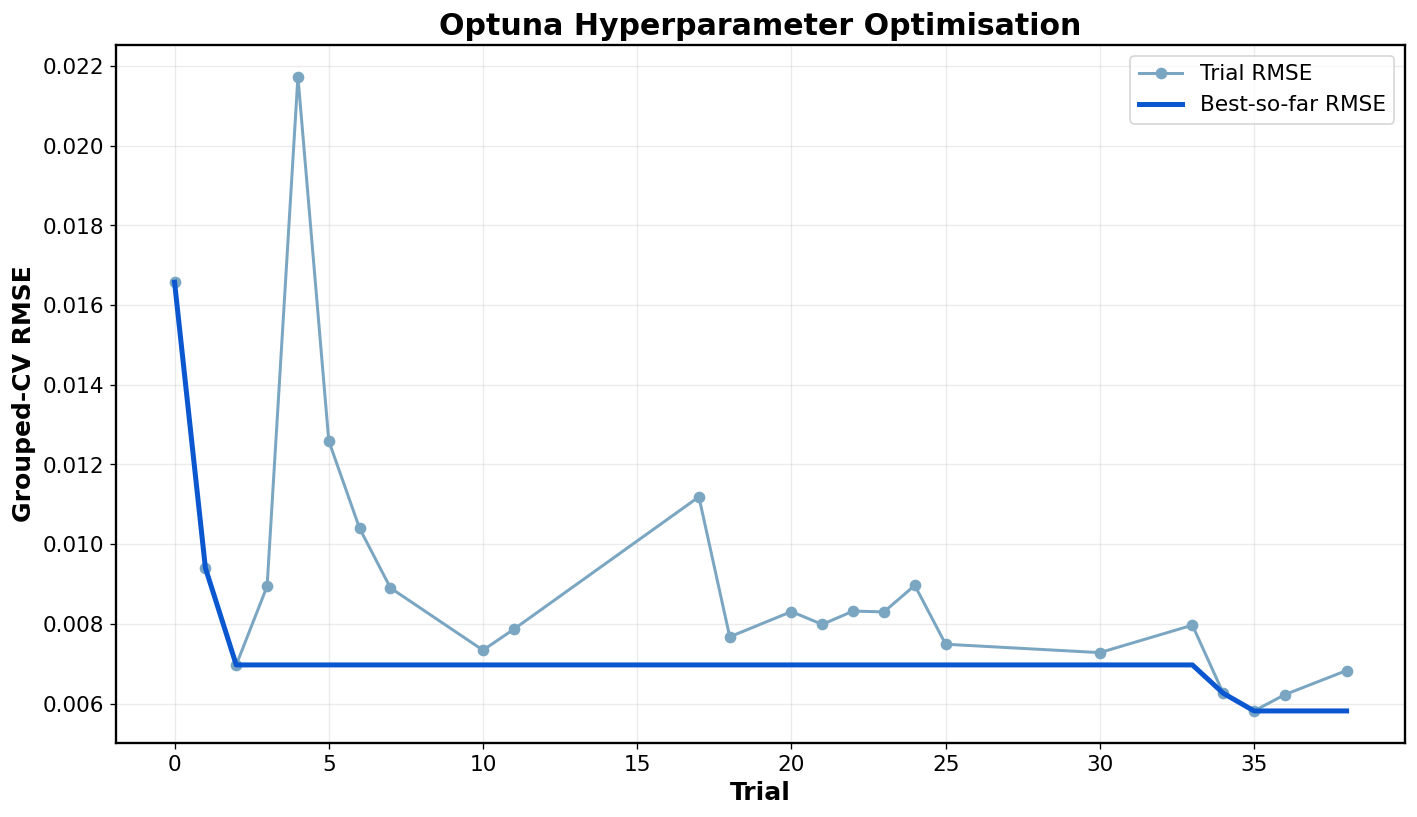

In [16]:
complete = trial_table[trial_table["state"] == "COMPLETE"].copy()
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(complete["number"], complete["value"], marker="o", linewidth=1.8, color="#7AA6C2", label="Trial RMSE")
ax.plot(complete["number"], complete["value"].cummin(), linewidth=3.0, color="#0B57D0", label="Best-so-far RMSE")
ax.set_title("Optuna Hyperparameter Optimisation")
ax.set_xlabel("Trial")
ax.set_ylabel("Grouped-CV RMSE")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_04_Optuna_Optimisation_History")
plt.show()
plt.close(fig)

### 6.4 Run grouped fivefold cross-validation for all configurations

In [17]:
cv_detail_path = DIRS["tables"] / "Table_Grouped_Fivefold_CV_Detailed.csv"

if cv_detail_path.exists() and not FORCE_RETRAIN:
    cv_detailed = pd.read_csv(cv_detail_path)
else:
    cv_rows = []
    group_cv = GroupKFold(n_splits=N_SPLITS)

    for configuration_key, specification in CONFIGURATIONS.items():
        print(f"Cross-validating: {specification['label']}")
        for fold, (train_idx, valid_idx) in enumerate(
            group_cv.split(X_DEVELOPMENT, Y_DEVELOPMENT, GROUPS_DEVELOPMENT), start=1
        ):
            processor = MechanicsProcessor().fit(X_DEVELOPMENT[train_idx])
            model, history, state = train_network(
                X_DEVELOPMENT[train_idx],
                Y_DEVELOPMENT[train_idx],
                processor,
                BEST_PARAMS,
                physics=specification["physics"],
                heteroscedastic=specification["heteroscedastic"],
                seed=SEED + 100 * fold,
                x_valid=X_DEVELOPMENT[valid_idx],
                y_valid=Y_DEVELOPMENT[valid_idx],
                max_epochs=MAX_EPOCHS_CV,
                patience=PATIENCE,
            )
            prediction = predict_single(
                model, processor, X_DEVELOPMENT[valid_idx], state["y_mean"], state["y_scale"]
            )["mean"]
            cv_rows.append({
                "Configuration key": configuration_key,
                "Configuration": specification["label"],
                "Fold": fold,
                "Best epoch": state["best_epoch"],
                **point_metrics(Y_DEVELOPMENT[valid_idx], prediction),
            })
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    cv_detailed = pd.DataFrame(cv_rows)
    cv_detailed.to_csv(cv_detail_path, index=False)

metric_columns = ["R²", "RMSE", "MAE", "MSE", "MAPE (%)", "Pearson r", "Bias"]
summary_rows = []

for configuration, group in cv_detailed.groupby("Configuration", sort=False):
    row = {"Configuration": configuration}
    for metric in metric_columns:
        row[f"{metric} mean"] = group[metric].mean()
        row[f"{metric} SD"] = group[metric].std(ddof=1)
    row["Median best epoch"] = int(np.median(group["Best epoch"]))
    summary_rows.append(row)

cv_summary = pd.DataFrame(summary_rows)
CV_EPOCHS = {
    key: max(20, int(np.median(cv_detailed.loc[cv_detailed["Configuration key"] == key, "Best epoch"])))
    for key in CONFIGURATIONS
}

show_table(cv_summary, caption="Grouped fivefold cross-validation performance")
cv_summary.to_csv(DIRS["tables"] / "Table_Grouped_Fivefold_CV_Summary.csv", index=False)
cv_summary.to_excel(DIRS["tables"] / "Table_Grouped_Fivefold_CV_Summary.xlsx", index=False)

Cross-validating: Standard MLP
Cross-validating: Physics-only MLP
Cross-validating: Uncertainty-only MLP
Cross-validating: Full PGUC-MLP


,Configuration,R² mean,R² SD,RMSE mean,RMSE SD,MAE mean,MAE SD,MSE mean,MSE SD,MAPE (%) mean,MAPE (%) SD,Pearson r mean,Pearson r SD,Bias mean,Bias SD,Median best epoch
0,Standard MLP,0.9995,0.0001,0.0067,0.0007,0.0049,0.0004,0.0000,0.0000,0.4809,0.0263,0.9998,0.0000,0.0002,0.0012,102
1,Physics-only MLP,0.9995,0.0002,0.0070,0.0013,0.0053,0.0010,0.0001,0.0000,0.5189,0.1249,0.9998,0.0001,-0.0005,0.0018,87
2,Uncertainty-only MLP,0.9995,0.0002,0.0068,0.0015,0.0050,0.0011,0.0000,0.0000,0.4926,0.1250,0.9998,0.0001,0.0013,0.0008,85
3,Full PGUC-MLP,0.9996,0.0002,0.0064,0.0014,0.0048,0.0011,0.0000,0.0000,0.4707,0.1156,0.9998,0.0001,-0.0008,0.0011,117


## 7. Final Model Training

### 7.1 Fit preprocessing on the complete development subset

In [18]:
FINAL_PROCESSOR = MechanicsProcessor().fit(X_DEVELOPMENT)
FINAL_Y_MEAN = float(Y_DEVELOPMENT.mean())
FINAL_Y_SCALE = float(Y_DEVELOPMENT.std(ddof=0))

joblib.dump(FINAL_PROCESSOR, DIRS["models"] / "PGUC_MLP_Mechanics_Processor.pkl")

preprocessing_table = pd.DataFrame({
    "Input": [*SYMBOLS, "c/(γH)", "tan(φ)", "tan(β)"],
    "Role": ["Raw predictor"] * 6 + ["Mechanics-informed representation"] * 3,
})
show_table(preprocessing_table, precision=0, caption="PGUC-MLP input representation")

,Input,Role
0,c,Raw predictor
1,φ,Raw predictor
2,γ,Raw predictor
3,H,Raw predictor
4,β,Raw predictor
5,w,Raw predictor
6,c/(γH),Mechanics-informed representation
7,tan(φ),Mechanics-informed representation
8,tan(β),Mechanics-informed representation


### 7.2 Train or load the four final configurations

Deterministic ablations use one prespecified seed. Uncertainty-aware configurations use five independently initialised heteroscedastic members.

In [19]:
def checkpoint_path(configuration_key, member_index):
    folder = DIRS["models"] / configuration_key
    folder.mkdir(parents=True, exist_ok=True)
    return folder / f"member_{member_index + 1}.pt"

def save_member(path, model, specification, params, state, seed, epochs):
    torch.save({
        "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "specification": specification,
        "params": params,
        "state": state,
        "seed": seed,
        "epochs": epochs,
        "data_fingerprint": DATA_FINGERPRINT,
    }, path)

def load_member(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    if checkpoint.get("data_fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError(f"Checkpoint was trained on a different dataset: {path}")
    model = build_model(checkpoint["params"], checkpoint["specification"]["heteroscedastic"])
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint

models_by_configuration = {}
training_histories = []

for configuration_key, specification in CONFIGURATIONS.items():
    models_by_configuration[configuration_key] = []
    epochs = CV_EPOCHS[configuration_key]
    seeds = ENSEMBLE_SEEDS[:specification["members"]]
    print(f"{specification['label']}: {len(seeds)} member(s), {epochs} epochs")

    for member_index, member_seed in enumerate(seeds):
        path = checkpoint_path(configuration_key, member_index)
        if path.exists() and not FORCE_RETRAIN:
            model, checkpoint = load_member(path)
        else:
            model, history, state = train_network(
                X_DEVELOPMENT,
                Y_DEVELOPMENT,
                FINAL_PROCESSOR,
                BEST_PARAMS,
                physics=specification["physics"],
                heteroscedastic=specification["heteroscedastic"],
                seed=member_seed,
                fixed_epochs=epochs,
            )
            save_member(path, model, specification, BEST_PARAMS, state, member_seed, epochs)
            history["Configuration"] = specification["label"]
            history["Member"] = member_index + 1
            training_histories.append(history)
        models_by_configuration[configuration_key].append(model)

if training_histories:
    final_training_history = pd.concat(training_histories, ignore_index=True)
    final_training_history.to_csv(DIRS["tables"] / "Table_Final_Training_History.csv", index=False)
elif (DIRS["tables"] / "Table_Final_Training_History.csv").exists():
    final_training_history = pd.read_csv(DIRS["tables"] / "Table_Final_Training_History.csv")
else:
    final_training_history = pd.DataFrame()

print("All final model checkpoints are ready.")

Standard MLP: 1 member(s), 102 epochs
Physics-only MLP: 1 member(s), 87 epochs
Uncertainty-only MLP: 5 member(s), 85 epochs
Full PGUC-MLP: 5 member(s), 117 epochs
All final model checkpoints are ready.


### 7.3 Display final training convergence

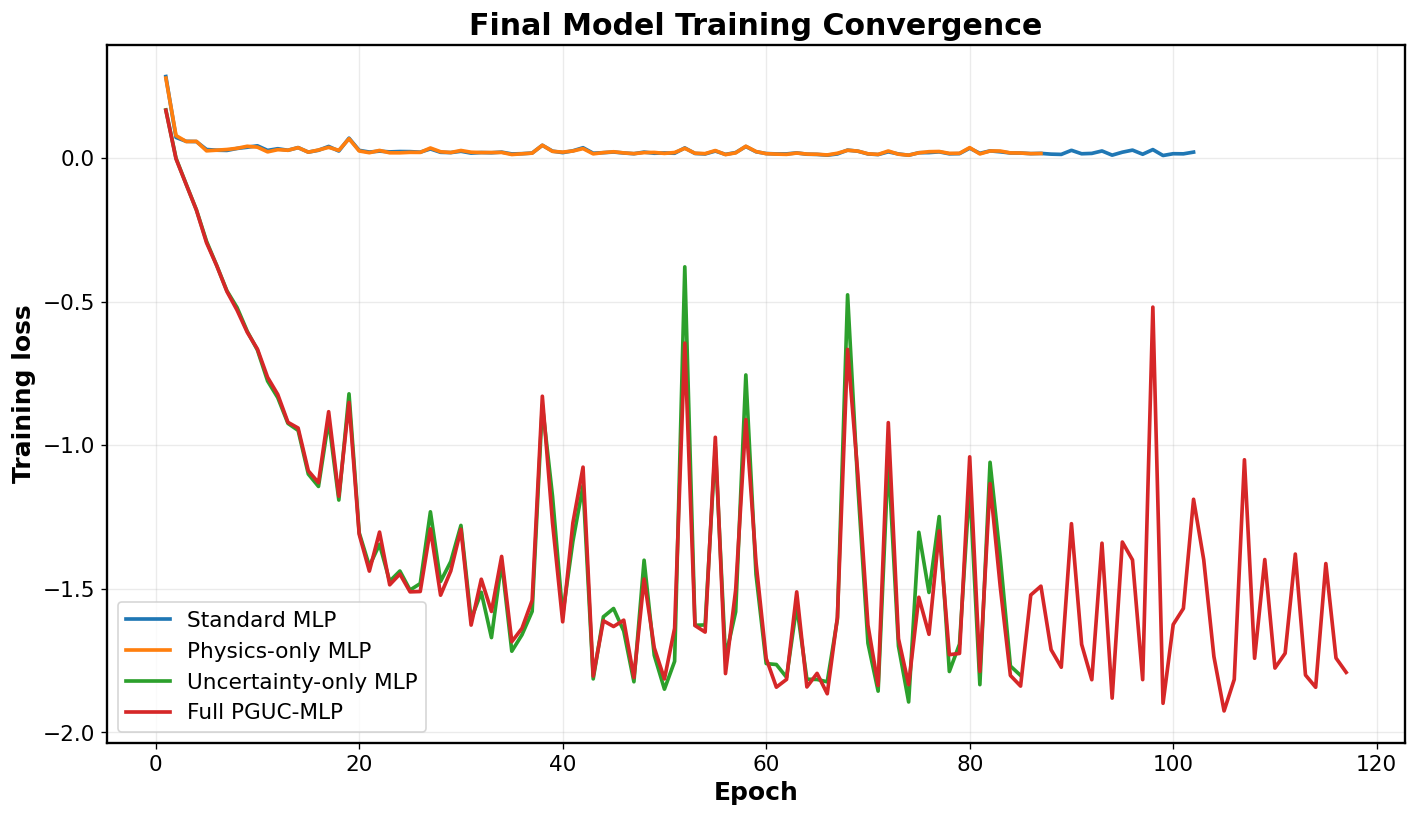

In [20]:
if not final_training_history.empty:
    fig, ax = plt.subplots(figsize=(12, 7))
    first_members = final_training_history[final_training_history["Member"] == 1]
    for configuration, group in first_members.groupby("Configuration", sort=False):
        ax.plot(group["epoch"], group["training_loss"], linewidth=2.2, label=configuration)
    ax.set_title("Final Model Training Convergence")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    save_figure(fig, DIRS["performance"], "Figure_05_Final_Training_Convergence")
    plt.show()
    plt.close(fig)
else:
    print("Training histories were not regenerated during this resumed run.")

## 8. Conformal Calibration and Locked-Test Evaluation

### 8.1 Calibrate 90% and 95% prediction intervals

Normalised split-conformal scores use the untouched calibration subset. Finite-sample quantiles use the conservative `higher` rule.

In [21]:
X_CALIBRATION = calibration_df[FEATURES].to_numpy(dtype=np.float32)
Y_CALIBRATION = calibration_df[TARGET].to_numpy(dtype=np.float32)
X_TEST = test_df[FEATURES].to_numpy(dtype=np.float32)
Y_TEST = test_df[TARGET].to_numpy(dtype=np.float32)

def conformal_quantile(scores, coverage):
    n = len(scores)
    quantile_level = min(1.0, math.ceil((n + 1) * coverage) / n)
    return float(np.quantile(scores, quantile_level, method="higher"))

def interval_statistics(actual, lower, upper, alpha):
    covered = (actual >= lower) & (actual <= upper)
    width = upper - lower
    score = width.copy()
    score += (2 / alpha) * (lower - actual) * (actual < lower)
    score += (2 / alpha) * (actual - upper) * (actual > upper)
    return {
        "PICP (%)": 100 * covered.mean(),
        "MPIW": width.mean(),
        "Median width": np.median(width),
        "Interval score": score.mean(),
    }

calibration_objects = {}
predictions = {}

for configuration_key, specification in CONFIGURATIONS.items():
    calibration_prediction = predict_configuration(
        models_by_configuration[configuration_key],
        FINAL_PROCESSOR,
        X_CALIBRATION,
        FINAL_Y_MEAN,
        FINAL_Y_SCALE,
        specification["heteroscedastic"],
    )
    test_prediction = predict_configuration(
        models_by_configuration[configuration_key],
        FINAL_PROCESSOR,
        X_TEST,
        FINAL_Y_MEAN,
        FINAL_Y_SCALE,
        specification["heteroscedastic"],
    )

    if specification["heteroscedastic"]:
        scale = np.maximum(calibration_prediction["total_sigma"], 1e-8)
        scores = np.abs(Y_CALIBRATION - calibration_prediction["mean"]) / scale
        quantiles = {coverage: conformal_quantile(scores, coverage) for coverage in (0.90, 0.95)}
        calibration_objects[configuration_key] = {"scores": scores, "quantiles": quantiles}
        for coverage, quantile in quantiles.items():
            half_width = quantile * np.maximum(test_prediction["total_sigma"], 1e-8)
            test_prediction[f"lower_{int(coverage * 100)}"] = test_prediction["mean"] - half_width
            test_prediction[f"upper_{int(coverage * 100)}"] = test_prediction["mean"] + half_width

    predictions[configuration_key] = test_prediction

joblib.dump(calibration_objects, DIRS["models"] / "PGUC_MLP_Conformal_Calibration.pkl")

['/content/drive/MyDrive/Reuben_MDSSA/models/PGUC_MLP_Conformal_Calibration.pkl']

### 8.2 Display the principal locked-test performance table

In [22]:
performance_rows = []

for configuration_key, specification in CONFIGURATIONS.items():
    result = predictions[configuration_key]
    row = {
        "Configuration key": configuration_key,
        "Configuration": specification["label"],
        **point_metrics(Y_TEST, result["mean"]),
    }
    for coverage in (0.90, 0.95):
        label = int(coverage * 100)
        if f"lower_{label}" in result:
            interval = interval_statistics(
                Y_TEST, result[f"lower_{label}"], result[f"upper_{label}"], 1 - coverage
            )
            row[f"PICP {label}%"] = interval["PICP (%)"]
            row[f"MPIW {label}%"] = interval["MPIW"]
            row[f"Interval score {label}%"] = interval["Interval score"]
        else:
            row[f"PICP {label}%"] = np.nan
            row[f"MPIW {label}%"] = np.nan
            row[f"Interval score {label}%"] = np.nan
    performance_rows.append(row)

performance_table = pd.DataFrame(performance_rows)
display_columns = [
    "Configuration", "R²", "RMSE", "MAE", "MSE", "MAPE (%)", "Pearson r", "Bias",
    "PICP 90%", "MPIW 90%", "PICP 95%", "MPIW 95%",
]
show_table(performance_table[display_columns], caption="Locked-test performance and uncertainty calibration")

performance_table.to_csv(DIRS["tables"] / "Table_Locked_Test_Performance.csv", index=False)
performance_table.to_excel(DIRS["tables"] / "Table_Locked_Test_Performance.xlsx", index=False)

with pd.ExcelWriter(DIRS["tables"] / "Locked_Test_Predictions.xlsx") as writer:
    for configuration_key, specification in CONFIGURATIONS.items():
        result = predictions[configuration_key]
        output = test_df[["row_id", "profile_group", *FEATURES, TARGET]].copy()
        output["Predicted FOS"] = result["mean"]
        output["Residual"] = result["mean"] - Y_TEST
        output["Aleatoric SD"] = np.sqrt(result["aleatoric_variance"])
        output["Epistemic SD"] = np.sqrt(result["epistemic_variance"])
        output["Total SD"] = result["total_sigma"]
        for coverage in (90, 95):
            if f"lower_{coverage}" in result:
                output[f"Lower {coverage}% PI"] = result[f"lower_{coverage}"]
                output[f"Upper {coverage}% PI"] = result[f"upper_{coverage}"]
        output.to_excel(writer, sheet_name=configuration_key[:31], index=False)

,Configuration,R²,RMSE,MAE,MSE,MAPE (%),Pearson r,Bias,PICP 90%,MPIW 90%,PICP 95%,MPIW 95%
0,Standard MLP,0.9985,0.0125,0.0103,0.0002,1.1256,0.9998,0.0069,—,—,—,—
1,Physics-only MLP,0.9982,0.0135,0.0109,0.0002,1.1561,0.9995,-0.0005,—,—,—,—
2,Uncertainty-only MLP,0.9982,0.0135,0.0082,0.0002,0.6620,0.9996,-0.0044,90.8555,0.0285,94.9853,0.0351
3,Full PGUC-MLP,0.9992,0.0092,0.0060,0.0001,0.5000,0.9998,-0.0049,88.4956,0.0230,93.5103,0.0271


### 8.3 Observed-versus-predicted ablation figure

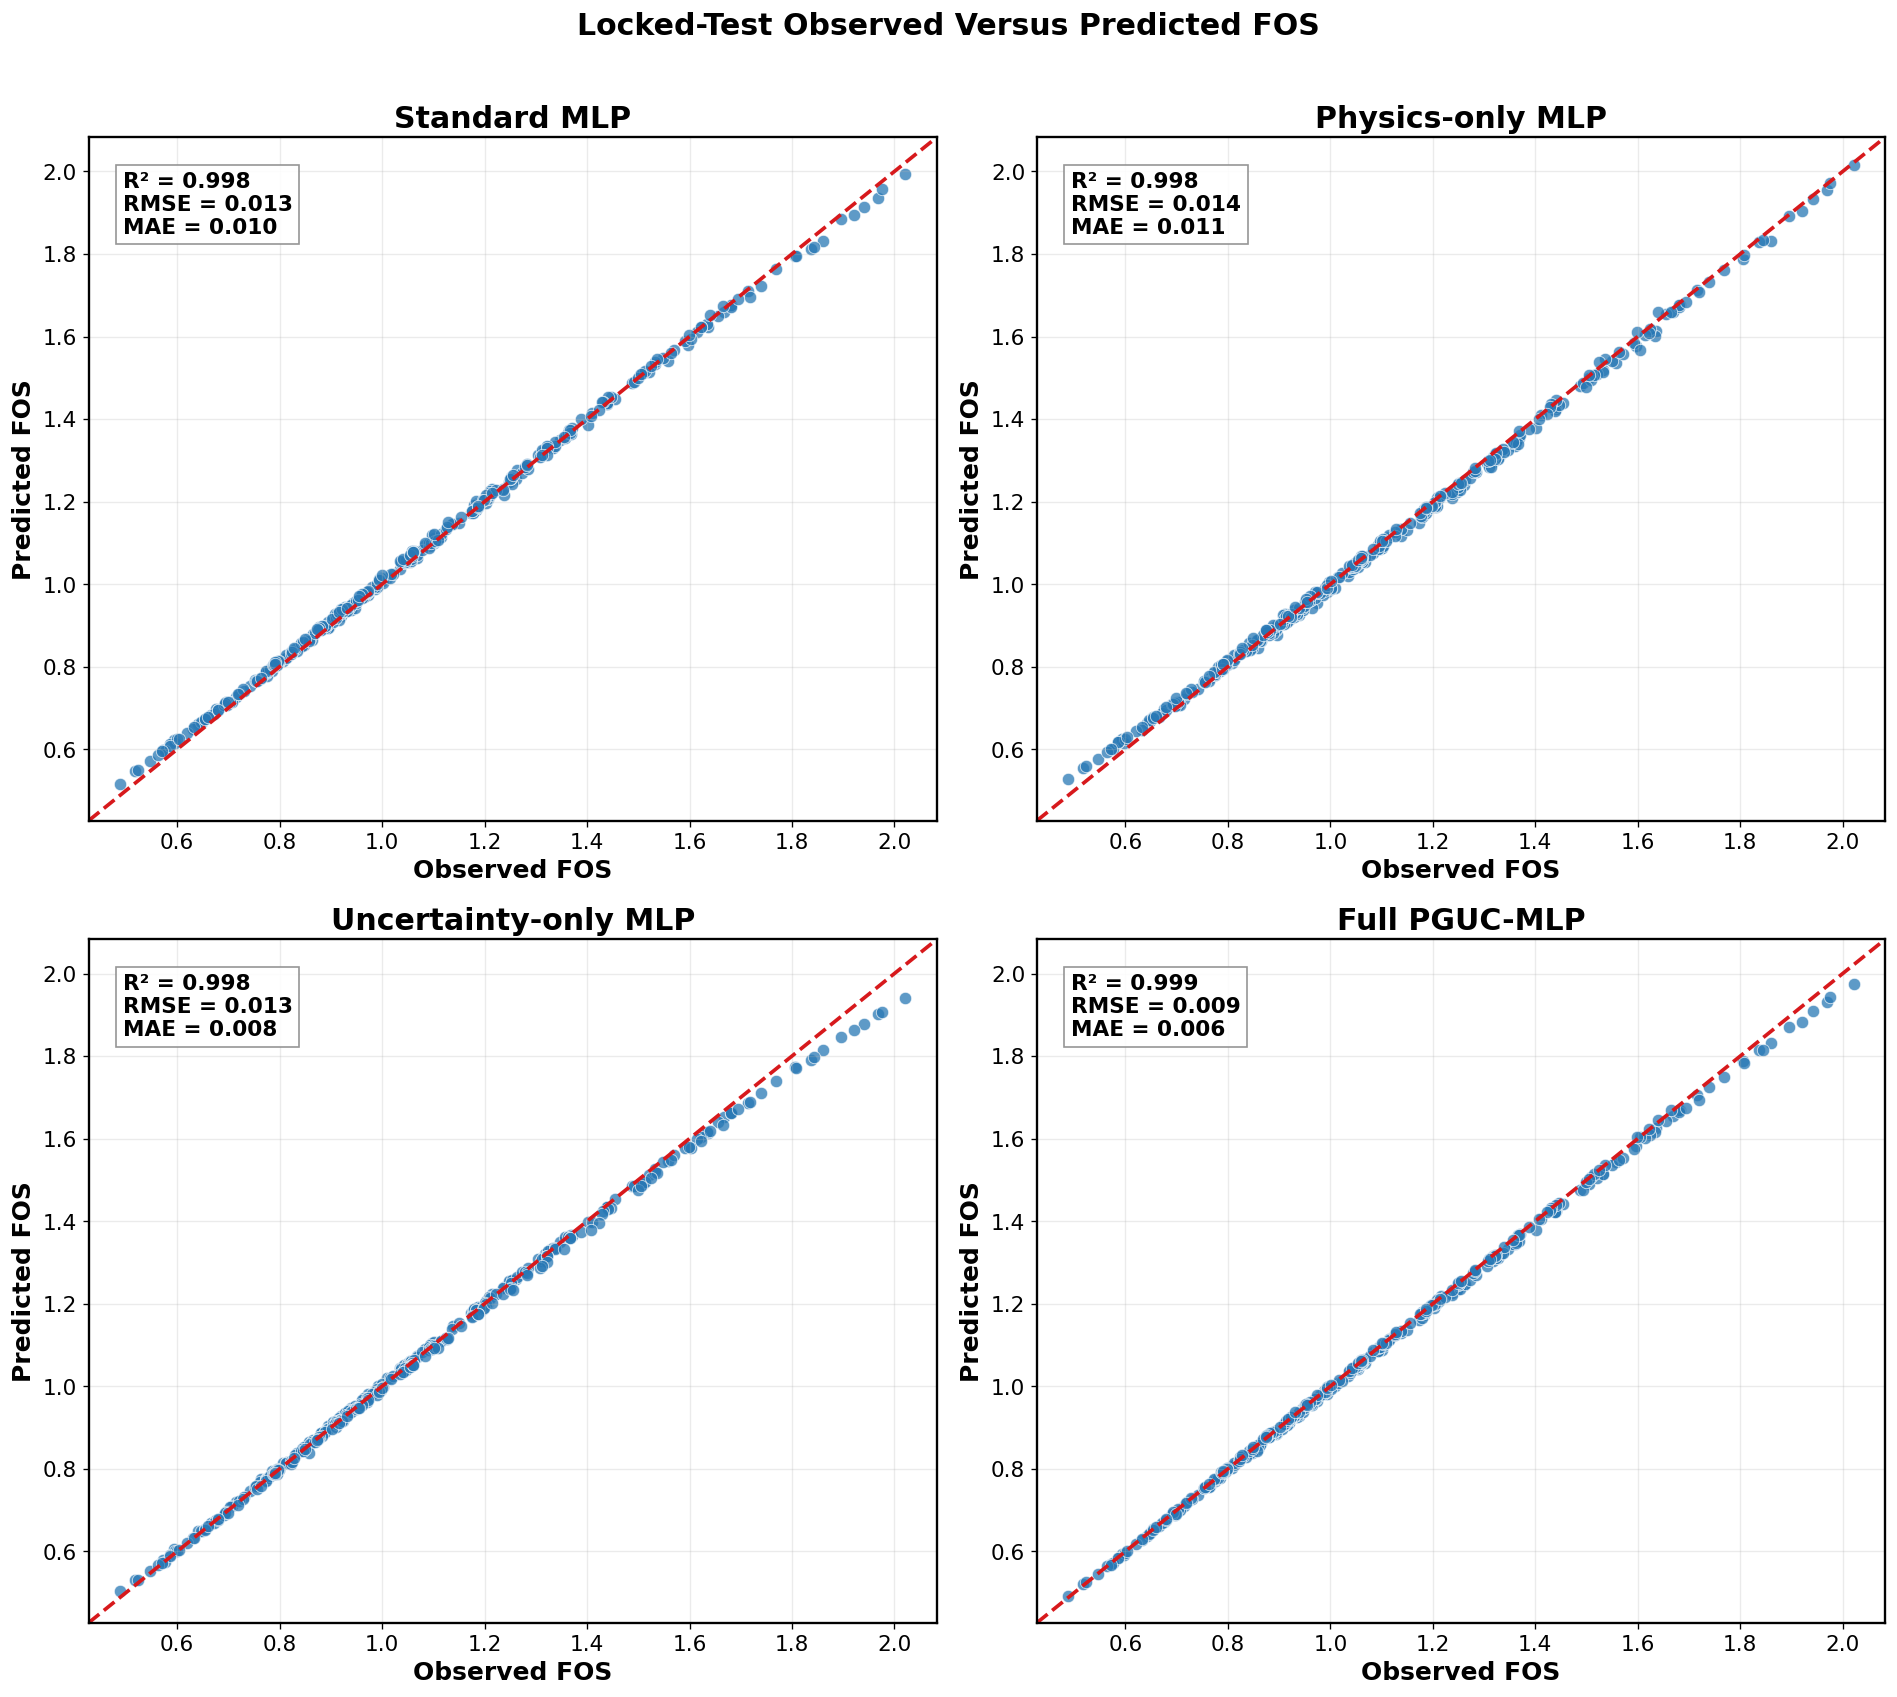

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
limits = [min(Y_TEST.min(), *(result["mean"].min() for result in predictions.values())),
          max(Y_TEST.max(), *(result["mean"].max() for result in predictions.values()))]
padding = 0.04 * (limits[1] - limits[0])
limits = [limits[0] - padding, limits[1] + padding]

for axis, (configuration_key, specification) in zip(axes.ravel(), CONFIGURATIONS.items()):
    predicted = predictions[configuration_key]["mean"]
    metrics = point_metrics(Y_TEST, predicted)
    axis.scatter(Y_TEST, predicted, s=55, alpha=0.75, color="#2878B5", edgecolor="white", linewidth=0.5)
    axis.plot(limits, limits, linestyle="--", linewidth=2.2, color="#D7191C")
    axis.set_xlim(limits)
    axis.set_ylim(limits)
    axis.set_title(specification["label"])
    axis.set_xlabel("Observed FOS")
    axis.set_ylabel("Predicted FOS")
    axis.grid(alpha=0.25)
    axis.text(
        0.04, 0.95,
        f"R² = {metrics['R²']:.3f}\nRMSE = {metrics['RMSE']:.3f}\nMAE = {metrics['MAE']:.3f}",
        transform=axis.transAxes, va="top", fontsize=FONT_TICK, fontweight="bold",
        bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "#888888"},
    )

fig.suptitle("Locked-Test Observed Versus Predicted FOS", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_06_Observed_vs_Predicted_Ablation")
plt.show()
plt.close(fig)

### 8.4 Full PGUC-MLP residual diagnostics

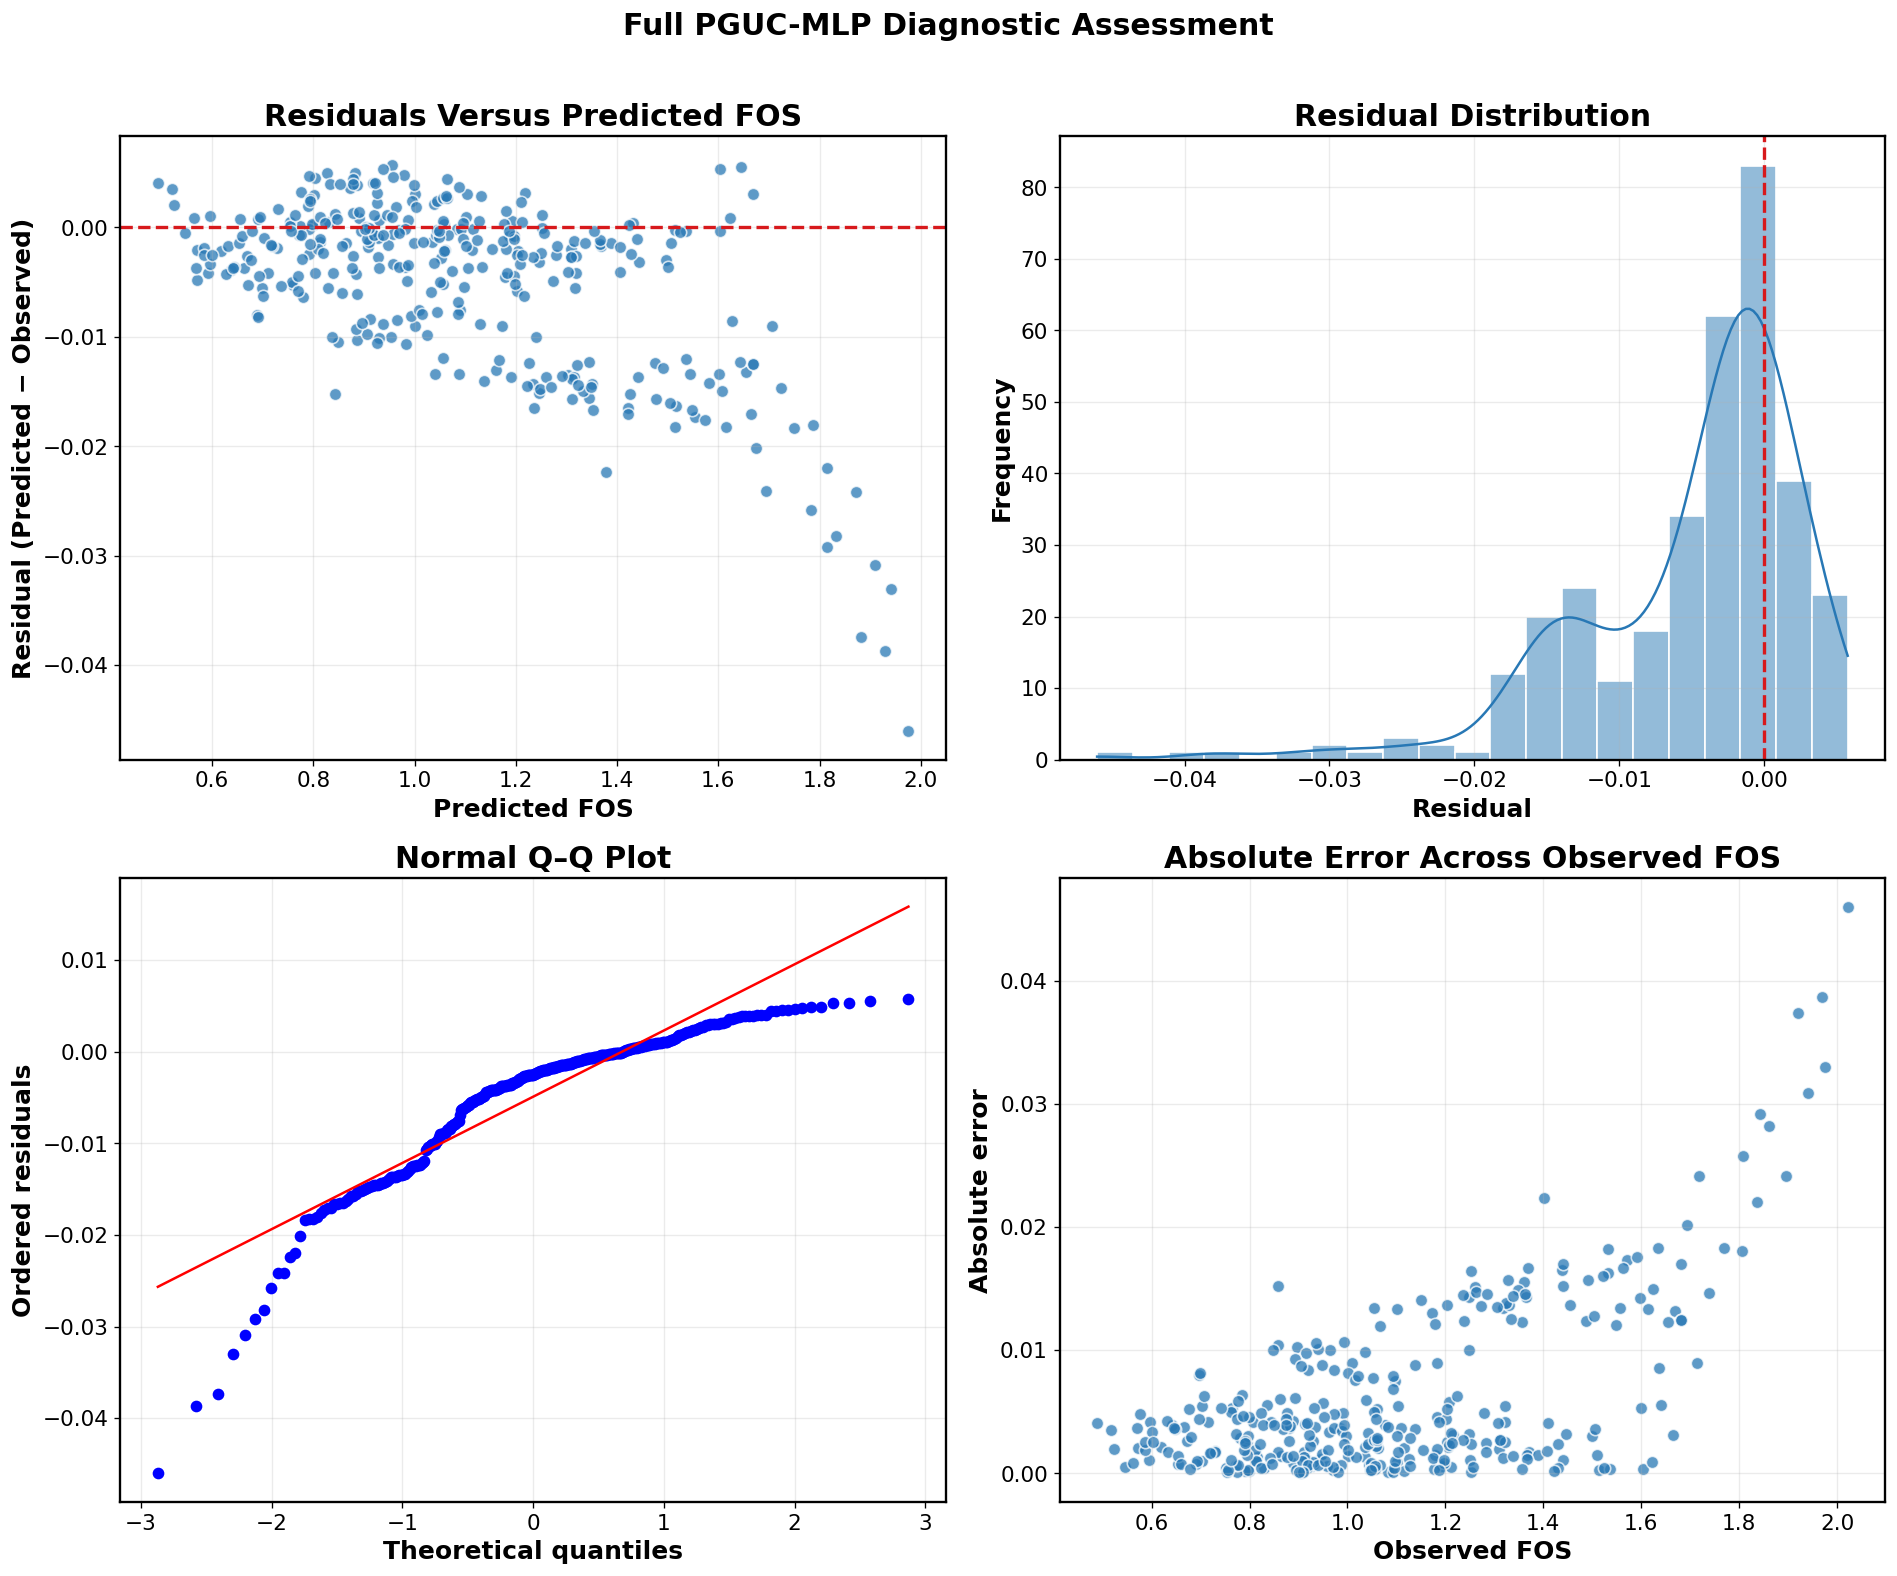

In [24]:
full_prediction = predictions["full_pguc_mlp"]["mean"]
full_residual = full_prediction - Y_TEST

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

axes[0, 0].scatter(full_prediction, full_residual, s=55, alpha=0.75, color="#2878B5", edgecolor="white")
axes[0, 0].axhline(0, color="#D7191C", linestyle="--", linewidth=2)
axes[0, 0].set_title("Residuals Versus Predicted FOS")
axes[0, 0].set_xlabel("Predicted FOS")
axes[0, 0].set_ylabel("Residual (Predicted − Observed)")

sns.histplot(full_residual, kde=True, color="#2878B5", edgecolor="white", ax=axes[0, 1])
axes[0, 1].axvline(0, color="#D7191C", linestyle="--", linewidth=2)
axes[0, 1].set_title("Residual Distribution")
axes[0, 1].set_xlabel("Residual")
axes[0, 1].set_ylabel("Frequency")

stats.probplot(full_residual, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Normal Q–Q Plot")
axes[1, 0].set_xlabel("Theoretical quantiles")
axes[1, 0].set_ylabel("Ordered residuals")

axes[1, 1].scatter(Y_TEST, np.abs(full_residual), s=55, alpha=0.75, color="#2878B5", edgecolor="white")
axes[1, 1].set_title("Absolute Error Across Observed FOS")
axes[1, 1].set_xlabel("Observed FOS")
axes[1, 1].set_ylabel("Absolute error")

for axis in axes.ravel():
    axis.grid(alpha=0.25)

fig.suptitle("Full PGUC-MLP Diagnostic Assessment", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_07_Full_PGUC_MLP_Diagnostics")
plt.show()
plt.close(fig)

### 8.5 Ablation performance comparison

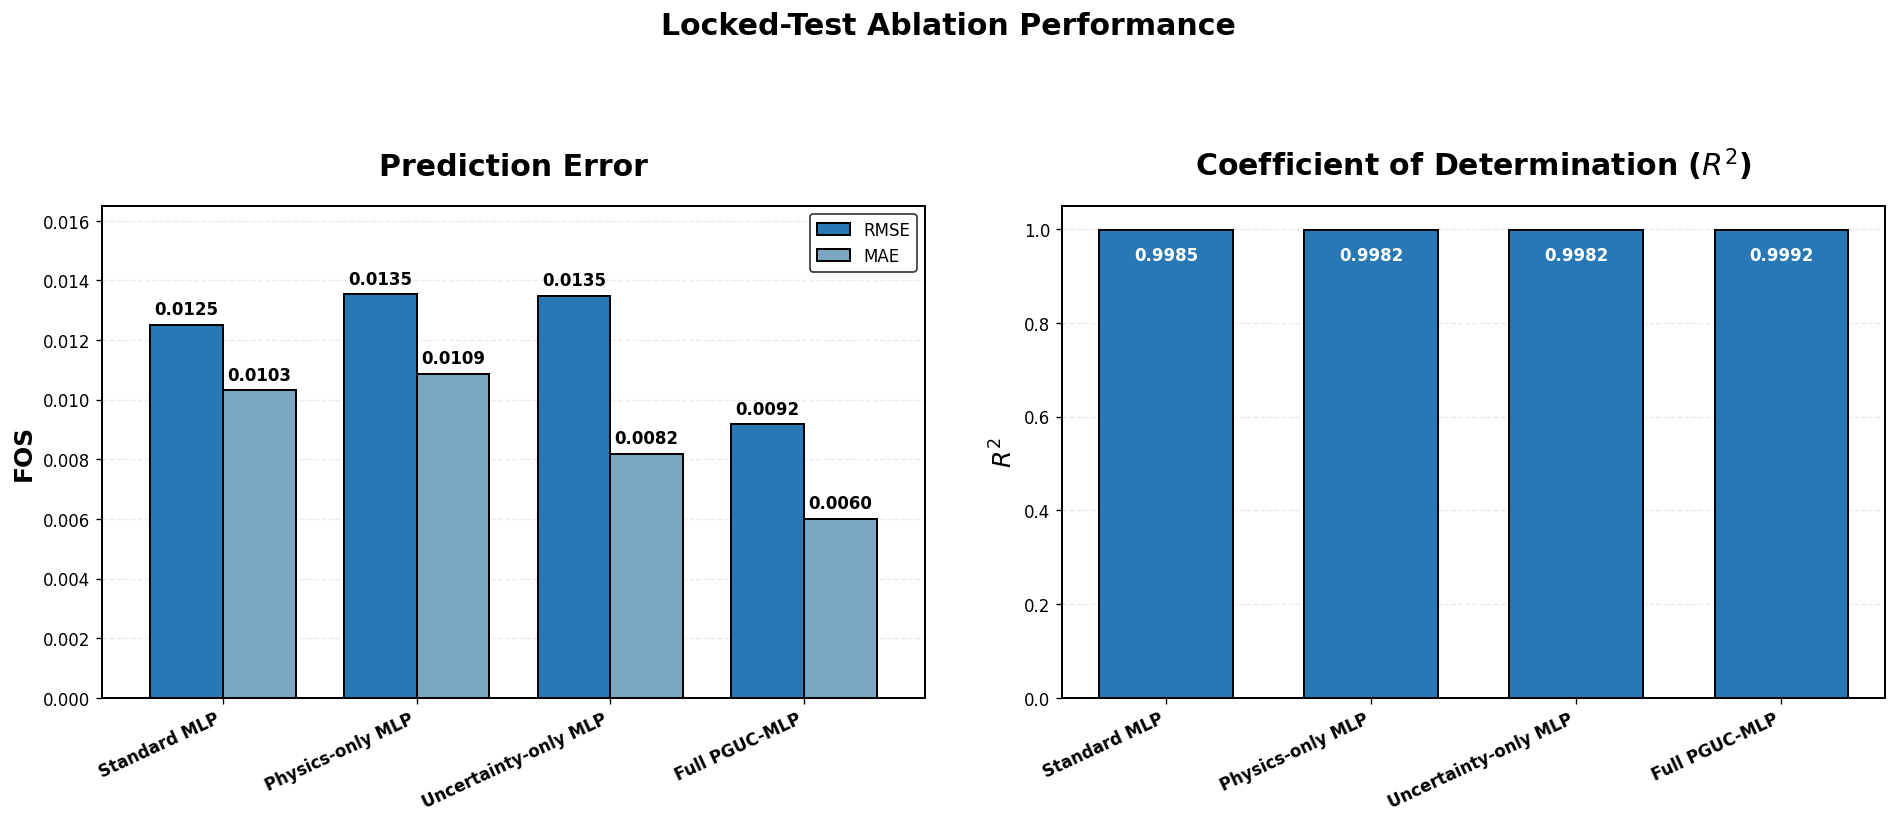

In [50]:
import numpy as np
import matplotlib.pyplot as plt

FONT_TITLE = 18
FONT_SUBTITLE = 15
FONT_TICK = 10

plot_table = performance_table.set_index("Configuration")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))


# Prediction error
error_metrics = plot_table[["RMSE", "MAE"]]

error_metrics.plot(
    kind="bar",
    ax=axes[0],
    color=["#2878B5", "#7AA6C2"],
    edgecolor="black",
    linewidth=1.2,
    width=0.75,
)

axes[0].set_title(
    "Prediction Error",
    fontsize=FONT_TITLE,
    fontweight="bold",
    pad=18,
)

axes[0].set_xlabel("")
axes[0].set_ylabel(
    "FOS",
    fontsize=FONT_SUBTITLE,
    fontweight="bold",
)

axes[0].tick_params(
    axis="x",
    rotation=25,
    labelsize=FONT_TICK,
)

axes[0].tick_params(
    axis="y",
    labelsize=FONT_TICK,
)

for label in axes[0].get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_fontweight("bold")

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        labels=[
            f"{bar.get_height():.4f}"
            for bar in container
        ],
        padding=4,
        fontsize=FONT_TICK,
        fontweight="bold",
        color="black",
    )

error_upper = float(
    np.nanmax(error_metrics.to_numpy())
) * 1.22

axes[0].set_ylim(0, error_upper)

axes[0].legend(
    title=None,
    fontsize=FONT_TICK,
    frameon=True,
    edgecolor="black",
)


# Coefficient of determination
r2_values = plot_table["R²"].astype(float)

bars = axes[1].bar(
    plot_table.index,
    r2_values,
    color="#2878B5",
    edgecolor="black",
    linewidth=1.2,
    width=0.65,
)

axes[1].set_title(
    r"Coefficient of Determination ($R^2$)",
    fontsize=FONT_TITLE,
    fontweight="bold",
    pad=18,
)

axes[1].set_xlabel("")
axes[1].set_ylabel(
    r"$R^2$",
    fontsize=FONT_SUBTITLE,
    fontweight="bold",
)

axes[1].tick_params(
    axis="x",
    rotation=25,
    labelsize=FONT_TICK,
)

axes[1].tick_params(
    axis="y",
    labelsize=FONT_TICK,
)

for label in axes[1].get_xticklabels():
    label.set_horizontalalignment("right")
    label.set_fontweight("bold")

axes[1].set_ylim(0, 1.05)

for bar, value in zip(bars, r2_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value - 0.035,
        f"{value:.4f}",
        ha="center",
        va="top",
        fontsize=FONT_TICK,
        fontweight="bold",
        color="white",
    )


# Shared formatting
for axis in axes:
    axis.grid(
        axis="y",
        linestyle="--",
        linewidth=0.8,
        alpha=0.25,
    )
    axis.set_axisbelow(True)

    for spine in axis.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("black")


fig.suptitle(
    "Locked-Test Ablation Performance",
    fontsize=FONT_TITLE,
    fontweight="bold",
    y=0.98,
)

fig.tight_layout(
    rect=[0, 0, 1, 0.91],
    w_pad=3.0,
)

save_figure(
    fig,
    DIRS["performance"],
    "Figure_08_Ablation_Performance",
)

plt.show()
plt.close(fig)

### 8.6 Prediction intervals and empirical calibration

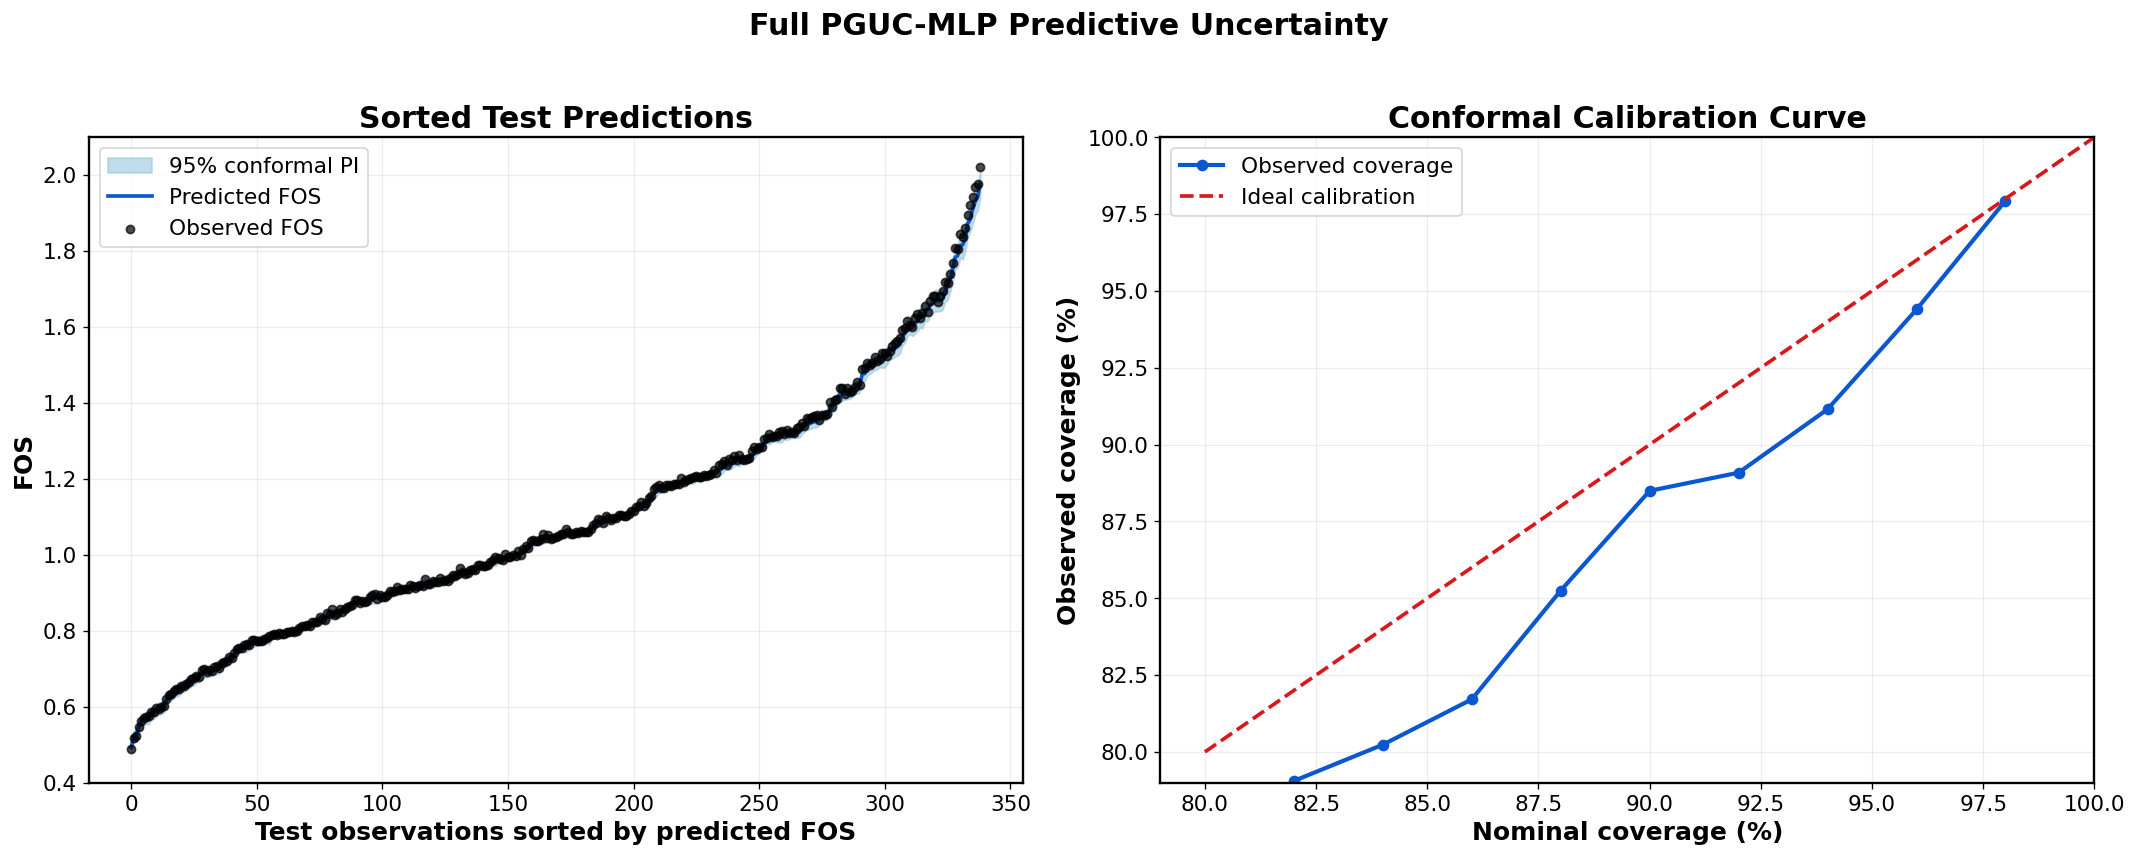

,Nominal coverage (%),Observed coverage (%)
0,80.0000,75.5162
1,82.0000,79.0560
2,84.0000,80.2360
3,86.0000,81.7109
4,88.0000,85.2507
5,90.0000,88.4956
6,92.0000,89.0855
7,94.0000,91.1504
8,96.0000,94.3953
9,98.0000,97.9351


In [26]:
full_result = predictions["full_pguc_mlp"]
sort_index = np.argsort(full_result["mean"])
coverage_grid = np.arange(0.80, 1.00, 0.02)
observed_coverage = []

calibration_prediction_full = predict_configuration(
    models_by_configuration["full_pguc_mlp"], FINAL_PROCESSOR, X_CALIBRATION,
    FINAL_Y_MEAN, FINAL_Y_SCALE, True,
)
calibration_scale = np.maximum(calibration_prediction_full["total_sigma"], 1e-8)
calibration_scores = np.abs(Y_CALIBRATION - calibration_prediction_full["mean"]) / calibration_scale

for coverage in coverage_grid:
    quantile = conformal_quantile(calibration_scores, float(coverage))
    half_width = quantile * np.maximum(full_result["total_sigma"], 1e-8)
    lower = full_result["mean"] - half_width
    upper = full_result["mean"] + half_width
    observed_coverage.append(np.mean((Y_TEST >= lower) & (Y_TEST <= upper)))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

x_axis = np.arange(len(Y_TEST))
axes[0].fill_between(
    x_axis,
    full_result["lower_95"][sort_index],
    full_result["upper_95"][sort_index],
    color="#9ECAE1", alpha=0.65, label="95% conformal PI",
)
axes[0].plot(x_axis, full_result["mean"][sort_index], color="#0B57D0", linewidth=2.2, label="Predicted FOS")
axes[0].scatter(x_axis, Y_TEST[sort_index], color="black", s=24, alpha=0.70, label="Observed FOS", zorder=3)
axes[0].set_title("Sorted Test Predictions")
axes[0].set_xlabel("Test observations sorted by predicted FOS")
axes[0].set_ylabel("FOS")
axes[0].legend()
axes[0].grid(alpha=0.22)

axes[1].plot(coverage_grid * 100, np.array(observed_coverage) * 100, marker="o", linewidth=2.5, color="#0B57D0", label="Observed coverage")
axes[1].plot([80, 100], [80, 100], linestyle="--", linewidth=2.2, color="#D7191C", label="Ideal calibration")
axes[1].set_title("Conformal Calibration Curve")
axes[1].set_xlabel("Nominal coverage (%)")
axes[1].set_ylabel("Observed coverage (%)")
axes[1].set_xlim(79, 100)
axes[1].set_ylim(79, 100)
axes[1].legend()
axes[1].grid(alpha=0.22)

fig.suptitle("Full PGUC-MLP Predictive Uncertainty", fontsize=FONT_TITLE, fontweight="bold", y=1.02)
fig.tight_layout()
save_figure(fig, DIRS["uncertainty"], "Figure_09_Conformal_Prediction_Intervals")
plt.show()
plt.close(fig)

calibration_curve_table = pd.DataFrame({
    "Nominal coverage (%)": coverage_grid * 100,
    "Observed coverage (%)": np.array(observed_coverage) * 100,
})
show_table(calibration_curve_table, caption="Full PGUC-MLP empirical coverage")
calibration_curve_table.to_csv(DIRS["tables"] / "Table_Conformal_Calibration_Curve.csv", index=False)

### 8.7 Aleatoric and epistemic uncertainty decomposition

,Component,Mean,Median,Maximum
0,Aleatoric SD,0.0330,0.0272,0.0960
1,Epistemic SD,0.0120,0.0117,0.0315
2,Total predictive SD,0.0353,0.0300,0.1001


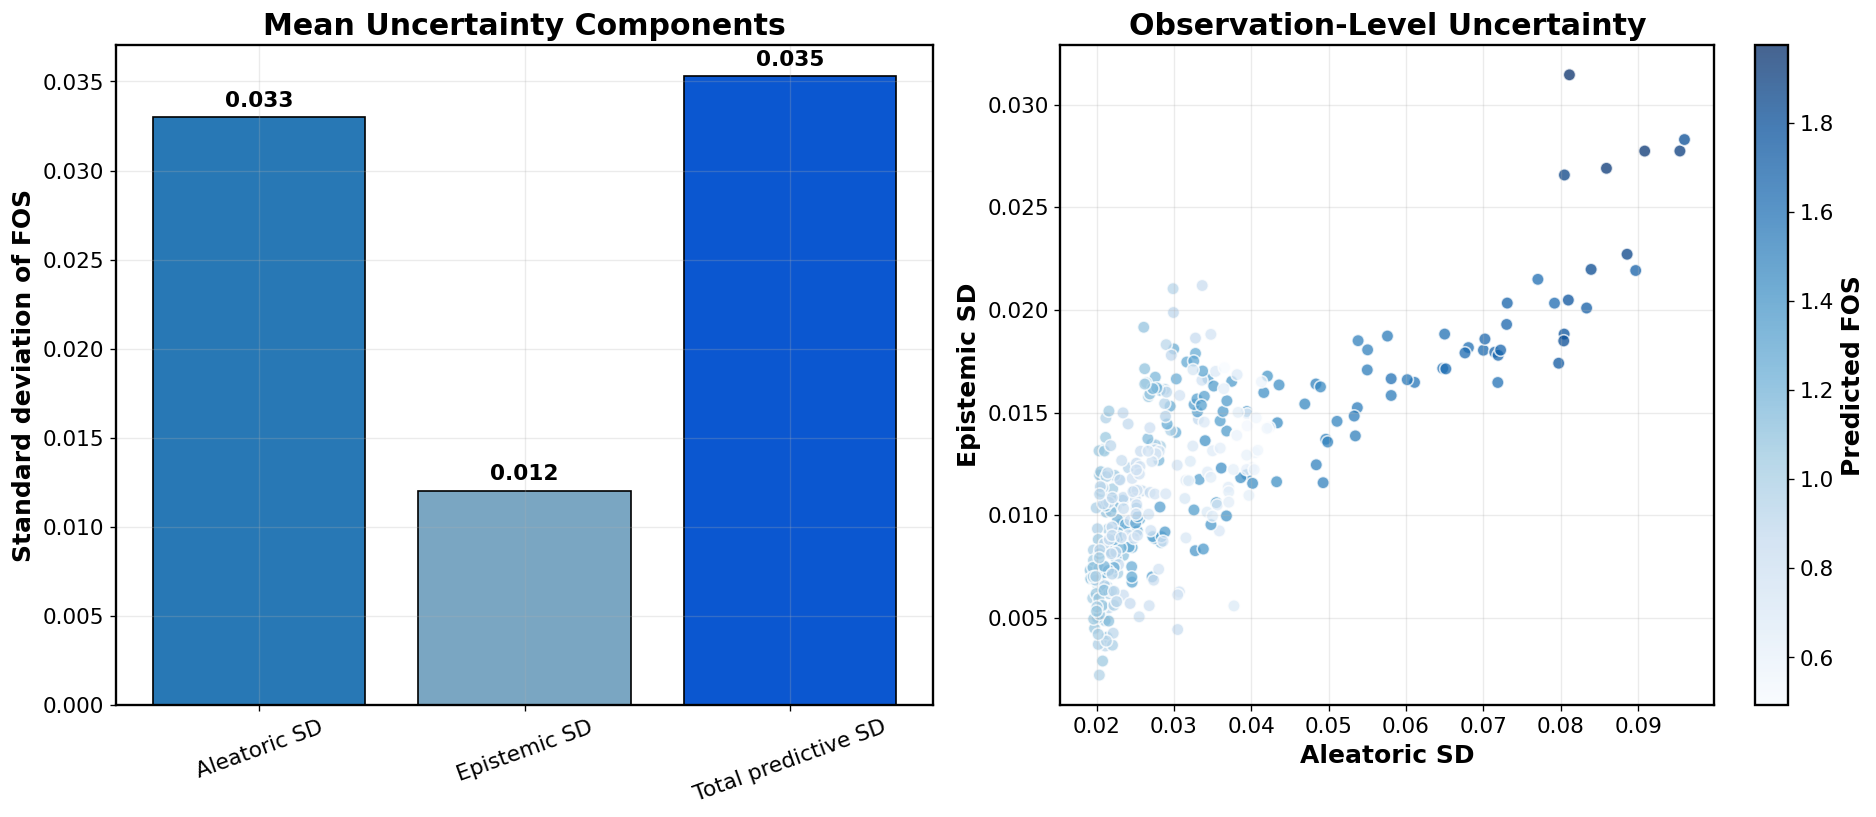

In [27]:
uncertainty_table = pd.DataFrame({
    "Component": ["Aleatoric SD", "Epistemic SD", "Total predictive SD"],
    "Mean": [
        np.sqrt(full_result["aleatoric_variance"]).mean(),
        np.sqrt(full_result["epistemic_variance"]).mean(),
        full_result["total_sigma"].mean(),
    ],
    "Median": [
        np.median(np.sqrt(full_result["aleatoric_variance"])),
        np.median(np.sqrt(full_result["epistemic_variance"])),
        np.median(full_result["total_sigma"]),
    ],
    "Maximum": [
        np.sqrt(full_result["aleatoric_variance"]).max(),
        np.sqrt(full_result["epistemic_variance"]).max(),
        full_result["total_sigma"].max(),
    ],
})
show_table(uncertainty_table, caption="Predictive uncertainty decomposition")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
bars = axes[0].bar(uncertainty_table["Component"], uncertainty_table["Mean"], color=["#2878B5", "#7AA6C2", "#0B57D0"], edgecolor="black")
axes[0].bar_label(bars, labels=[f"{value:.3f}" for value in uncertainty_table["Mean"]], padding=4, fontsize=FONT_TICK, fontweight="bold")
axes[0].set_title("Mean Uncertainty Components")
axes[0].set_ylabel("Standard deviation of FOS")
axes[0].tick_params(axis="x", rotation=20)

axes[1].scatter(
    np.sqrt(full_result["aleatoric_variance"]),
    np.sqrt(full_result["epistemic_variance"]),
    c=full_result["mean"], cmap="Blues", s=55, alpha=0.75, edgecolor="white",
)
axes[1].set_title("Observation-Level Uncertainty")
axes[1].set_xlabel("Aleatoric SD")
axes[1].set_ylabel("Epistemic SD")
colourbar = fig.colorbar(axes[1].collections[0], ax=axes[1])
colourbar.set_label("Predicted FOS", fontsize=FONT_LABEL, fontweight="bold")
colourbar.ax.tick_params(labelsize=FONT_TICK)

for axis in axes:
    axis.grid(alpha=0.25)

fig.tight_layout()
save_figure(fig, DIRS["uncertainty"], "Figure_10_Uncertainty_Decomposition")
plt.show()
plt.close(fig)

uncertainty_table.to_csv(DIRS["tables"] / "Table_Uncertainty_Decomposition.csv", index=False)

## 9. Physical Consistency and Sensitivity Analysis

### 9.1 Quantify monotonicity-violation rates

The audit uses development-domain observations and finite increases of 2%, 5% and 10% of each predictor range. Expected directions are positive for $c$ and $\phi$, and negative for $H$ and $eta$.

In [28]:
audit_sample = development_df.sample(n=min(500, len(development_df)), random_state=SEED).copy()
X_AUDIT = audit_sample[FEATURES].to_numpy(dtype=np.float32)
AUDIT_FRACTIONS = [0.02, 0.05, 0.10]
MONOTONIC_FEATURES = {"c": 1.0, "phi": 1.0, "H": -1.0, "beta": -1.0}
PHYSICS_TOLERANCE_FOS = 1e-4
monotonicity_rows = []

for configuration_key, specification in CONFIGURATIONS.items():
    base = predict_configuration(
        models_by_configuration[configuration_key], FINAL_PROCESSOR, X_AUDIT,
        FINAL_Y_MEAN, FINAL_Y_SCALE, specification["heteroscedastic"],
    )["mean"]

    for feature, direction in MONOTONIC_FEATURES.items():
        feature_index = FEATURES.index(feature)
        feature_min, feature_max = FINAL_PROCESSOR.bounds[feature_index]
        feature_range = feature_max - feature_min

        for fraction in AUDIT_FRACTIONS:
            changed_x = X_AUDIT.copy()
            changed_x[:, feature_index] = np.minimum(
                changed_x[:, feature_index] + fraction * feature_range,
                feature_max,
            )
            valid = changed_x[:, feature_index] > X_AUDIT[:, feature_index] + 1e-9
            changed = predict_configuration(
                models_by_configuration[configuration_key], FINAL_PROCESSOR, changed_x,
                FINAL_Y_MEAN, FINAL_Y_SCALE, specification["heteroscedastic"],
            )["mean"]
            signed_change = direction * (changed - base)
            violation_rate = 100 * np.mean(signed_change[valid] < -PHYSICS_TOLERANCE_FOS)
            monotonicity_rows.append({
                "Configuration key": configuration_key,
                "Configuration": specification["label"],
                "Predictor": SYMBOL_MAP[feature],
                "Perturbation (% of range)": 100 * fraction,
                "Valid comparisons": int(valid.sum()),
                "Violation rate (%)": violation_rate,
                "Mean signed response": signed_change[valid].mean(),
            })

monotonicity_table = pd.DataFrame(monotonicity_rows)
overall_violation = (
    monotonicity_table.groupby(["Configuration key", "Configuration"], as_index=False)["Violation rate (%)"]
    .mean()
    .rename(columns={"Violation rate (%)": "Mean violation rate (%)"})
)

show_table(monotonicity_table, caption="Finite-perturbation monotonicity audit")
show_table(overall_violation[["Configuration", "Mean violation rate (%)"]], caption="Overall physical-consistency comparison")

monotonicity_table.to_csv(DIRS["tables"] / "Table_Monotonicity_Audit.csv", index=False)
overall_violation.to_csv(DIRS["tables"] / "Table_Overall_Monotonicity_Violation.csv", index=False)

manuscript_ablation_table = performance_table.merge(overall_violation, on=["Configuration key", "Configuration"], how="left")
manuscript_columns = [
    "Configuration", "R²", "RMSE", "MAE", "MAPE (%)", "Pearson r", "Bias",
    "Mean violation rate (%)", "PICP 90%", "MPIW 90%", "PICP 95%", "MPIW 95%",
]
show_table(manuscript_ablation_table[manuscript_columns], caption="Manuscript-ready ablation performance table")
manuscript_ablation_table.to_excel(DIRS["tables"] / "Table_Manuscript_Ready_Ablation.xlsx", index=False)

,Configuration key,Configuration,Predictor,Perturbation (% of range),Valid comparisons,Violation rate (%),Mean signed response
0,standard_mlp,Standard MLP,c,2.0000,496,0.0000,0.0065
1,standard_mlp,Standard MLP,c,5.0000,496,0.0000,0.0162
2,standard_mlp,Standard MLP,c,10.0000,496,0.0000,0.0325
3,standard_mlp,Standard MLP,φ,2.0000,499,0.0000,0.0180
4,standard_mlp,Standard MLP,φ,5.0000,499,0.0000,0.0444
5,standard_mlp,Standard MLP,φ,10.0000,499,0.0000,0.0879
6,standard_mlp,Standard MLP,H,2.0000,406,0.0000,0.0025
7,standard_mlp,Standard MLP,H,5.0000,406,0.0000,0.0062
8,standard_mlp,Standard MLP,H,10.0000,406,0.0000,0.0120
9,standard_mlp,Standard MLP,β,2.0000,402,0.0000,0.0104


,Configuration,Mean violation rate (%)
0,Full PGUC-MLP,0.0000
1,Physics-only MLP,0.0000
2,Standard MLP,0.0000
3,Uncertainty-only MLP,0.0000


,Configuration,R²,RMSE,MAE,MAPE (%),Pearson r,Bias,Mean violation rate (%),PICP 90%,MPIW 90%,PICP 95%,MPIW 95%
0,Standard MLP,0.9985,0.0125,0.0103,1.1256,0.9998,0.0069,0.0000,—,—,—,—
1,Physics-only MLP,0.9982,0.0135,0.0109,1.1561,0.9995,-0.0005,0.0000,—,—,—,—
2,Uncertainty-only MLP,0.9982,0.0135,0.0082,0.6620,0.9996,-0.0044,0.0000,90.8555,0.0285,94.9853,0.0351
3,Full PGUC-MLP,0.9992,0.0092,0.0060,0.5000,0.9998,-0.0049,0.0000,88.4956,0.0230,93.5103,0.0271


### 9.2 Display physical-consistency comparison

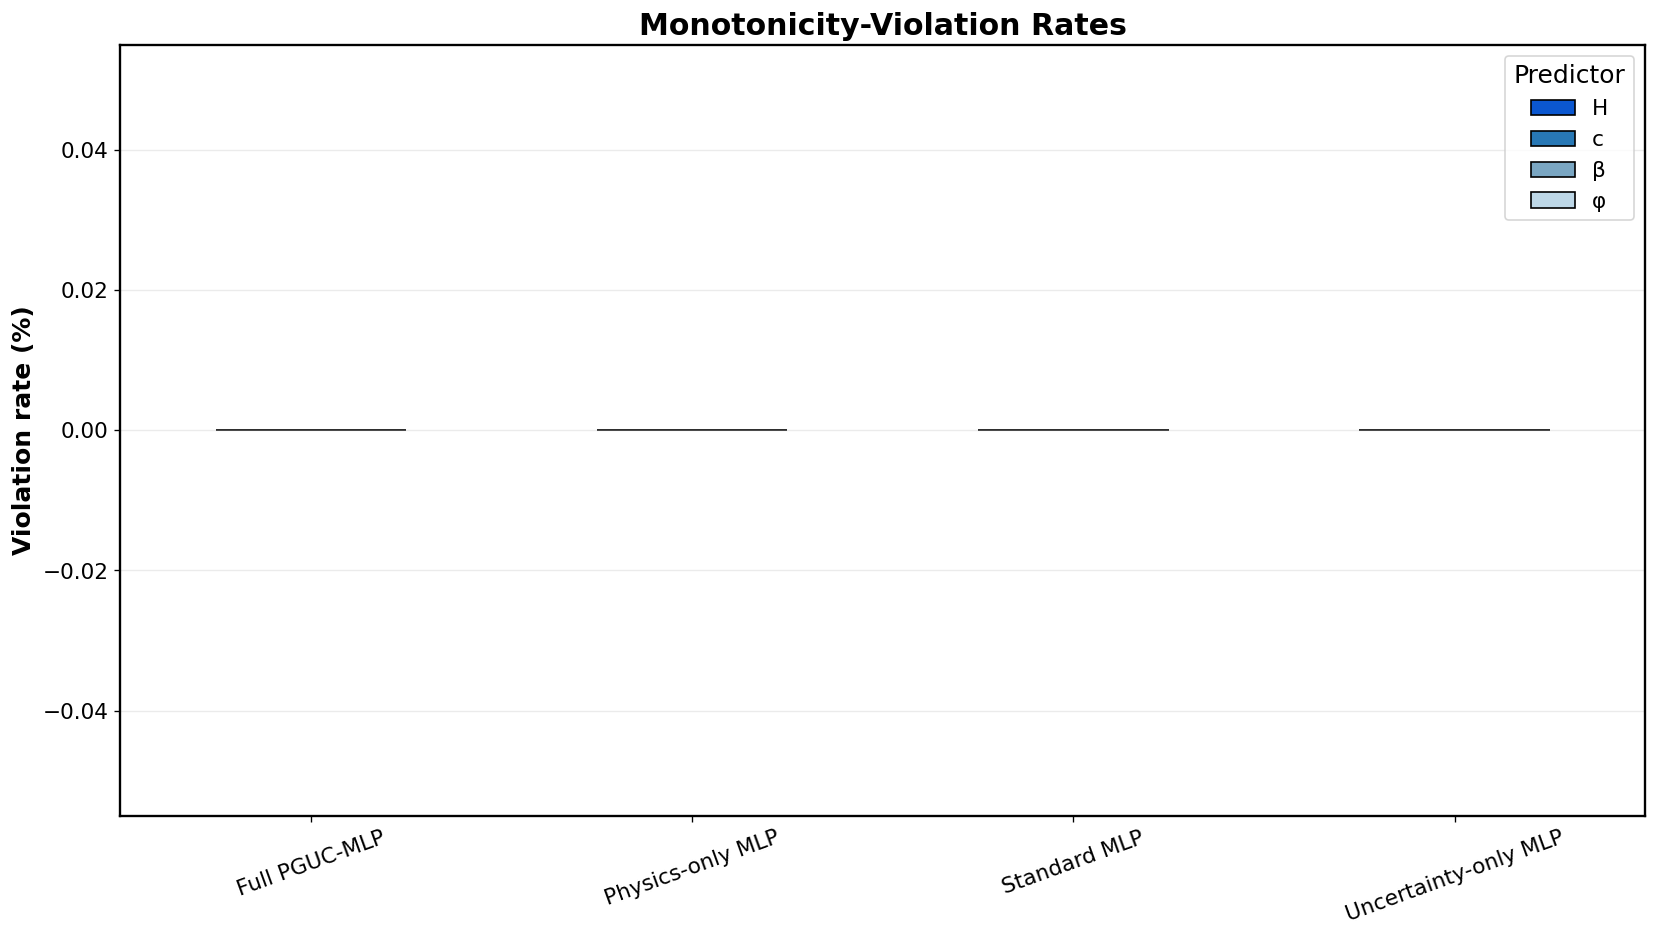

In [29]:
violation_plot = monotonicity_table.groupby(["Configuration", "Predictor"], as_index=False)["Violation rate (%)"].mean()
plot_matrix = violation_plot.pivot(index="Configuration", columns="Predictor", values="Violation rate (%)")

fig, ax = plt.subplots(figsize=(14, 8))
plot_matrix.plot(kind="bar", ax=ax, color=["#0B57D0", "#2878B5", "#7AA6C2", "#BDD7E7"], edgecolor="black")
ax.set_title("Monotonicity-Violation Rates")
ax.set_xlabel("")
ax.set_ylabel("Violation rate (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Predictor", fontsize=FONT_TICK, title_fontsize=FONT_LABEL)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, DIRS["sensitivity"], "Figure_11_Monotonicity_Violation_Rates")
plt.show()
plt.close(fig)

### 9.3 Predictor-response sensitivity curves

Each curve is an average response over a fixed development-domain reference sample. Shaded regions show mean 95% conformal interval bounds for the Full PGUC-MLP.

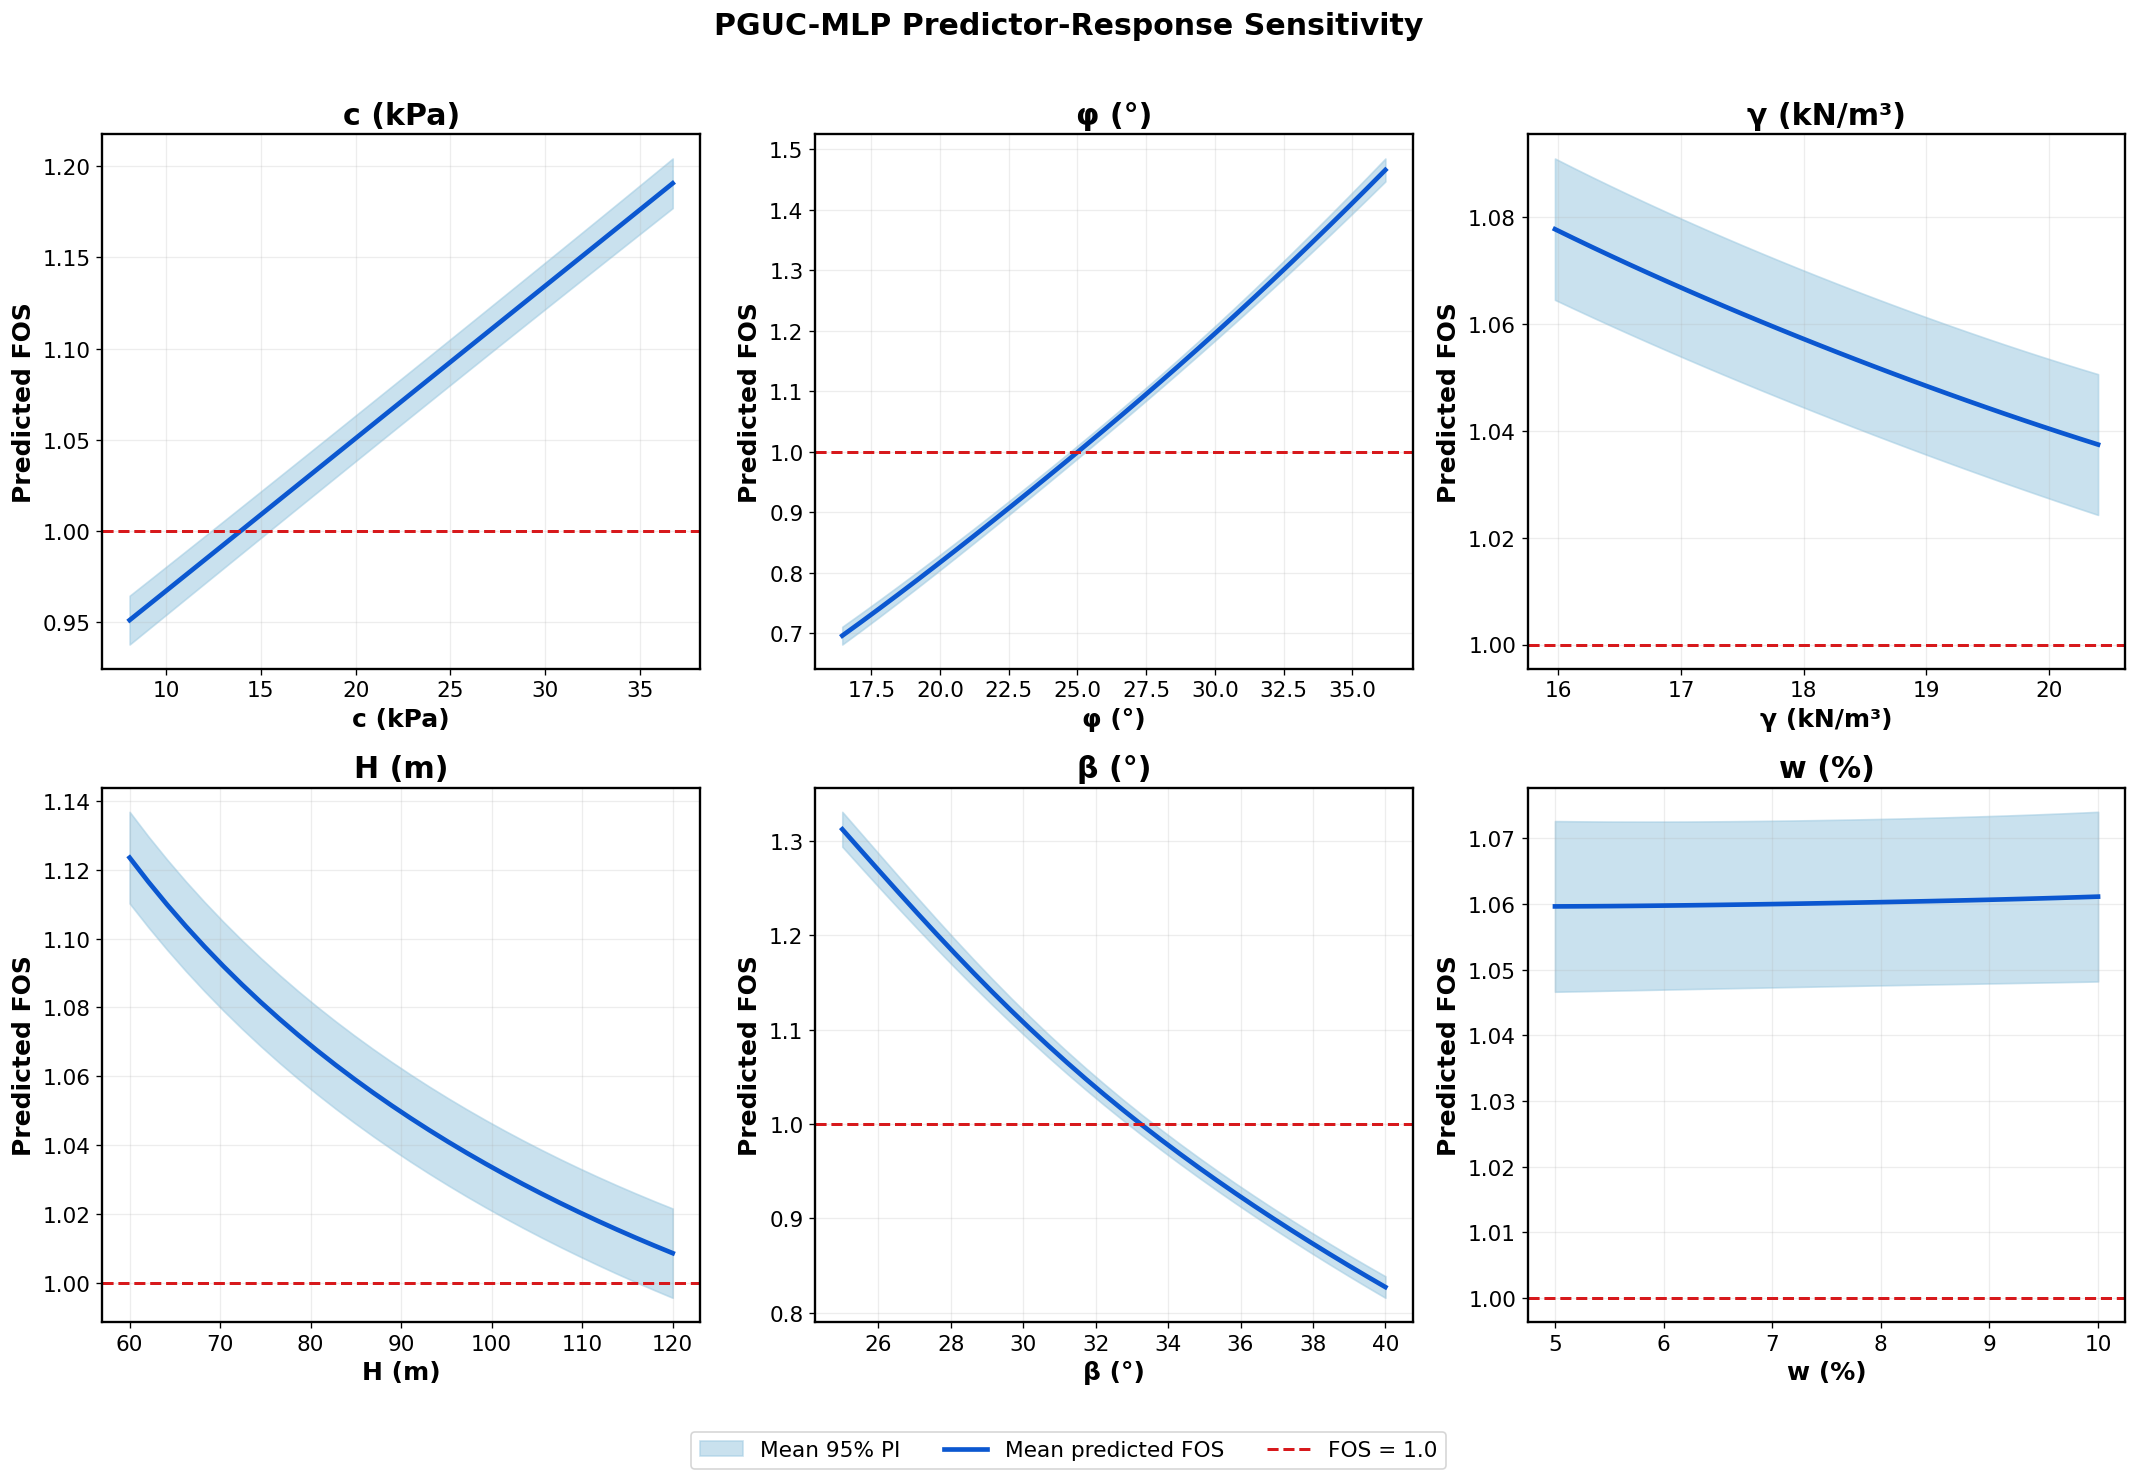

In [46]:
reference_sample = development_df.sample(n=min(300, len(development_df)), random_state=SEED + 1)
X_REFERENCE = reference_sample[FEATURES].to_numpy(dtype=np.float32)
q95 = calibration_objects["full_pguc_mlp"]["quantiles"][0.95]
sensitivity_rows = []

for feature_index, feature in enumerate(FEATURES):
    grid = np.linspace(
        np.quantile(X_DEVELOPMENT[:, feature_index], 0.05),
        np.quantile(X_DEVELOPMENT[:, feature_index], 0.95),
        30,
    )
    for value in grid:
        changed_x = X_REFERENCE.copy()
        changed_x[:, feature_index] = value
        result = predict_configuration(
            models_by_configuration["full_pguc_mlp"], FINAL_PROCESSOR, changed_x,
            FINAL_Y_MEAN, FINAL_Y_SCALE, True,
        )
        half_width = q95 * np.maximum(result["total_sigma"], 1e-8)
        sensitivity_rows.append({
            "Predictor": feature,
            "Value": value,
            "Mean predicted FOS": result["mean"].mean(),
            "Mean lower 95% PI": np.mean(result["mean"] - half_width),
            "Mean upper 95% PI": np.mean(result["mean"] + half_width),
        })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(DIRS["tables"] / "Table_Predictor_Response_Sensitivity.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for axis, feature in zip(axes.ravel(), FEATURES):
    subset = sensitivity_table[sensitivity_table["Predictor"] == feature]
    x_values = subset["Value"].to_numpy()
    mean_values = subset["Mean predicted FOS"].to_numpy()
    lower_values = subset["Mean lower 95% PI"].to_numpy()
    upper_values = subset["Mean upper 95% PI"].to_numpy()
    axis.fill_between(x_values, lower_values, upper_values, color="#9ECAE1", alpha=0.55, label="Mean 95% PI")
    axis.plot(x_values, mean_values, color="#0B57D0", linewidth=2.8, label="Mean predicted FOS")
    axis.axhline(1.0, color="#D7191C", linestyle="--", linewidth=1.8, label="FOS = 1.0")
    axis.set_title(DISPLAY_LABELS[feature])
    axis.set_xlabel(DISPLAY_LABELS[feature])
    axis.set_ylabel("Predicted FOS")
    axis.grid(alpha=0.22)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("PGUC-MLP Predictor-Response Sensitivity", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout(rect=[0, 0.04, 1, 1])
save_figure(fig, DIRS["sensitivity"], "Figure_12_Predictor_Response_Sensitivity")
plt.show()
plt.close(fig)

### 9.4 Moisture-content perturbation analysis

,Moisture perturbation (percentage points),Mean ΔFOS,Mean aleatoric SD,Mean epistemic SD,Mean 95% PI width,Mean P(FOS < 1.0) (%)
0,-2.0000,-0.0004,0.0314,0.0123,0.0259,45.8516
1,-1.0000,-0.0002,0.0313,0.0122,0.0258,45.7930
2,-0.5000,-0.0001,0.0313,0.0121,0.0258,45.7572
3,0.5000,0.0001,0.0313,0.0119,0.0258,45.6859
4,1.0000,0.0003,0.0313,0.0118,0.0258,45.6506
5,2.0000,0.0005,0.0314,0.0117,0.0258,45.6020


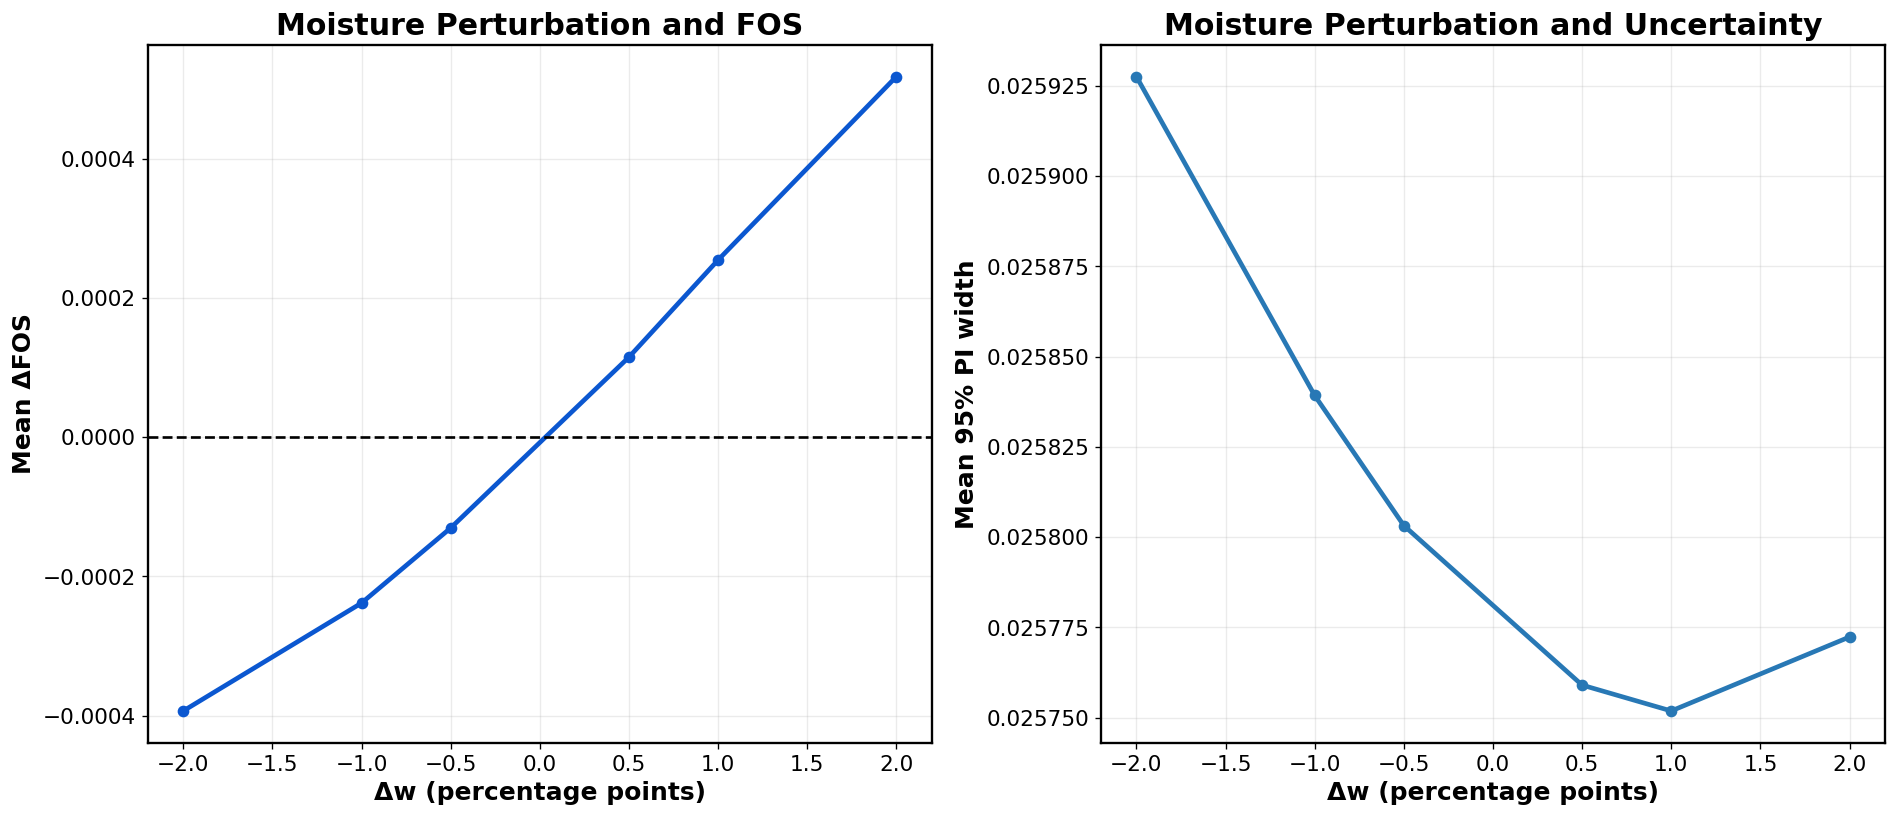

In [31]:
moisture_deltas = [-2.0, -1.0, -0.5, 0.5, 1.0, 2.0]
moisture_index = FEATURES.index("w")
moisture_min, moisture_max = FINAL_PROCESSOR.bounds[moisture_index]
moisture_reference = development_df.sample(n=min(500, len(development_df)), random_state=SEED + 2)
X_MOISTURE = moisture_reference[FEATURES].to_numpy(dtype=np.float32)
base_moisture_result = predict_configuration(
    models_by_configuration["full_pguc_mlp"], FINAL_PROCESSOR, X_MOISTURE,
    FINAL_Y_MEAN, FINAL_Y_SCALE, True,
)
moisture_rows = []

for delta in moisture_deltas:
    changed_x = X_MOISTURE.copy()
    changed_x[:, moisture_index] = np.clip(changed_x[:, moisture_index] + delta, moisture_min, moisture_max)
    result = predict_configuration(
        models_by_configuration["full_pguc_mlp"], FINAL_PROCESSOR, changed_x,
        FINAL_Y_MEAN, FINAL_Y_SCALE, True,
    )
    failure_probability = norm.cdf((1.0 - result["mean"]) / np.maximum(result["total_sigma"], 1e-8))
    interval_width = 2 * q95 * np.maximum(result["total_sigma"], 1e-8)
    moisture_rows.append({
        "Moisture perturbation (percentage points)": delta,
        "Mean ΔFOS": np.mean(result["mean"] - base_moisture_result["mean"]),
        "Mean aleatoric SD": np.sqrt(result["aleatoric_variance"]).mean(),
        "Mean epistemic SD": np.sqrt(result["epistemic_variance"]).mean(),
        "Mean 95% PI width": interval_width.mean(),
        "Mean P(FOS < 1.0) (%)": 100 * failure_probability.mean(),
    })

moisture_table = pd.DataFrame(moisture_rows)
show_table(moisture_table, caption="Moisture-content perturbation sensitivity")
moisture_table.to_csv(DIRS["tables"] / "Table_Moisture_Perturbation_Sensitivity.csv", index=False)
moisture_table.to_excel(DIRS["tables"] / "Table_Moisture_Perturbation_Sensitivity.xlsx", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].plot(
    moisture_table["Moisture perturbation (percentage points)"],
    moisture_table["Mean ΔFOS"], marker="o", linewidth=2.8, color="#0B57D0",
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1.6)
axes[0].set_title("Moisture Perturbation and FOS")
axes[0].set_xlabel("Δw (percentage points)")
axes[0].set_ylabel("Mean ΔFOS")

axes[1].plot(
    moisture_table["Moisture perturbation (percentage points)"],
    moisture_table["Mean 95% PI width"], marker="o", linewidth=2.8, color="#2878B5",
)
axes[1].set_title("Moisture Perturbation and Uncertainty")
axes[1].set_xlabel("Δw (percentage points)")
axes[1].set_ylabel("Mean 95% PI width")

for axis in axes:
    axis.grid(alpha=0.25)

fig.tight_layout()
save_figure(fig, DIRS["sensitivity"], "Figure_13_Moisture_Perturbation_Sensitivity")
plt.show()
plt.close(fig)

## 10. SHAP Explainability

### 10.1 Calculate exact six-feature SHAP values

The model wrappers accept only the six original predictors. Mechanics-informed representations are reconstructed internally. All locked test observations are explained against a development-set background.

In [32]:
background_df = development_df.sample(
    n=min(SHAP_BACKGROUND_SIZE, len(development_df)), random_state=SEED
)[FEATURES]
X_BACKGROUND = background_df.to_numpy(dtype=np.float64)
X_EXPLAIN = test_df[FEATURES].to_numpy(dtype=np.float64)

def predict_full_mean(x):
    x = np.atleast_2d(np.asarray(x, dtype=np.float32))
    return predict_configuration(
        models_by_configuration["full_pguc_mlp"], FINAL_PROCESSOR, x,
        FINAL_Y_MEAN, FINAL_Y_SCALE, True,
    )["mean"]

def predict_full_interval_width(x):
    x = np.atleast_2d(np.asarray(x, dtype=np.float32))
    result = predict_configuration(
        models_by_configuration["full_pguc_mlp"], FINAL_PROCESSOR, x,
        FINAL_Y_MEAN, FINAL_Y_SCALE, True,
    )
    return 2 * q95 * np.maximum(result["total_sigma"], 1e-8)

masker = shap.maskers.Independent(X_BACKGROUND, max_samples=len(X_BACKGROUND))
mean_explainer = shap.Explainer(
    predict_full_mean, masker, algorithm="exact", feature_names=SYMBOLS,
)
width_explainer = shap.Explainer(
    predict_full_interval_width, masker, algorithm="exact", feature_names=SYMBOLS,
)

mean_shap = mean_explainer(X_EXPLAIN, max_evals=2 ** len(FEATURES), batch_size=128)
width_shap = width_explainer(X_EXPLAIN, max_evals=2 ** len(FEATURES), batch_size=128)

mean_base = np.asarray(mean_shap.base_values).reshape(-1)
if mean_base.size == 1:
    mean_base = np.repeat(mean_base, len(X_EXPLAIN))
additivity_error = np.max(np.abs(mean_base + mean_shap.values.sum(axis=1) - predict_full_mean(X_EXPLAIN)))

shap_table = test_df[["row_id", *FEATURES, TARGET]].copy()
shap_table["Predicted FOS"] = predict_full_mean(X_EXPLAIN)
for feature_index, symbol in enumerate(SYMBOLS):
    shap_table[f"SHAP_{symbol}"] = mean_shap.values[:, feature_index]
    shap_table[f"SHAP_PI_width_{symbol}"] = width_shap.values[:, feature_index]

shap_table.to_csv(DIRS["tables"] / "Table_Local_SHAP_Values_All_Test_Cases.csv", index=False)
shap_table.to_excel(DIRS["tables"] / "Table_Local_SHAP_Values_All_Test_Cases.xlsx", index=False)
np.savez_compressed(
    DIRS["xai"] / "PGUC_MLP_SHAP_Values.npz",
    mean_values=mean_shap.values,
    mean_base_values=mean_shap.base_values,
    width_values=width_shap.values,
    width_base_values=width_shap.base_values,
    data=X_EXPLAIN,
)

shap_global_table = pd.DataFrame({
    "Predictor": SYMBOLS,
    "Mean |SHAP| for FOS": np.mean(np.abs(mean_shap.values), axis=0),
    "Mean signed SHAP for FOS": np.mean(mean_shap.values, axis=0),
    "Mean |SHAP| for 95% PI width": np.mean(np.abs(width_shap.values), axis=0),
}).sort_values("Mean |SHAP| for FOS", ascending=False)

show_table(shap_global_table, caption="Global SHAP importance")
print(f"Maximum SHAP additivity error: {additivity_error:.3e}")
shap_global_table.to_excel(DIRS["tables"] / "Table_Global_SHAP_Importance.xlsx", index=False)

ExactExplainer explainer: 340it [00:12,  8.39it/s]                         


,Predictor,Mean |SHAP| for FOS,Mean signed SHAP for FOS,Mean |SHAP| for 95% PI width
1,φ,0.1961,0.0076,0.0054
4,β,0.1612,-0.0169,0.0059
0,c,0.0631,0.0014,0.0014
3,H,0.0381,-0.0005,0.0010
2,γ,0.0097,0.0030,0.0004
5,w,0.0005,0.0000,0.0002


Maximum SHAP additivity error: 2.384e-07


### 10.2 Two-panel SHAP beeswarm figure

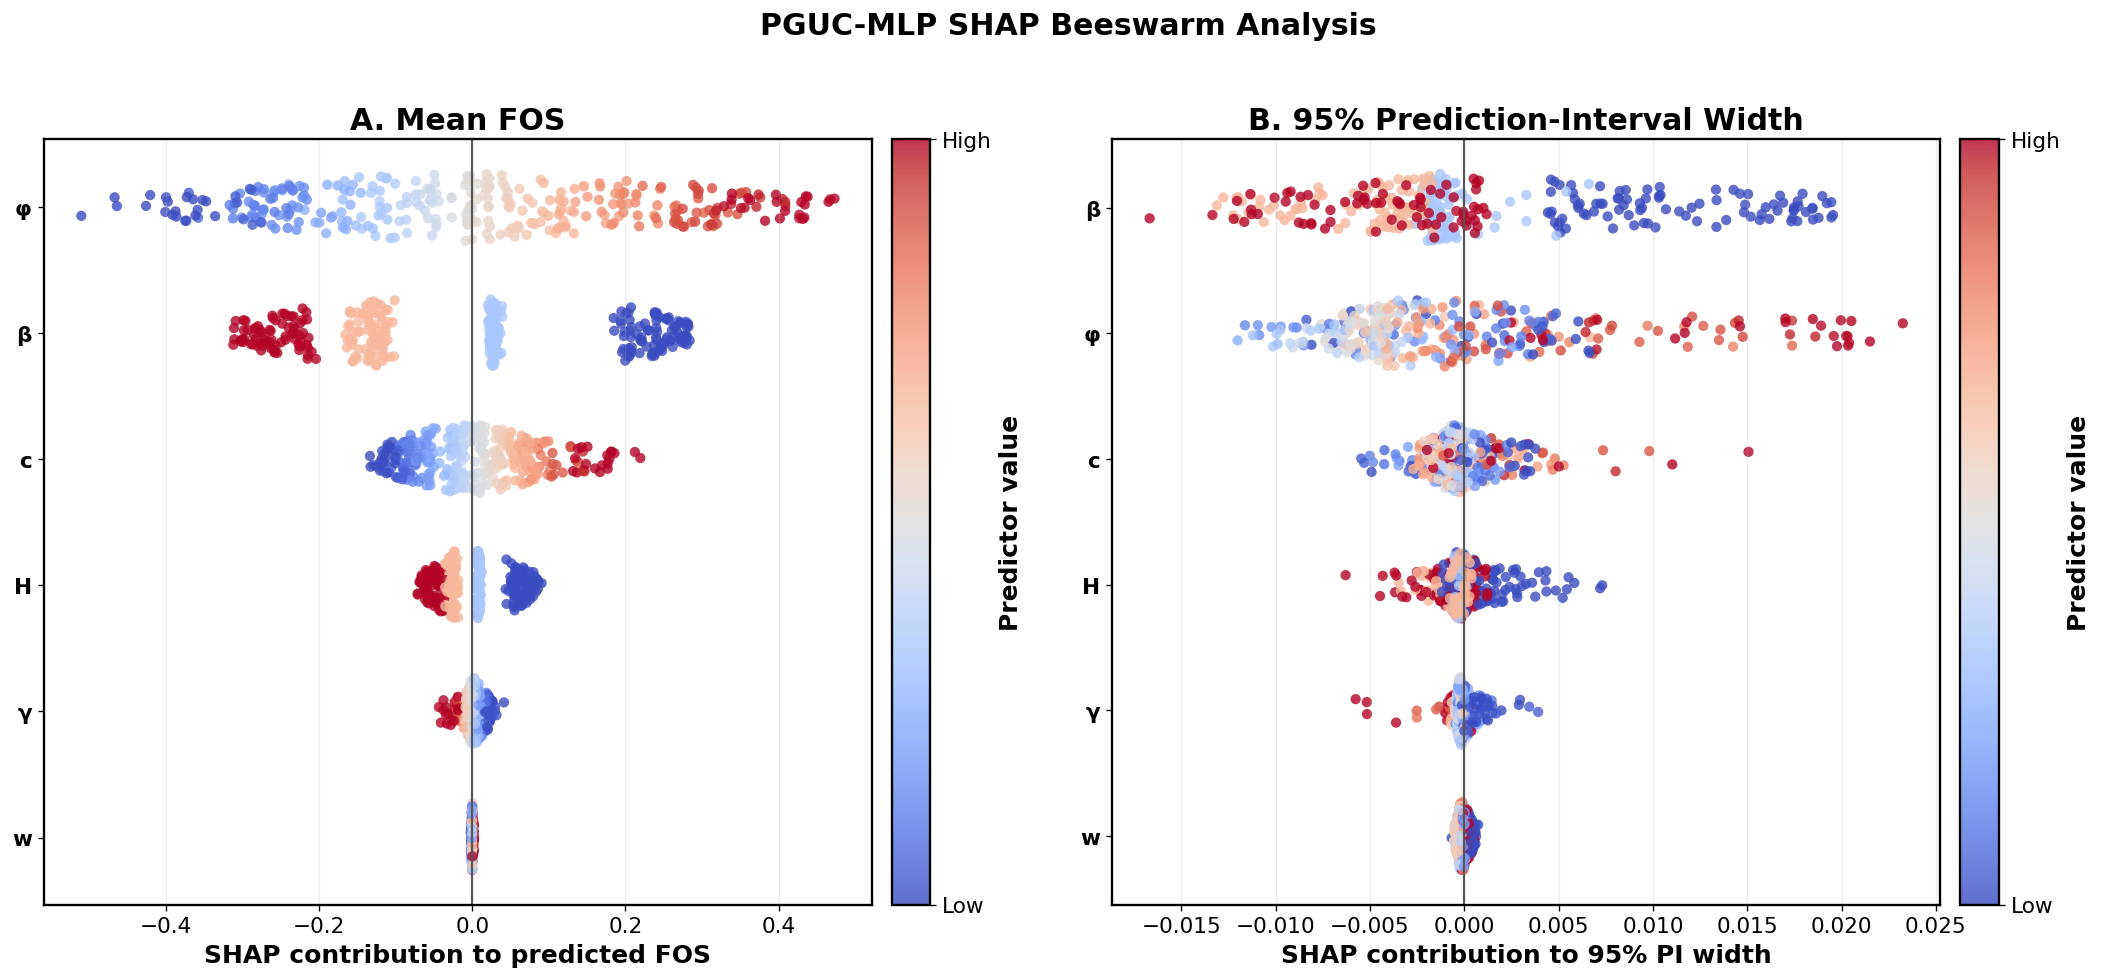

In [45]:
def beeswarm_axis(ax, shap_values, feature_values, title, seed):
    rng = np.random.default_rng(seed)
    order = np.argsort(np.mean(np.abs(shap_values), axis=0))[::-1]
    scatter = None

    for row_position, feature_index in enumerate(order):
        values = shap_values[:, feature_index]
        feature = feature_values[:, feature_index]
        ranks = stats.rankdata(values, method="average") / max(len(values), 1)
        jitter = (rng.random(len(values)) - 0.5) * 0.55 * (0.35 + 0.65 * np.sin(np.pi * ranks))
        lower, upper = np.quantile(feature, [0.05, 0.95])
        normalised = np.clip((feature - lower) / max(upper - lower, 1e-12), 0, 1)
        scatter = ax.scatter(
            values,
            np.full(len(values), row_position) + jitter,
            c=normalised,
            cmap="coolwarm",
            vmin=0,
            vmax=1,
            s=38,
            alpha=0.80,
            edgecolor="none",
        )

    ax.axvline(0, color="#555555", linewidth=1.3)
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels([SYMBOLS[index] for index in order], fontweight="bold")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.22)
    return scatter

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
scatter_a = beeswarm_axis(axes[0], mean_shap.values, X_EXPLAIN, "A. Mean FOS", SEED)
scatter_b = beeswarm_axis(axes[1], width_shap.values, X_EXPLAIN, "B. 95% Prediction-Interval Width", SEED + 1)
axes[0].set_xlabel("SHAP contribution to predicted FOS")
axes[1].set_xlabel("SHAP contribution to 95% PI width")

for axis, scatter in zip(axes, [scatter_a, scatter_b]):
    colourbar = fig.colorbar(scatter, ax=axis, pad=0.02)
    colourbar.set_ticks([0, 1])
    colourbar.set_ticklabels(["Low", "High"])
    colourbar.set_label("Predictor value", fontsize=FONT_LABEL, fontweight="bold")
    colourbar.ax.tick_params(labelsize=FONT_TICK)

fig.suptitle("PGUC-MLP SHAP Beeswarm Analysis", fontsize=FONT_TITLE, fontweight="bold", y=1.02)
fig.tight_layout()
save_figure(fig, DIRS["xai"], "Figure_14_SHAP_Beeswarm_Mean_and_Interval_Width")
plt.show()
plt.close(fig)

### 10.3 SHAP dependence plots for all predictors

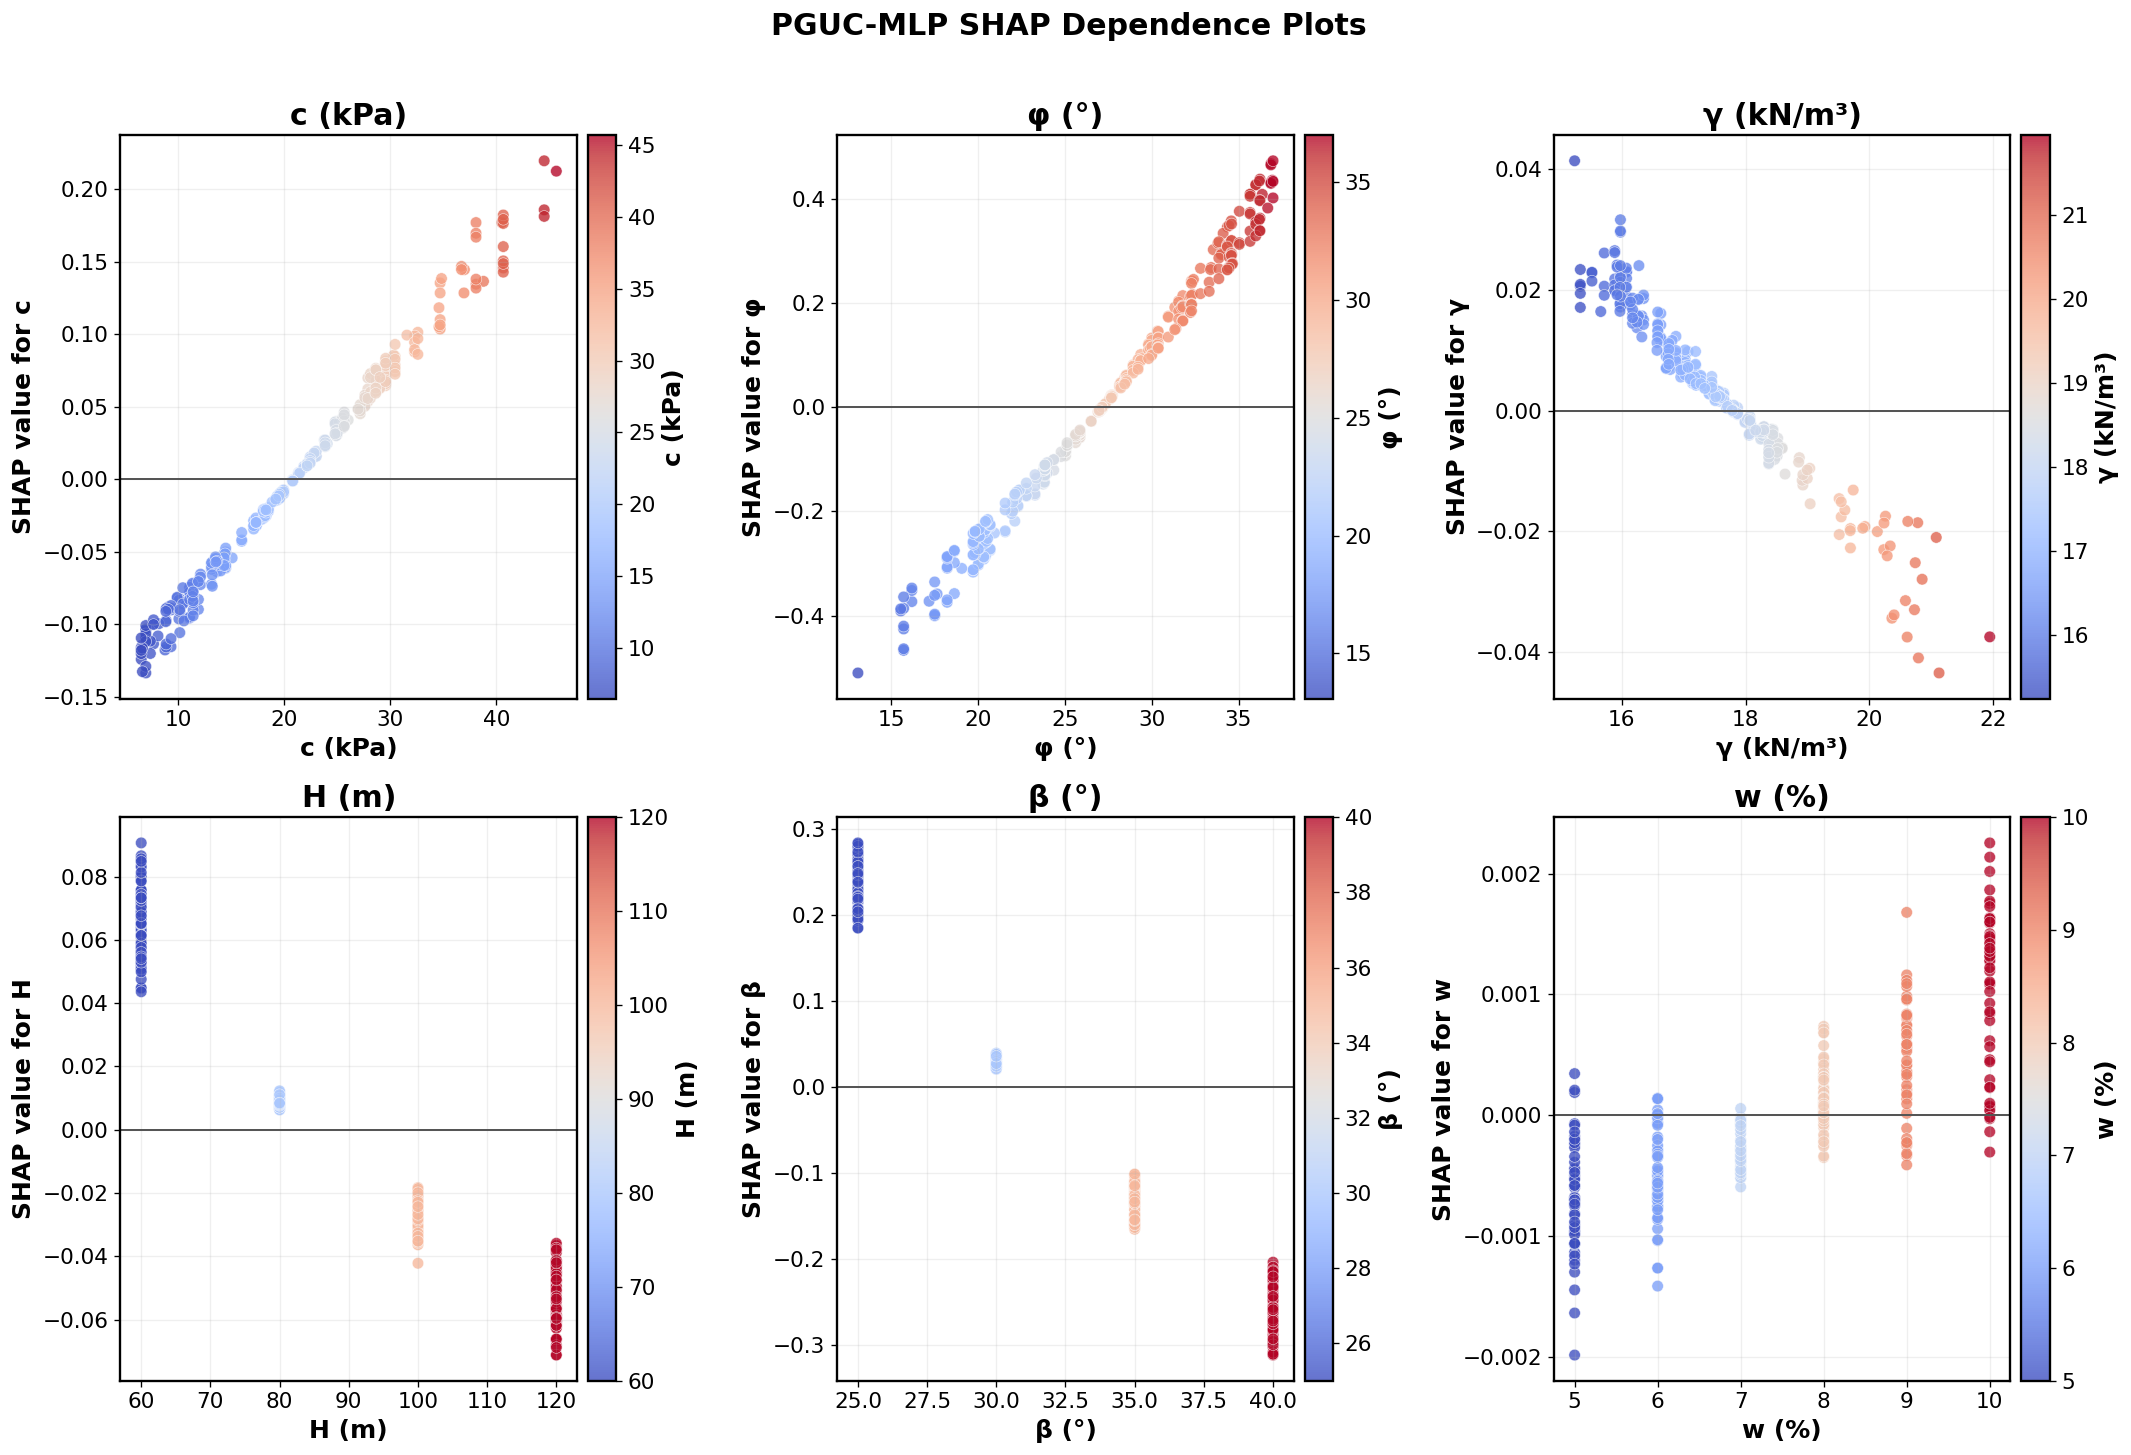

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for feature_index, (axis, feature, symbol) in enumerate(zip(axes.ravel(), FEATURES, SYMBOLS)):
    colour_values = X_EXPLAIN[:, feature_index]
    scatter = axis.scatter(
        X_EXPLAIN[:, feature_index],
        mean_shap.values[:, feature_index],
        c=colour_values,
        cmap="coolwarm",
        s=48,
        alpha=0.78,
        edgecolor="white",
        linewidth=0.35,
    )
    axis.axhline(0, color="#555555", linewidth=1.2)
    axis.set_title(DISPLAY_LABELS[feature])
    axis.set_xlabel(DISPLAY_LABELS[feature])
    axis.set_ylabel(f"SHAP value for {symbol}")
    axis.grid(alpha=0.20)
    colourbar = fig.colorbar(scatter, ax=axis, pad=0.02)
    colourbar.set_label(DISPLAY_LABELS[feature], fontsize=FONT_LABEL, fontweight="bold")
    colourbar.ax.tick_params(labelsize=FONT_TICK)

fig.suptitle("PGUC-MLP SHAP Dependence Plots", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["xai"], "Figure_15_SHAP_Dependence_All_Predictors")
plt.show()
plt.close(fig)

## 11. SHAP-IQ FSII Analysis

### 11.1 Build the order-three FSII explainer

The analysis calculates all 41 effects: 6 main effects, 15 pairwise interactions and 20 third-order interactions. Every test case uses the complete 64-coalition budget with an empirical marginal background.

In [35]:
INTERACTION_KEYS = [
    interaction
    for order in range(1, SHAPIQ_MAX_ORDER + 1)
    for interaction in combinations(range(len(FEATURES)), order)
]

if len(INTERACTION_KEYS) != 41:
    raise RuntimeError(f"Expected 41 order-one to order-three effects, found {len(INTERACTION_KEYS)}.")

def interaction_label(interaction):
    return " × ".join(SYMBOLS[index] for index in interaction)

INTERACTION_LABELS = [interaction_label(interaction) for interaction in INTERACTION_KEYS]
INTERACTION_TO_COLUMN = {interaction: index for index, interaction in enumerate(INTERACTION_KEYS)}

def shapiq_model(x):
    return predict_full_mean(np.atleast_2d(np.asarray(x, dtype=np.float32)))

fsii_explainer = shapiq.TabularExplainer(
    model=shapiq_model,
    data=X_BACKGROUND,
    index="FSII",
    max_order=SHAPIQ_MAX_ORDER,
    imputer="marginal",
    approximator="auto",
    random_state=SEED,
    verbose=False,
    sample_size=min(SHAP_BACKGROUND_SIZE, len(X_BACKGROUND)),
    categorical_features=[],
    joint_marginal_distribution=True,
)

effect_count_table = pd.DataFrame({
    "Order": [1, 2, 3, "Total"],
    "Number of effects": [6, 15, 20, 41],
})
show_table(effect_count_table, precision=0, caption="SHAP-IQ FSII effect structure")

,Order,Number of effects
0,1,6
1,2,15
2,3,20
3,Total,41


### 11.2 Calculate or resume local FSII values for all test observations

In [36]:
fsii_checkpoint = DIRS["shapiq"] / "PGUC_MLP_Local_FSII_Order3_Checkpoint.npz"
n_test = len(X_EXPLAIN)

if fsii_checkpoint.exists():
    saved = np.load(fsii_checkpoint, allow_pickle=False)
    LOCAL_FSII = saved["values"]
    PROCESSED_FSII = saved["processed"].astype(bool)
    if LOCAL_FSII.shape != (n_test, len(INTERACTION_KEYS)):
        raise RuntimeError("The saved FSII checkpoint does not match the current test set.")
else:
    LOCAL_FSII = np.full((n_test, len(INTERACTION_KEYS)), np.nan, dtype=np.float64)
    PROCESSED_FSII = np.zeros(n_test, dtype=bool)

remaining = np.where(~PROCESSED_FSII)[0]
print(f"Completed: {PROCESSED_FSII.sum():,} | Remaining: {len(remaining):,}")

for iteration, position in enumerate(tqdm(remaining, desc="Order-three FSII"), start=1):
    explanation = fsii_explainer.explain(
        X_EXPLAIN[position],
        budget=SHAPIQ_BUDGET,
        random_state=SEED + int(position),
    )
    values = {tuple(sorted(key)): float(value) for key, value in explanation.dict_values.items()}
    missing = [key for key in INTERACTION_KEYS if key not in values]
    if missing:
        raise KeyError(f"SHAP-IQ result is missing effects: {missing}")

    for interaction, column_index in INTERACTION_TO_COLUMN.items():
        LOCAL_FSII[position, column_index] = values[interaction]
    PROCESSED_FSII[position] = True

    if iteration % SHAPIQ_CHECKPOINT_EVERY == 0 or iteration == len(remaining):
        np.savez_compressed(fsii_checkpoint, values=LOCAL_FSII, processed=PROCESSED_FSII)

if not np.isfinite(LOCAL_FSII).all():
    raise RuntimeError("FSII computation contains missing or infinite values.")

local_fsii_table = pd.DataFrame(LOCAL_FSII, columns=INTERACTION_LABELS)
local_fsii_table.insert(0, "row_id", test_df["row_id"].to_numpy())
local_fsii_table.to_csv(DIRS["tables"] / "Table_Local_FSII_All_Test_Cases.csv", index=False)
local_fsii_table.to_excel(DIRS["tables"] / "Table_Local_FSII_All_Test_Cases.xlsx", index=False)
print("All local FSII values are complete.")

Completed: 0 | Remaining: 339


Order-three FSII:   0%|          | 0/339 [00:00<?, ?it/s]

All local FSII values are complete.


### 11.3 Aggregate and display global FSII effects

In [37]:
global_fsii_rows = []

for column_index, interaction in enumerate(INTERACTION_KEYS):
    values = LOCAL_FSII[:, column_index]
    features = [SYMBOLS[index] for index in interaction]
    global_fsii_rows.append({
        "Feature set": interaction_label(interaction),
        "Order": len(interaction),
        "Feature 1": features[0],
        "Feature 2": features[1] if len(features) >= 2 else "",
        "Feature 3": features[2] if len(features) >= 3 else "",
        "Interaction magnitude": np.mean(np.abs(values)),
        "Mean signed FSII": np.mean(values),
        "FSII SD": np.std(values, ddof=1),
        "Positive fraction": np.mean(values > 0),
        "Negative fraction": np.mean(values < 0),
    })

global_fsii_table = (
    pd.DataFrame(global_fsii_rows)
    .sort_values("Interaction magnitude", ascending=False)
    .reset_index(drop=True)
)
top15_fsii = global_fsii_table.head(15).copy()

show_table(top15_fsii, caption="Top 15 global SHAP-IQ FSII effects")
global_fsii_table.to_csv(DIRS["tables"] / "Table_SHAP_IQ_All_41_FSII_Effects.csv", index=False)
global_fsii_table.to_excel(DIRS["tables"] / "Table_SHAP_IQ_All_41_FSII_Effects.xlsx", index=False)
top15_fsii.to_excel(DIRS["tables"] / "Table_SHAP_IQ_Top15_FSII_Effects.xlsx", index=False)

,Feature set,Order,Feature 1,Feature 2,Feature 3,Interaction magnitude,Mean signed FSII,FSII SD,Positive fraction,Negative fraction
0,φ,1,φ,,,0.1979,0.0079,0.2347,0.5192,0.4808
1,β,1,β,,,0.1609,-0.0163,0.1846,0.5369,0.4631
2,c,1,c,,,0.0628,0.0002,0.0761,0.4749,0.5251
3,H,1,H,,,0.0372,-0.0006,0.0428,0.5044,0.4956
4,φ × β,2,φ,β,,0.0329,-0.0002,0.0441,0.4779,0.5221
5,c × H,2,c,H,,0.0105,0.0020,0.0148,0.5605,0.4395
6,γ,1,γ,,,0.0093,0.0033,0.0112,0.6578,0.3422
7,c × γ,2,c,γ,,0.0031,0.0008,0.0049,0.6106,0.3894
8,φ × H,2,φ,H,,0.0021,-0.0002,0.0029,0.4454,0.5546
9,γ × H,2,γ,H,,0.0021,-0.0012,0.0027,0.2389,0.7611


### 11.4 Publication-quality SHAP-IQ UpSet plot

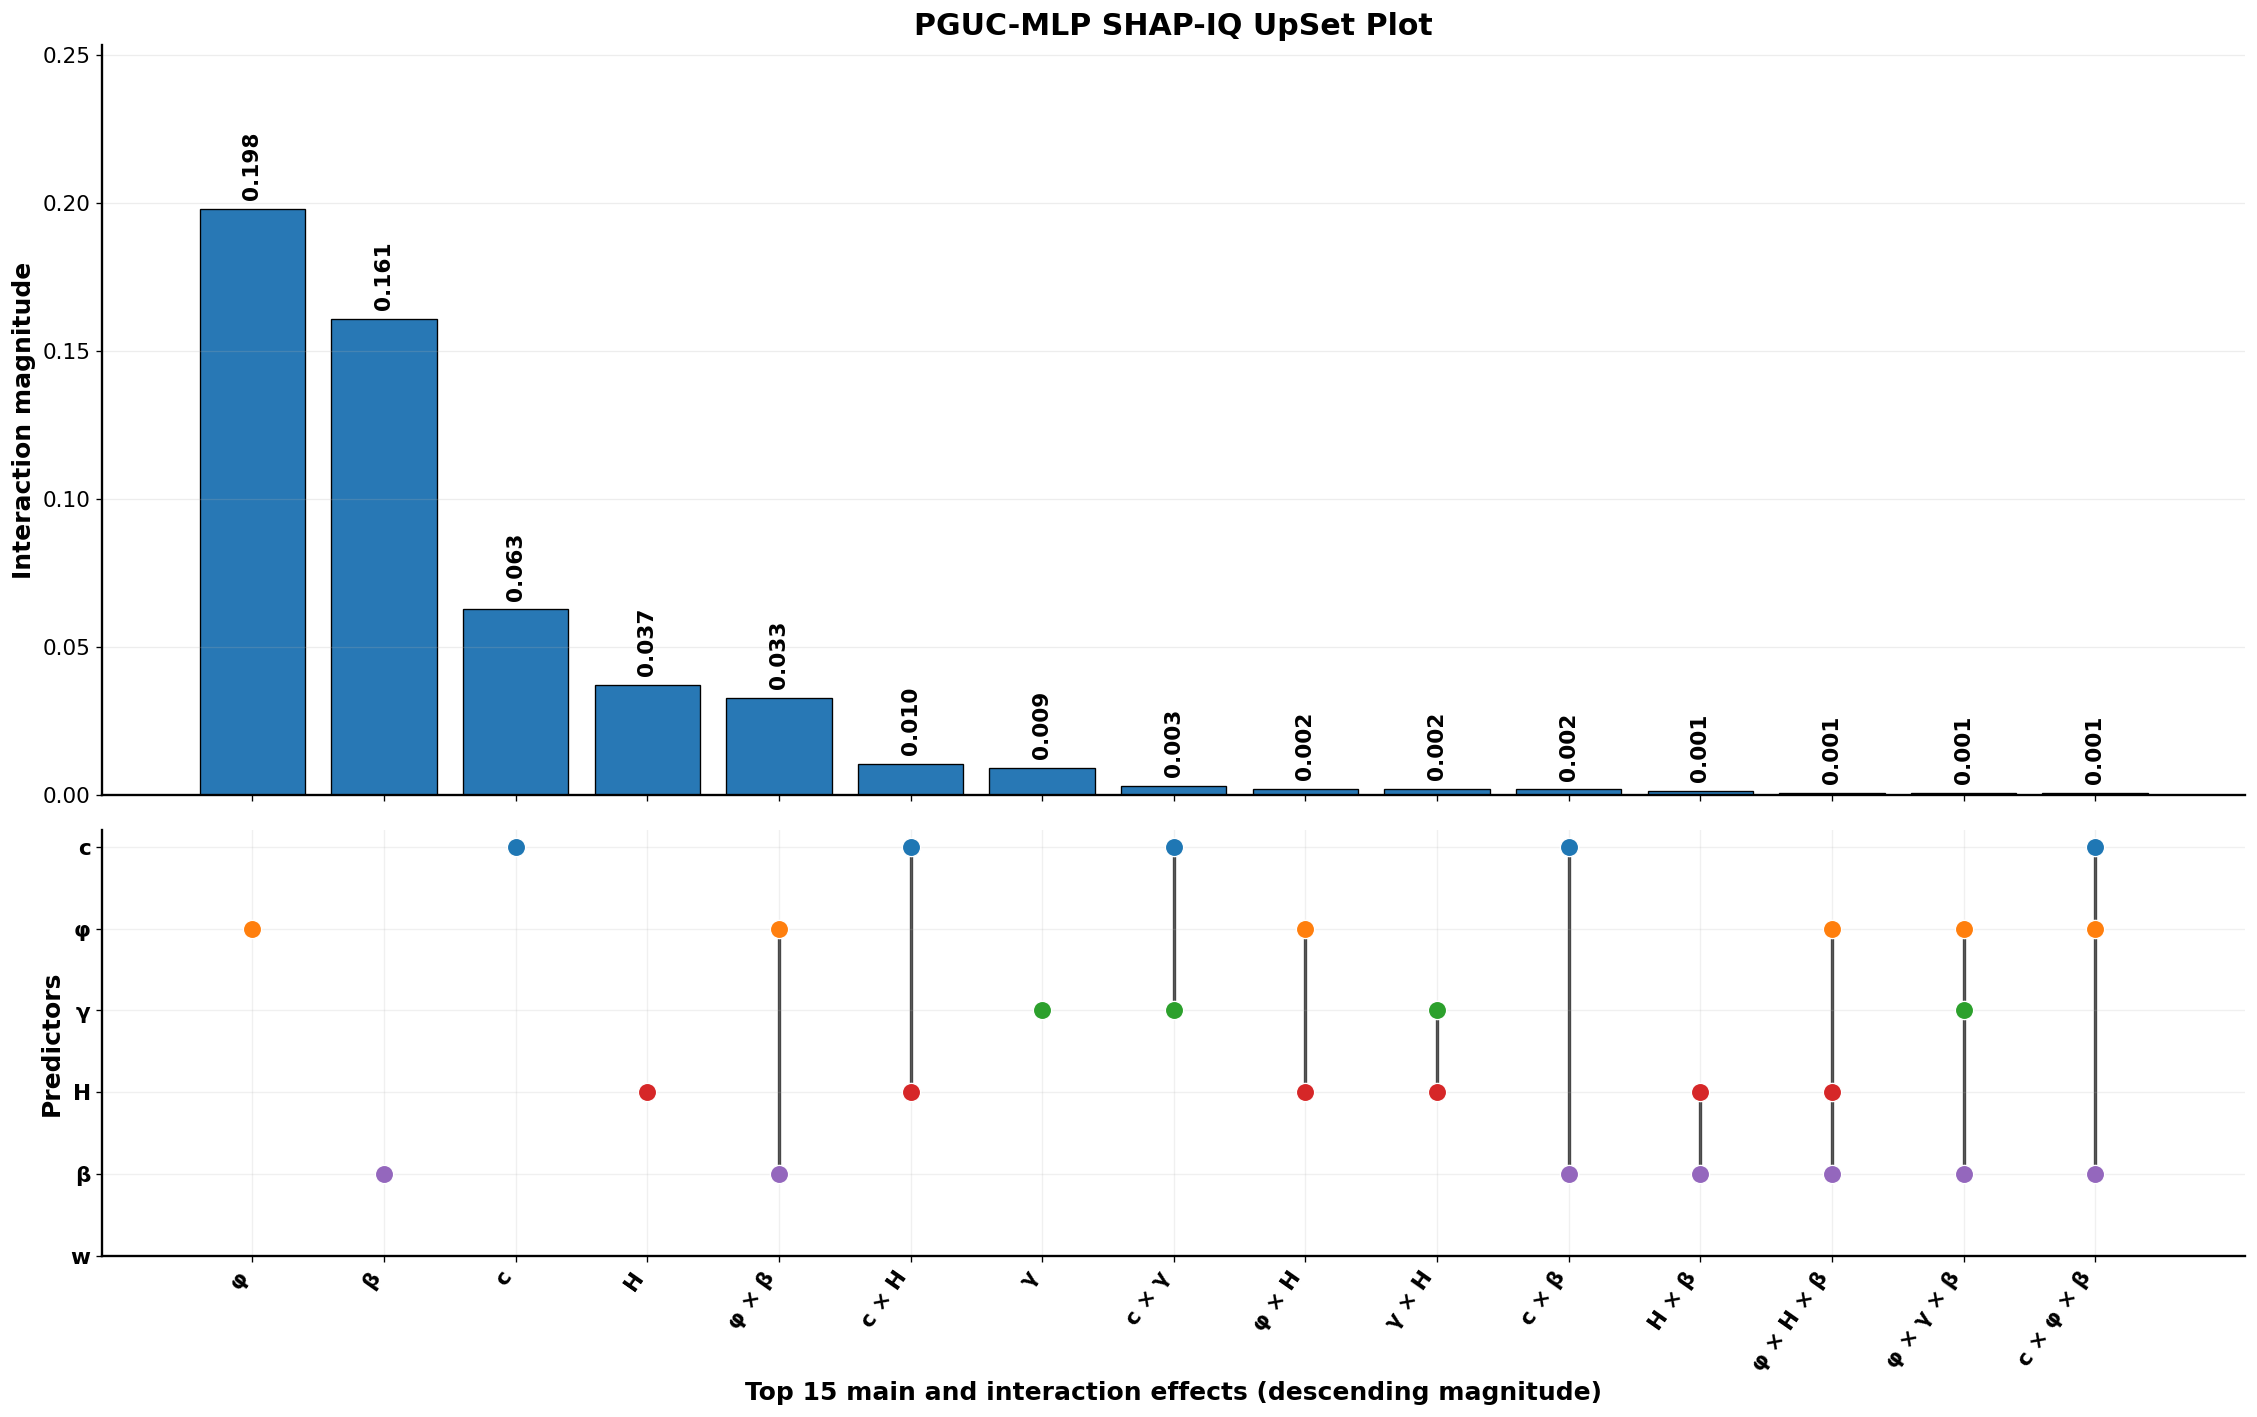

In [38]:
FEATURE_COLOURS = {
    "c": "#1F77B4",
    "φ": "#FF7F0E",
    "γ": "#2CA02C",
    "H": "#D62728",
    "β": "#9467BD",
    "w": "#17BECF",
}

def plot_shapiq_upset(effect_table):
    top = effect_table.head(15).copy().sort_values("Interaction magnitude", ascending=False).reset_index(drop=True)
    feature_to_y = {feature: index for index, feature in enumerate(SYMBOLS)}
    x_positions = np.arange(len(top))
    bar_values = top["Interaction magnitude"].to_numpy(dtype=float)

    fig, (ax_bar, ax_matrix) = plt.subplots(
        2, 1, figsize=(19, 12), sharex=True,
        gridspec_kw={"height_ratios": [3.0, 1.7]},
    )

    bars = ax_bar.bar(x_positions, bar_values, color="#2878B5", edgecolor="black", linewidth=0.8)
    ax_bar.set_title("PGUC-MLP SHAP-IQ UpSet Plot")
    ax_bar.set_ylabel("Interaction magnitude")
    ax_bar.grid(axis="y", alpha=0.22)
    ax_bar.set_ylim(0, max(bar_values) * 1.28 if max(bar_values) > 0 else 1)

    for bar, value in zip(bars, bar_values):
        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            value + max(bar_values) * 0.015,
            f"{value:.3f}",
            ha="center", va="bottom", rotation=90,
            fontsize=FONT_TICK, fontweight="bold",
        )

    for x_position, (_, row) in zip(x_positions, top.iterrows()):
        involved = [row["Feature 1"]]
        if row["Feature 2"]:
            involved.append(row["Feature 2"])
        if row["Feature 3"]:
            involved.append(row["Feature 3"])
        y_values = [feature_to_y[feature] for feature in involved]
        if len(y_values) > 1:
            ax_matrix.plot([x_position, x_position], [min(y_values), max(y_values)], color="#444444", linewidth=2.0, zorder=1)
        for feature, y_value in zip(involved, y_values):
            ax_matrix.scatter(
                x_position, y_value, s=120, color=FEATURE_COLOURS[feature],
                edgecolor="white", linewidth=0.8, zorder=3,
            )

    ax_matrix.set_yticks(np.arange(len(SYMBOLS)))
    ax_matrix.set_yticklabels(SYMBOLS, fontweight="bold")
    ax_matrix.invert_yaxis()
    ax_matrix.set_xticks(x_positions)
    ax_matrix.set_xticklabels(top["Feature set"], rotation=55, ha="right", fontweight="bold")
    ax_matrix.set_xlabel("Top 15 main and interaction effects (descending magnitude)")
    ax_matrix.set_ylabel("Predictors")
    ax_matrix.grid(alpha=0.18)

    for axis in (ax_bar, ax_matrix):
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    fig.tight_layout()
    save_figure(fig, DIRS["shapiq"], "Figure_16_SHAP_IQ_Order3_Top15_UpSet")
    plt.show()
    plt.close(fig)

plot_shapiq_upset(global_fsii_table)

## 12. Local Shapley InFlow Visualisation

### 12.1 Select the representative locked-test case and prepare accountable contributions

The representative case is the real test observation whose predicted FOS is closest to the test-set mean prediction. Direct arrows are local SHAP contributions. Pairwise and third-order FSII pathways are interaction overlays and are not added again to the SHAP total.

In [39]:
representative_position = int(np.argmin(np.abs(full_result["mean"] - full_result["mean"].mean())))
representative_row = test_df.iloc[representative_position]
representative_shap = mean_shap.values[representative_position]
representative_fsii = LOCAL_FSII[representative_position]
representative_base = float(mean_base[representative_position])

local_interactions = pd.DataFrame({
    "Interaction": INTERACTION_LABELS,
    "Key": INTERACTION_KEYS,
    "Order": [len(key) for key in INTERACTION_KEYS],
    "Local FSII": representative_fsii,
})
local_interactions["Magnitude"] = local_interactions["Local FSII"].abs()

selected_pairwise = local_interactions[local_interactions["Order"] == 2].nlargest(2, "Magnitude")
selected_third_order = local_interactions[local_interactions["Order"] == 3].nlargest(2, "Magnitude")
selected_inflow_interactions = pd.concat([selected_pairwise, selected_third_order], ignore_index=True)

representative_table = pd.DataFrame({
    "Item": [
        "Test row ID", *SYMBOLS, "SHAP baseline FOS", "Predicted FOS", "Actual FOS",
        "Lower 95% PI", "Upper 95% PI", "SHAP reconstruction error",
    ],
    "Value": [
        int(representative_row["row_id"]),
        *[representative_row[feature] for feature in FEATURES],
        representative_base,
        full_result["mean"][representative_position],
        Y_TEST[representative_position],
        full_result["lower_95"][representative_position],
        full_result["upper_95"][representative_position],
        representative_base + representative_shap.sum() - full_result["mean"][representative_position],
    ],
})

local_shap_table = pd.DataFrame({
    "Predictor": SYMBOLS,
    "Observed value": [representative_row[feature] for feature in FEATURES],
    "Local SHAP contribution": representative_shap,
}).sort_values("Local SHAP contribution", key=np.abs, ascending=False)

show_table(representative_table, caption="Representative InFlow test case")
show_table(local_shap_table, caption="Local SHAP contributions")
show_table(selected_inflow_interactions[["Interaction", "Order", "Local FSII", "Magnitude"]], caption="Displayed local FSII interaction overlays")

with pd.ExcelWriter(DIRS["tables"] / "Table_Shapley_InFlow_Representative_Case.xlsx") as writer:
    representative_table.to_excel(writer, sheet_name="Case", index=False)
    local_shap_table.to_excel(writer, sheet_name="Local SHAP", index=False)
    selected_inflow_interactions.drop(columns="Key").to_excel(writer, sheet_name="Interaction overlays", index=False)

,Item,Value
0,Test row ID,347.0000
1,c,13.6986
2,φ,23.7466
3,γ,17.5427
4,H,100.0000
5,β,25.0000
6,w,10.0000
7,SHAP baseline FOS,1.0941
8,Predicted FOS,1.0894
9,Actual FOS,1.0969


,Predictor,Observed value,Local SHAP contribution
4,β,25.0000,0.2195
1,φ,23.7466,-0.1478
0,c,13.6986,-0.0574
3,H,100.0000,-0.0228
2,γ,17.5427,0.0023
5,w,10.0000,0.0014


,Interaction,Order,Local FSII,Magnitude
0,φ × β,2,-0.0350,0.0350
1,c × H,2,0.0082,0.0082
2,φ × β × w,3,0.0006,0.0006
3,φ × γ × β,3,-0.0004,0.0004


### 12.2 Draw the local Shapley InFlow network

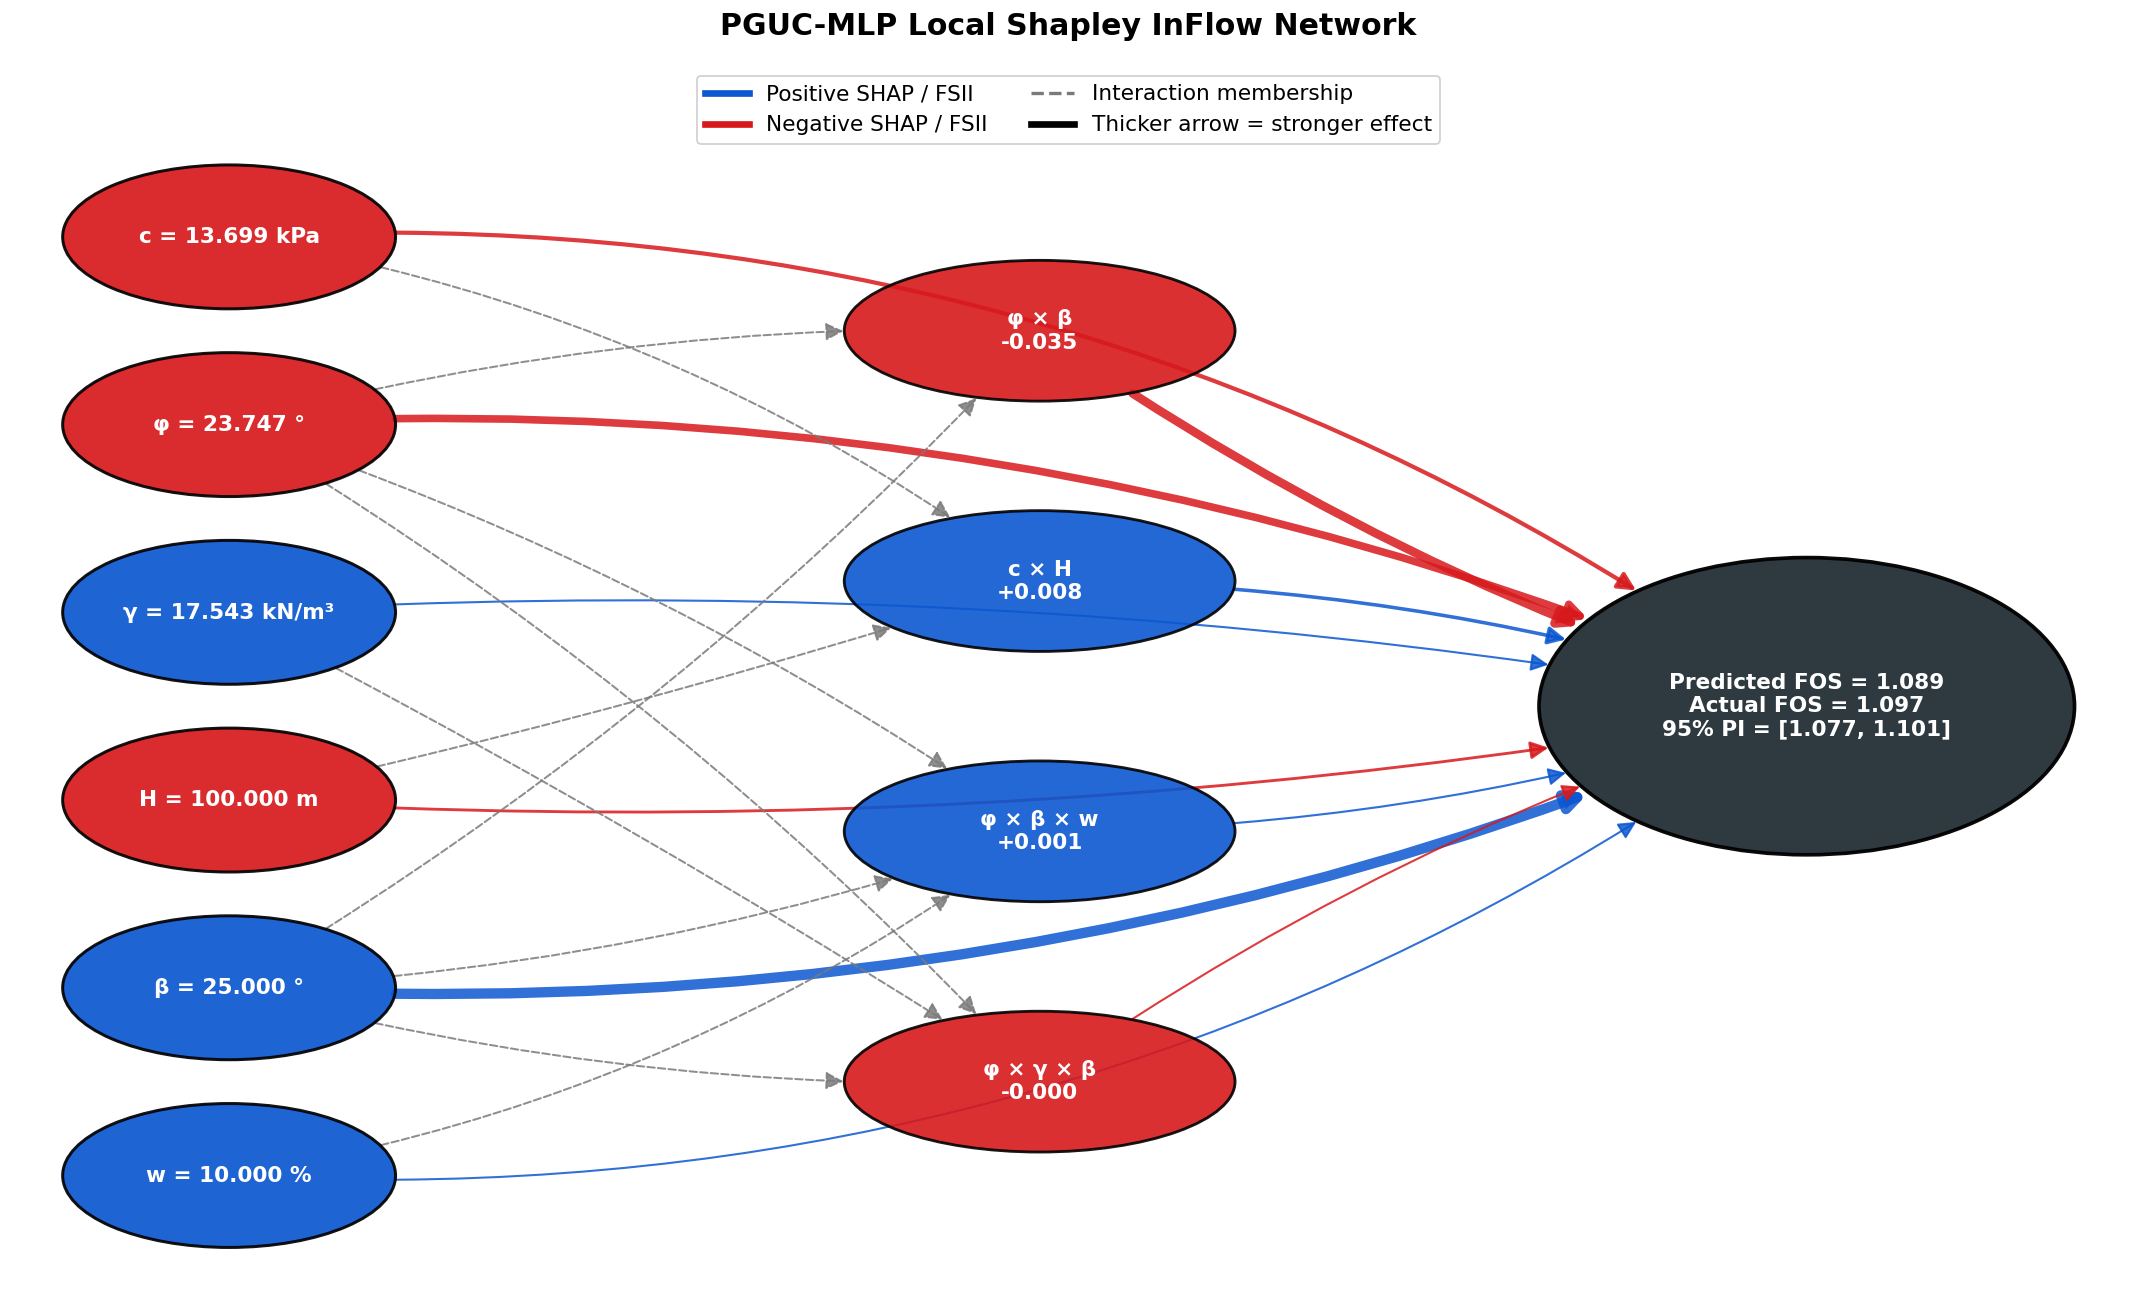

In [43]:
def contribution_colour(value):
    return "#0B57D0" if value >= 0 else "#D7191C"


def draw_anchored_arrow(
    ax,
    source,
    target,
    source_patch,
    target_patch,
    colour,
    width,
    radius=0.0,
    linestyle="-",
):
    arrow = FancyArrowPatch(
        source,
        target,
        connectionstyle=f"arc3,rad={radius}",
        arrowstyle="-|>",
        mutation_scale=22,
        linewidth=width,
        linestyle=linestyle,
        color=colour,
        alpha=0.85,
        patchA=source_patch,
        patchB=target_patch,
        shrinkA=0,
        shrinkB=0,
        zorder=2,
    )
    ax.add_patch(arrow)


feature_positions = {
    "c": (-2.8, 1.50),
    "φ": (-2.8, 0.90),
    "γ": (-2.8, 0.30),
    "H": (-2.8, -0.30),
    "β": (-2.8, -0.90),
    "w": (-2.8, -1.50),
}

interaction_positions = [
    (0.0, 1.20),
    (0.0, 0.40),
    (0.0, -0.40),
    (0.0, -1.20),
]

output_position = (2.65, 0.0)

fig, ax = plt.subplots(figsize=(18, 11))
patches = {}


# Predictor nodes
for feature, symbol, shap_value in zip(
    FEATURES,
    SYMBOLS,
    representative_shap,
):
    position = feature_positions[symbol]

    ellipse = Ellipse(
        position,
        width=1.15,
        height=0.46,
        facecolor=contribution_colour(shap_value),
        edgecolor="black",
        linewidth=1.8,
        alpha=0.92,
        zorder=8,
    )
    ax.add_patch(ellipse)
    patches[symbol] = ellipse

    value = representative_row[feature]
    unit = UNITS[feature]

    ax.text(
        position[0],
        position[1],
        f"{symbol} = {value:.3f} {unit}".strip(),
        ha="center",
        va="center",
        color="white",
        fontsize=FONT_TICK,
        fontweight="bold",
        zorder=9,
    )


# Output node
output_patch = Ellipse(
    output_position,
    width=1.85,
    height=0.95,
    facecolor="#263238",
    edgecolor="black",
    linewidth=2.2,
    alpha=0.96,
    zorder=8,
)
ax.add_patch(output_patch)
patches["FOS"] = output_patch

ax.text(
    output_position[0],
    output_position[1],
    f"Predicted FOS = "
    f"{full_result['mean'][representative_position]:.3f}\n"
    f"Actual FOS = "
    f"{Y_TEST[representative_position]:.3f}\n"
    f"95% PI = ["
    f"{full_result['lower_95'][representative_position]:.3f}, "
    f"{full_result['upper_95'][representative_position]:.3f}]",
    ha="center",
    va="center",
    color="white",
    fontsize=FONT_TICK,
    fontweight="bold",
    zorder=9,
)


# Direct SHAP pathways
max_shap = max(
    float(np.max(np.abs(representative_shap))),
    1e-12,
)

direct_radii = [
    -0.18,
    -0.12,
    -0.06,
    0.06,
    0.12,
    0.18,
]

for symbol, shap_value, radius in zip(
    SYMBOLS,
    representative_shap,
    direct_radii,
):
    width = 1.2 + 5.0 * abs(shap_value) / max_shap

    draw_anchored_arrow(
        ax=ax,
        source=feature_positions[symbol],
        target=output_position,
        source_patch=patches[symbol],
        target_patch=output_patch,
        colour=contribution_colour(shap_value),
        width=width,
        radius=radius,
    )


# Interaction pathways
displayed_interactions = selected_inflow_interactions.head(
    len(interaction_positions)
).copy()

max_interaction = max(
    float(displayed_interactions["Magnitude"].max()),
    1e-12,
)

for interaction_number, (
    (_, interaction_row),
    position,
) in enumerate(
    zip(
        displayed_interactions.iterrows(),
        interaction_positions,
    )
):
    interaction_value = float(interaction_row["Local FSII"])
    interaction_label = str(interaction_row["Interaction"])

    interaction_patch = Ellipse(
        position,
        width=1.35,
        height=0.45,
        facecolor=contribution_colour(interaction_value),
        edgecolor="black",
        linewidth=1.7,
        alpha=0.90,
        zorder=8,
    )
    ax.add_patch(interaction_patch)

    ax.text(
        position[0],
        position[1],
        f"{interaction_label}\n{interaction_value:+.3f}",
        ha="center",
        va="center",
        color="white",
        fontsize=FONT_TICK,
        fontweight="bold",
        zorder=9,
    )

    for member_index in interaction_row["Key"]:
        member_symbol = SYMBOLS[int(member_index)]

        draw_anchored_arrow(
            ax=ax,
            source=feature_positions[member_symbol],
            target=position,
            source_patch=patches[member_symbol],
            target_patch=interaction_patch,
            colour="#7A7A7A",
            width=1.2,
            radius=0.05 * (int(member_index) - 2.5),
            linestyle="--",
        )

    width = (
        1.2
        + 4.0 * abs(interaction_value) / max_interaction
    )

    draw_anchored_arrow(
        ax=ax,
        source=position,
        target=output_position,
        source_patch=interaction_patch,
        target_patch=output_patch,
        colour=contribution_colour(interaction_value),
        width=width,
        radius=(
            0.08
            if interaction_number % 2 == 0
            else -0.08
        ),
    )


# Legend
legend_items = [
    Line2D(
        [0],
        [0],
        color="#0B57D0",
        linewidth=4,
        label="Positive SHAP / FSII",
    ),
    Line2D(
        [0],
        [0],
        color="#D7191C",
        linewidth=4,
        label="Negative SHAP / FSII",
    ),
    Line2D(
        [0],
        [0],
        color="#7A7A7A",
        linewidth=2,
        linestyle="--",
        label="Interaction membership",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linewidth=4,
        label="Thicker arrow = stronger effect",
    ),
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    ncol=2,
    fontsize=FONT_TICK,
    frameon=True,
    framealpha=0.95,
)

ax.set_title(
    "PGUC-MLP Local Shapley InFlow Network",
    fontsize=FONT_TITLE,
    fontweight="bold",
    pad=18,
)

ax.set_xlim(-3.55, 3.75)
ax.set_ylim(-1.85, 2.05)
ax.axis("off")

fig.tight_layout()

save_figure(
    fig,
    DIRS["inflow"],
    "Figure_17_Local_Shapley_InFlow",
)

plt.show()
plt.close(fig)

## 13. Reproducibility Record and Output Index

### 13.1 Save the final run metadata and display key outputs

In [41]:
package_names = ["numpy", "pandas", "scikit-learn", "torch", "optuna", "shap", "shapiq", "matplotlib", "seaborn"]
package_versions = {}
for package in package_names:
    try:
        package_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        package_versions[package] = "not available"

metadata_record = {
    "title": "Physics-Guided, Uncertainty-Calibrated and Explainable Deep Learning for Factor-of-Safety Prediction of Mine Dump Slopes",
    "dataset": str(DATA_PATH),
    "sheet": SHEET_NAME,
    "predictors": dict(zip(SYMBOLS, FEATURES)),
    "target": TARGET,
    "split": {name: len(frame) for name, frame in subset_frames.items()},
    "group_definition": ["c", "phi", "gamma", "w"],
    "seed": SEED,
    "ensemble_seeds": ENSEMBLE_SEEDS,
    "best_hyperparameters": BEST_PARAMS,
    "final_epochs": CV_EPOCHS,
    "conformal_quantiles": {
        key: {str(level): value for level, value in item["quantiles"].items()}
        for key, item in calibration_objects.items()
    },
    "SHAP_IQ": {"index": "FSII", "maximum_order": 3, "effects": 41, "coalition_budget": 64},
    "device": str(DEVICE),
    "package_versions": package_versions,
}

metadata_path = PROJECT_DIR / "PGUC_MLP_Run_Metadata.json"
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata_record, file, indent=2, ensure_ascii=False)

output_files = sorted(
    [path for folder in DIRS.values() for path in Path(folder).rglob("*") if path.is_file()],
    key=lambda path: str(path),
)
output_index = pd.DataFrame({
    "File": [path.name for path in output_files],
    "Category": [path.parent.name for path in output_files],
    "Path": [str(path) for path in output_files],
})
output_index.to_csv(PROJECT_DIR / "PGUC_MLP_Output_Index.csv", index=False)

key_outputs = pd.DataFrame({
    "Deliverable": [
        "Locked-test performance table",
        "Manuscript-ready ablation table",
        "SHAP beeswarm figure",
        "SHAP-IQ UpSet figure",
        "Shapley InFlow figure",
        "Run metadata",
    ],
    "Location": [
        str(DIRS["tables"] / "Table_Locked_Test_Performance.xlsx"),
        str(DIRS["tables"] / "Table_Manuscript_Ready_Ablation.xlsx"),
        str(DIRS["xai"] / "Figure_14_SHAP_Beeswarm_Mean_and_Interval_Width.png"),
        str(DIRS["shapiq"] / "Figure_16_SHAP_IQ_Order3_Top15_UpSet.png"),
        str(DIRS["inflow"] / "Figure_17_Local_Shapley_InFlow.png"),
        str(metadata_path),
    ],
})

show_table(key_outputs, precision=0, caption="Key manuscript outputs")
print(f"Indexed {len(output_index):,} generated files.")
print("Analysis completed successfully.")

,Deliverable,Location
0,Locked-test performance table,/content/drive/MyDrive/Reuben_MDSSA/tables/Table_Locked_Test_Performance.xlsx
1,Manuscript-ready ablation table,/content/drive/MyDrive/Reuben_MDSSA/tables/Table_Manuscript_Ready_Ablation.xlsx
2,SHAP beeswarm figure,/content/drive/MyDrive/Reuben_MDSSA/figures/05_XAI/Figure_14_SHAP_Beeswarm_Mean_and_Interval_Width.png
3,SHAP-IQ UpSet figure,/content/drive/MyDrive/Reuben_MDSSA/figures/06_SHAP_IQ/Figure_16_SHAP_IQ_Order3_Top15_UpSet.png
4,Shapley InFlow figure,/content/drive/MyDrive/Reuben_MDSSA/figures/07_InFlow/Figure_17_Local_Shapley_InFlow.png
5,Run metadata,/content/drive/MyDrive/Reuben_MDSSA/PGUC_MLP_Run_Metadata.json


Indexed 106 generated files.
Analysis completed successfully.
